In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

In [2]:
import seaborn as sns

In [58]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    #eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]

    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")

def plot_distributions(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)
        print(f"Loaded {len(scores)} samples")
        print(f"Real mean score: {real_scores.mean():.4f}")
        print(f"Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    ax.axvline(0, linestyle="--", linewidth=2, color="red")

    ax.set_xlabel("Score")
    ax.set_ylabel("Density")
    ax.legend()


def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()


def print_expert_stats(name, idx, raw, scaled, all_a, all_b):
    print(f"{name} (idx={idx})")
    print("-" * 40)

    print("Raw logits")
    print(f"  std: {np.std(raw[idx]):.4f}")
    print(f"  min/max: {raw[idx].min():.4f} / {raw[idx].max():.4f}")

    print("\nScaled logits")
    print(f"  std: {np.std(scaled[idx]):.6f}")
    print(f"  min/max: {scaled[idx].min():.6f} / {scaled[idx].max():.6f}")

    print("\nScaling parameters")
    print(f"  a: {all_a[0][idx]:.4f}")
    print(f"  b: {all_b[0][idx]:.4f}")

    print()


def plot_platt(a, b, logits, title=""):
    z_full = np.linspace(-10, 10, 1000)
    p_full = 1 / (1 + np.exp(-(a * z_full + b)))

    z_min, z_max = logits.min(), logits.max()
    z_data = np.linspace(z_min, z_max, 500)
    p_data = 1 / (1 + np.exp(-(a * z_data + b)))

    p_min = 1 / (1 + np.exp(-(a * z_min + b)))
    p_max = 1 / (1 + np.exp(-(a * z_max + b)))

    plt.figure()

    plt.plot(z_full, p_full, label="Full sigmoid", alpha=0.5)
    plt.plot(z_data, p_data, linewidth=3, label="Used region")

    plt.scatter([z_min, z_max], [p_min, p_max], color="red", zorder=3, label="min/max raw logits")
    plt.axvline(z_min, linestyle="--", alpha=0.5)
    plt.axvline(z_max, linestyle="--", alpha=0.5)

    plt.xlabel("logits (z)")
    plt.ylabel("probability")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

# Test set: ASVspoof 2019

In [74]:
generator_list = ['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']

score_types = [
    ("LogLR scores", "scores_per_expert.npy"),
    ("Scaled Logits", "scaled_logits_per_expert.npy"),
    ("Raw Logits", "raw_logits_per_expert.npy"),
]

## Experts trained on 19, calibrated on 19 


#--------- OVERALL ENSEMBLE ---------#

AUC: 83.07%, EER: 27.12%
Loaded 19171 samples
Real mean score: -1.0824
Fake mean score: 1.6989



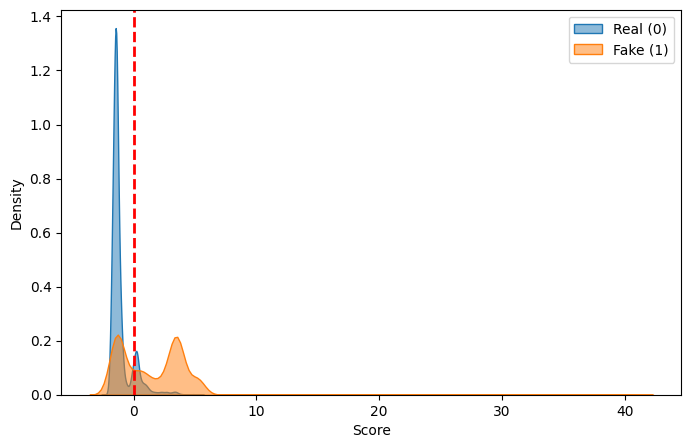


#------------ PER EXPERT ------------#



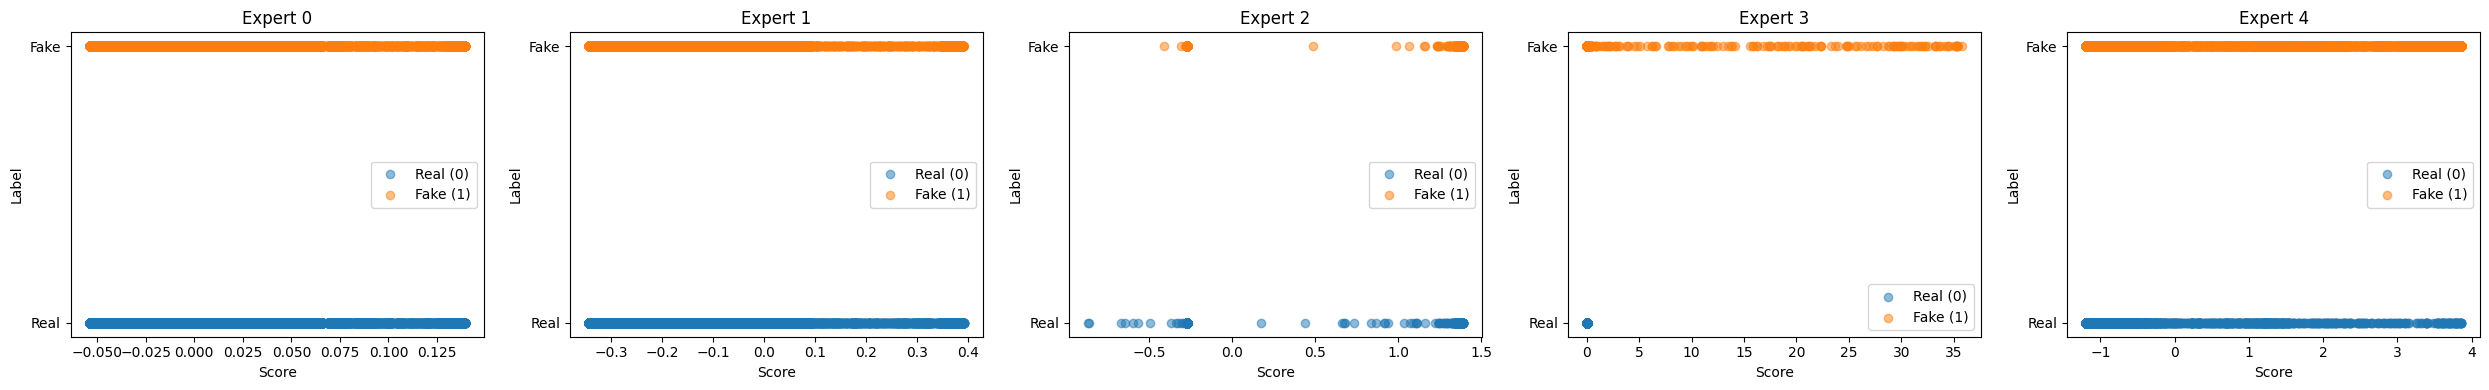

In [75]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/ALL"
labels = np.load(os.path.join(rootpath, "labels.npy"))

print("\n#--------- OVERALL ENSEMBLE ---------#\n")
scores = np.load(os.path.join(rootpath, "scores.npy"))
plot_distributions(scores, labels)
plt.show()

print("\n#------------ PER EXPERT ------------#\n")
all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
n_exp = all_logLR.shape[0]
fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

for i in range(n_exp):
    ax = axes[i] if n_exp > 1 else axes
    scores = all_logLR[i]

    plot_raw_scatter(scores, labels, ax=ax, metrics=False)
    ax.set_title(f"Expert {i}")

plt.tight_layout()
plt.show()


### Per attack 


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 84.98%, EER: 22.78%
Loaded 1898 samples
Real mean score: -1.1054
Fake mean score: 0.3788



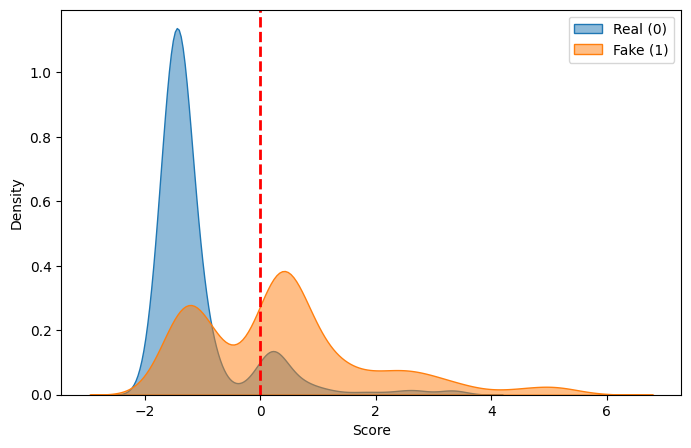


#------------ PER EXPERT (LogLR scores) ------------#



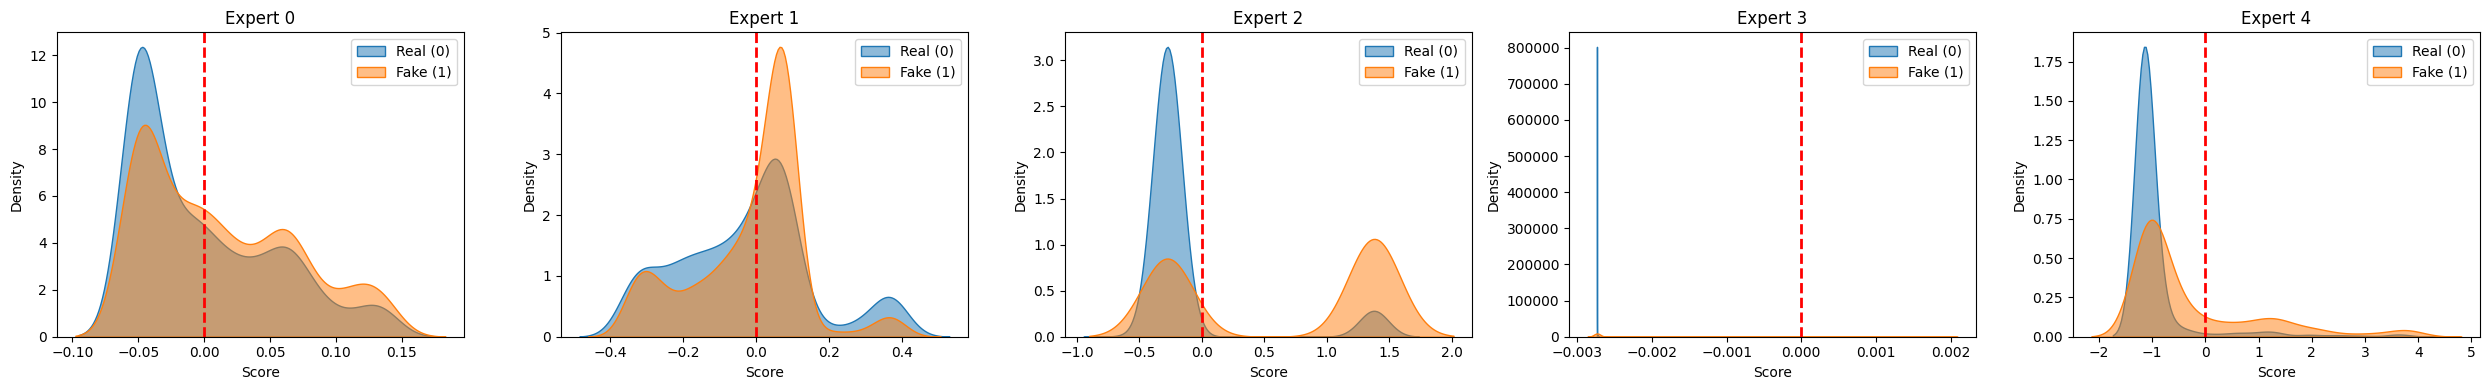


#------------ PER EXPERT (Scaled Logits) ------------#



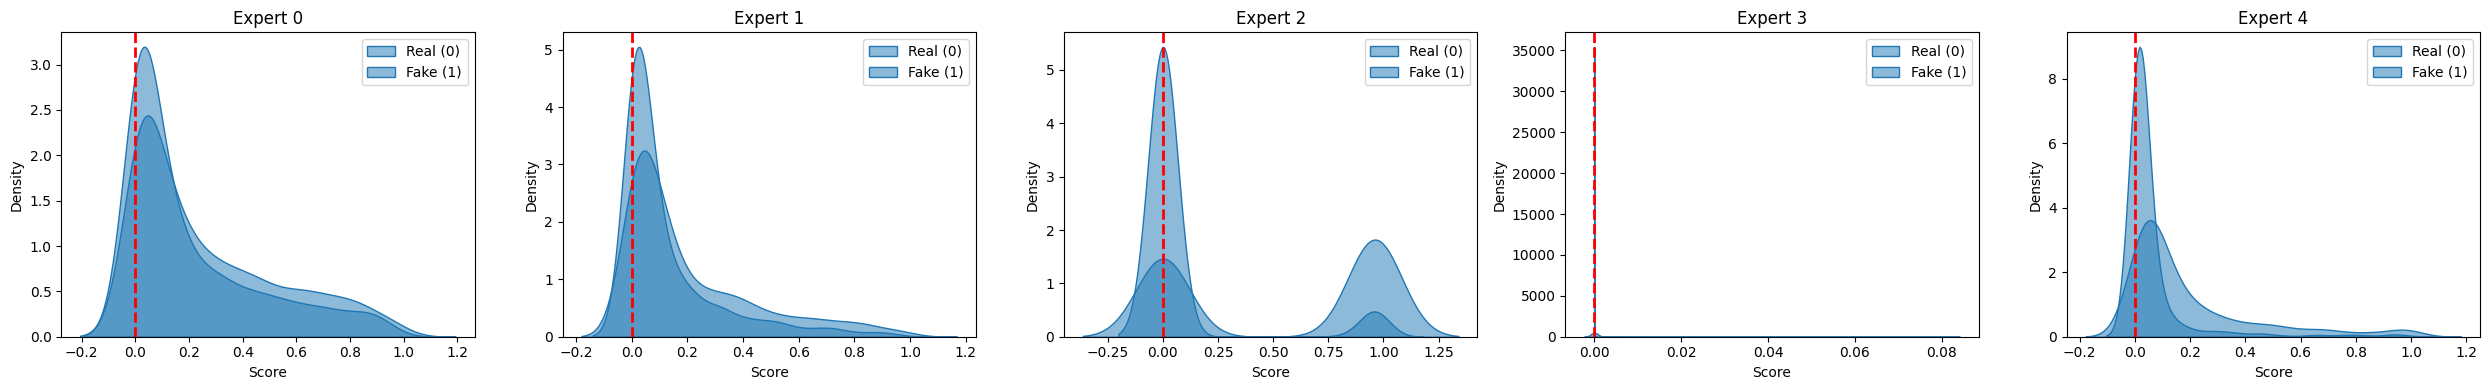


#------------ PER EXPERT (Raw Logits) ------------#



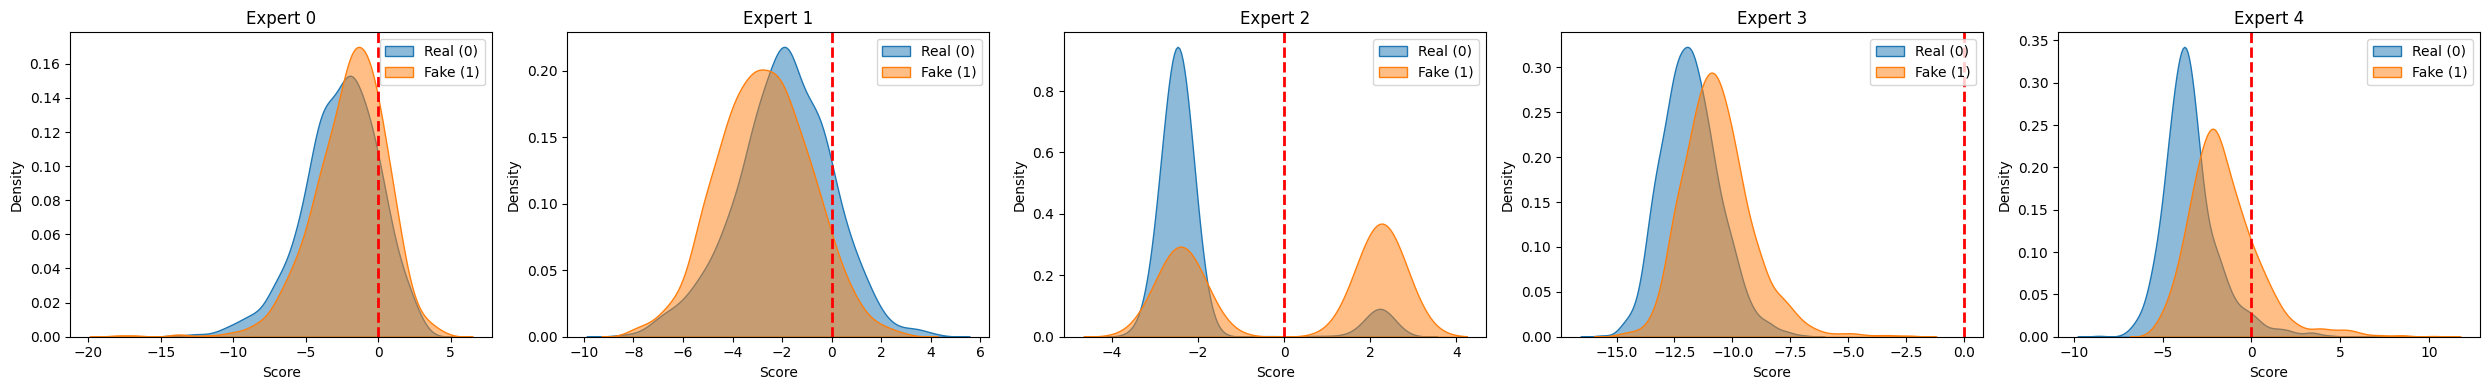


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 79.32%, EER: 33.26%
Loaded 1926 samples
Real mean score: -1.1055
Fake mean score: 1.1067



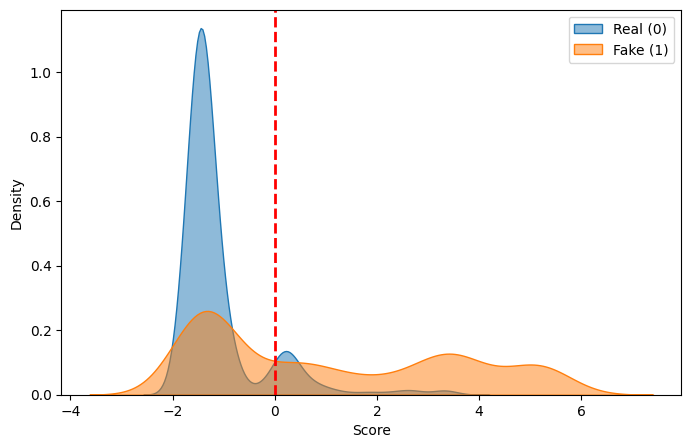


#------------ PER EXPERT (LogLR scores) ------------#



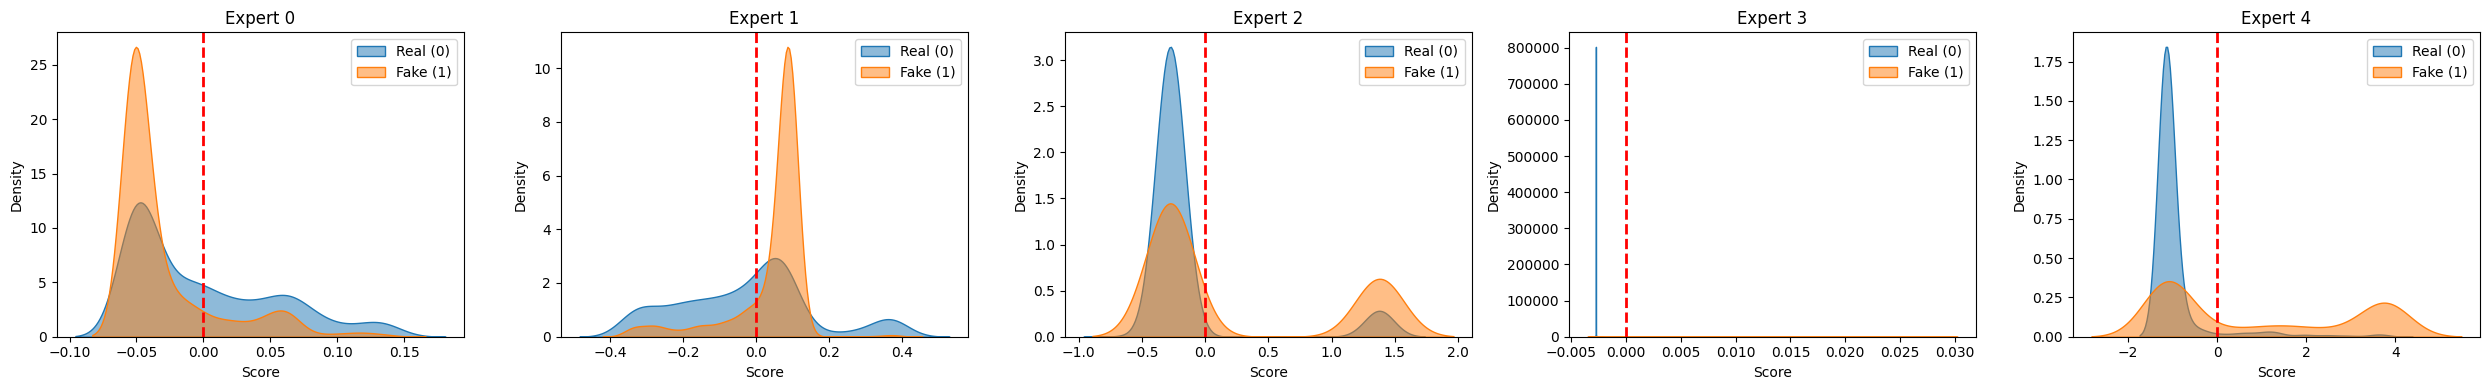


#------------ PER EXPERT (Scaled Logits) ------------#



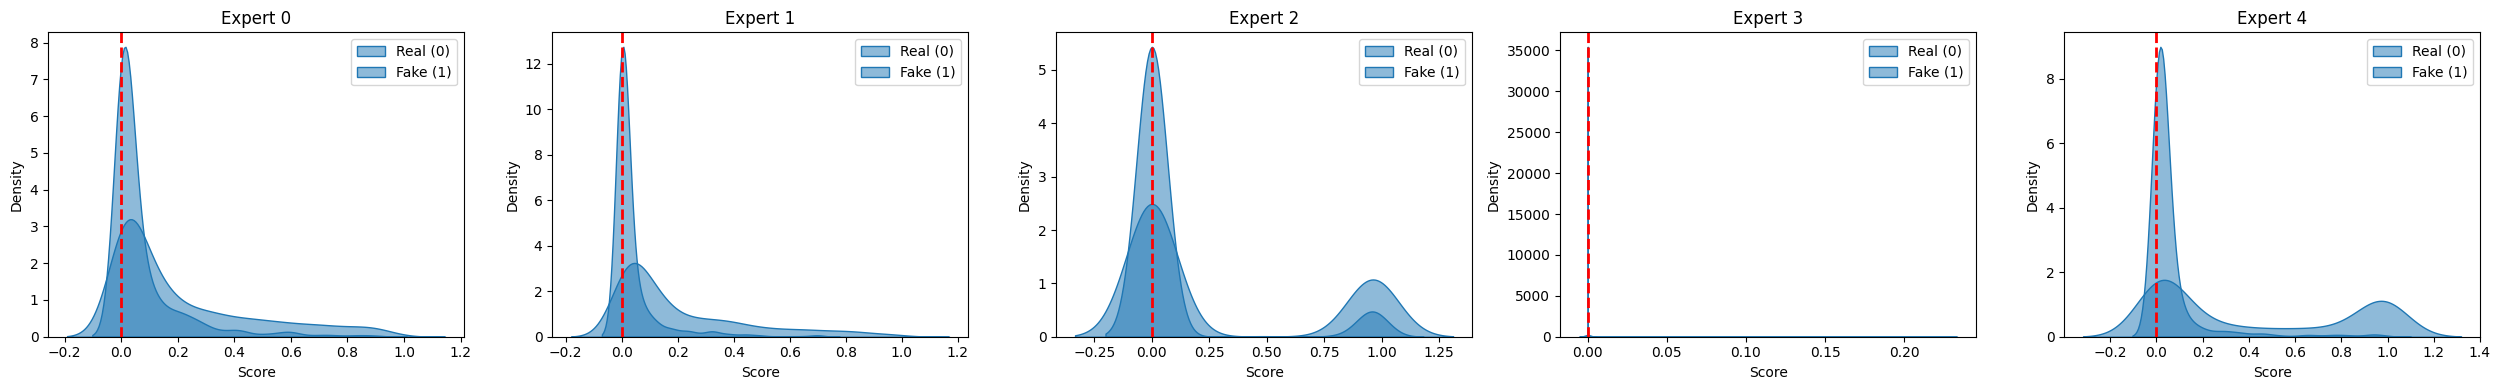


#------------ PER EXPERT (Raw Logits) ------------#



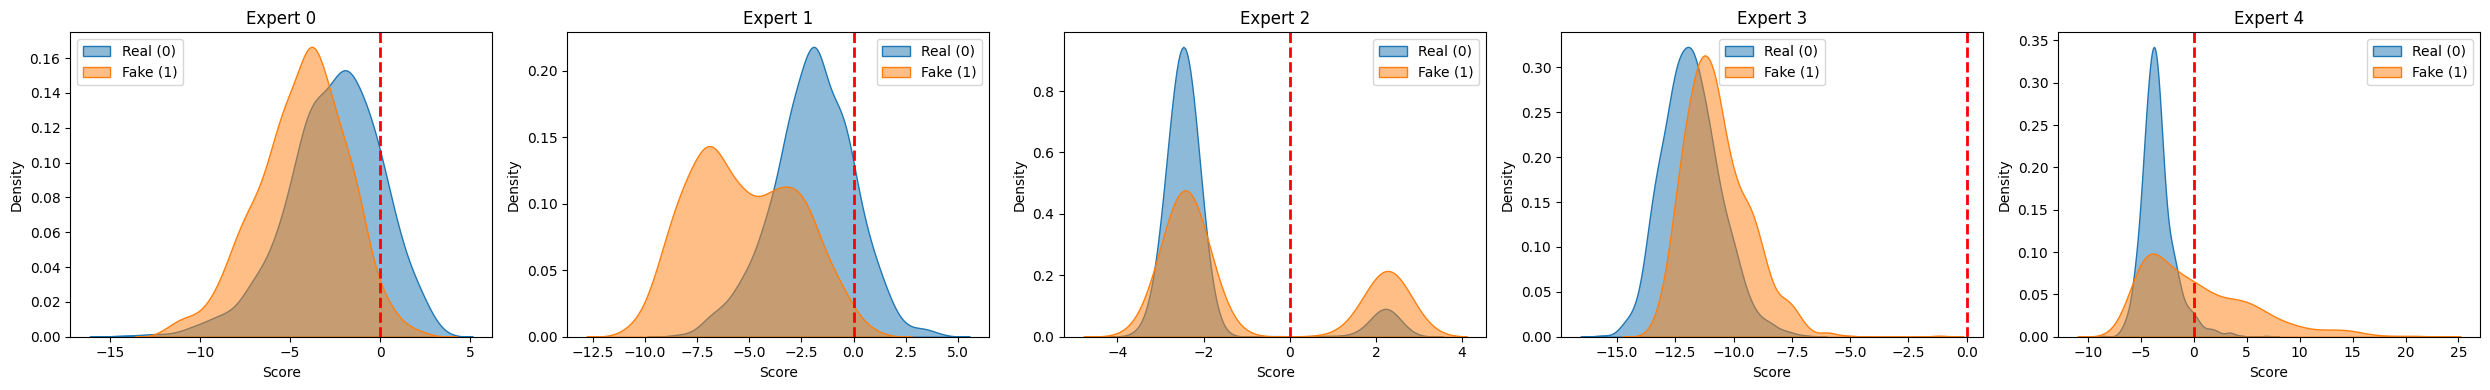


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 95.83%, EER: 12.54%
Loaded 1931 samples
Real mean score: -1.1055
Fake mean score: 2.4673



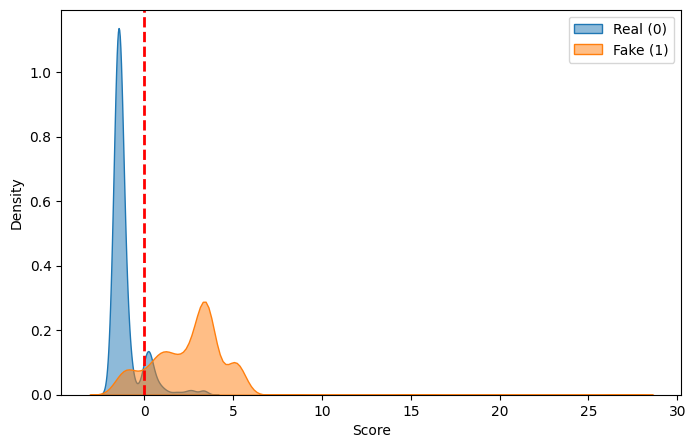


#------------ PER EXPERT (LogLR scores) ------------#



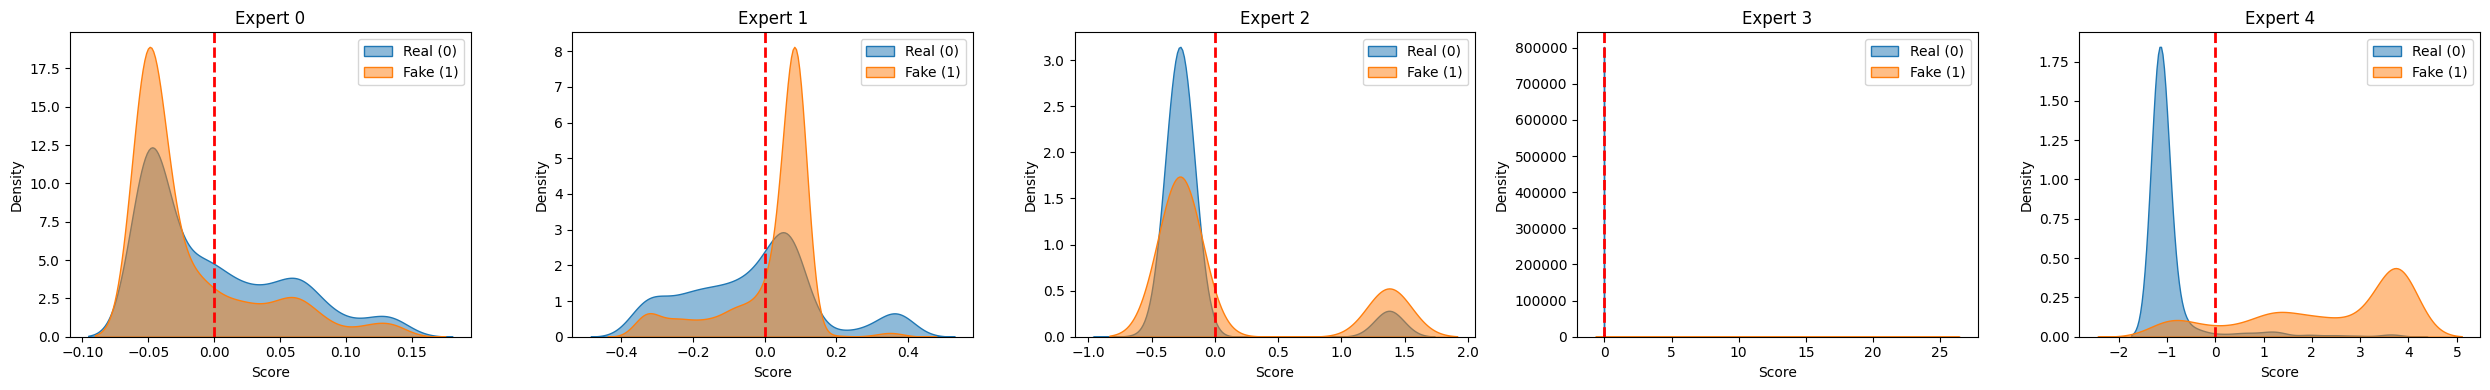


#------------ PER EXPERT (Scaled Logits) ------------#



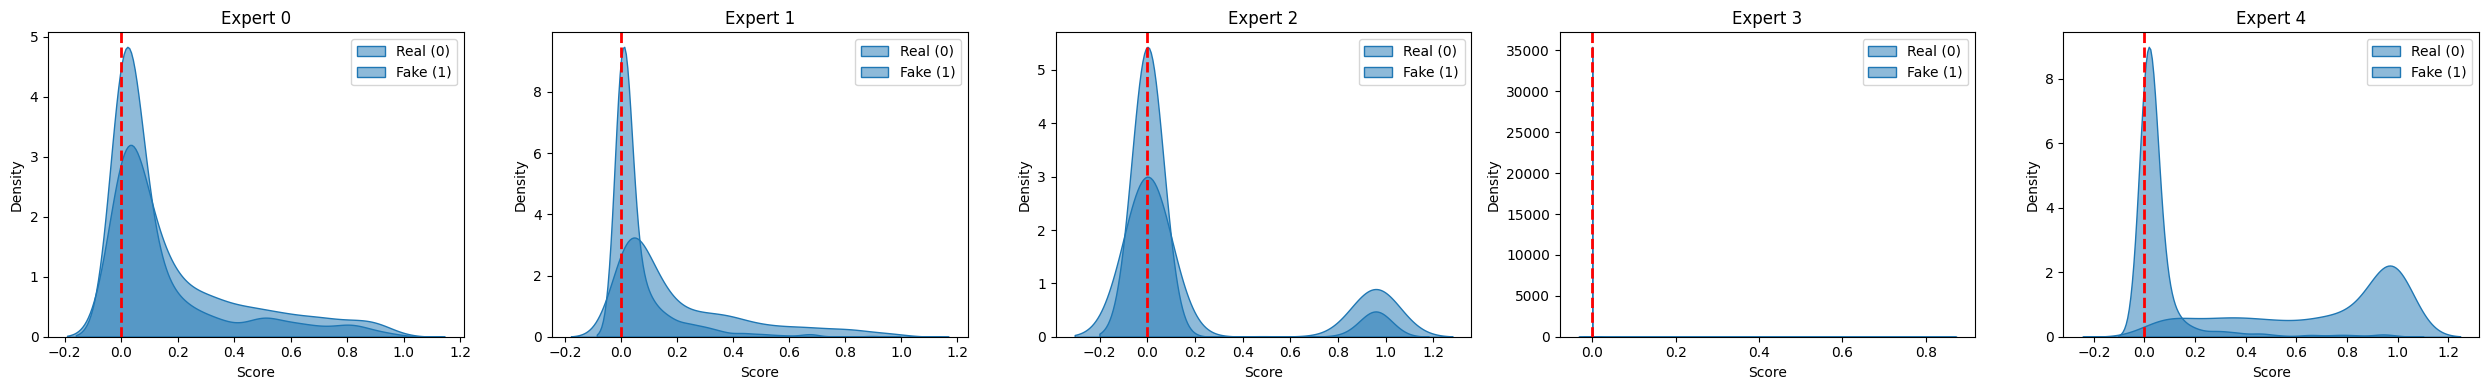


#------------ PER EXPERT (Raw Logits) ------------#



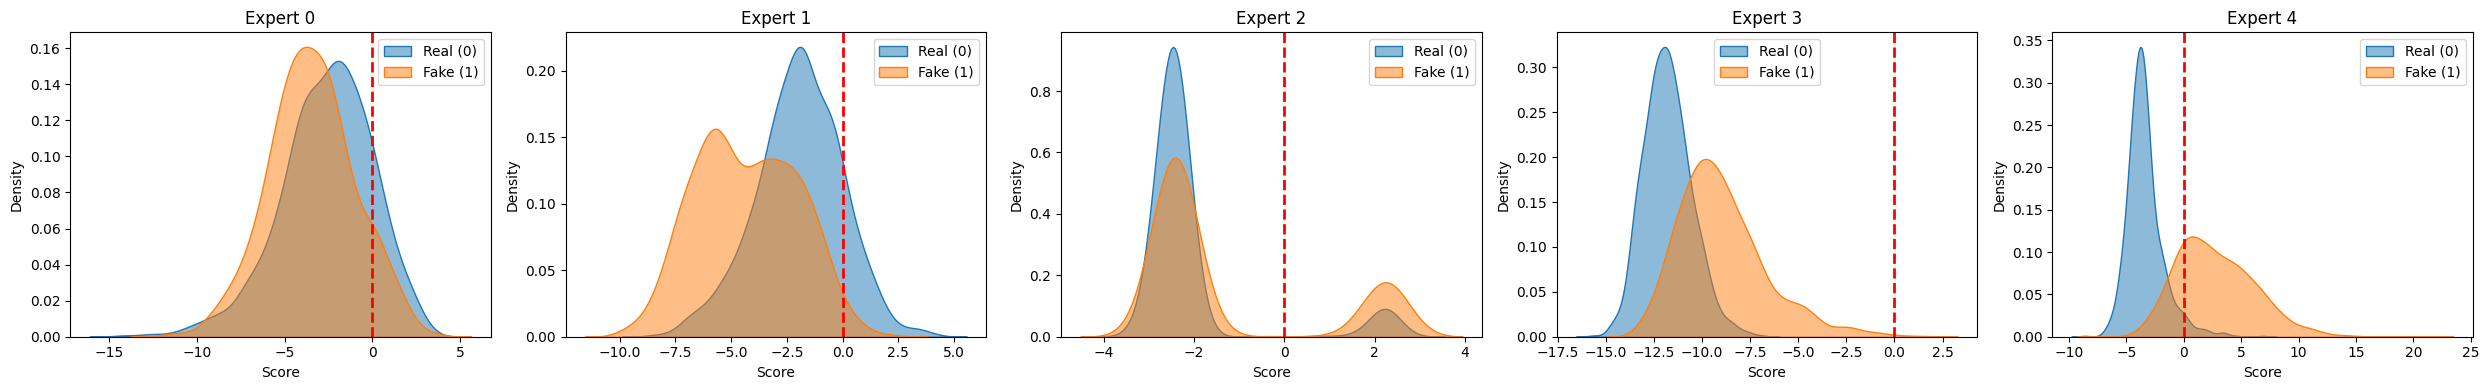


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 88.36%, EER: 20.30%
Loaded 1880 samples
Real mean score: -1.1054
Fake mean score: 2.2414



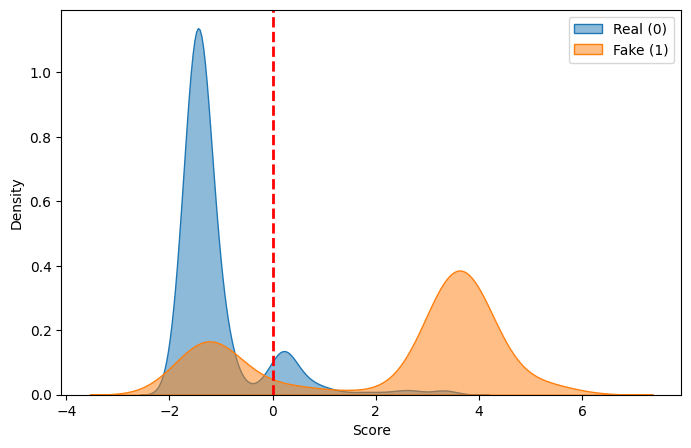


#------------ PER EXPERT (LogLR scores) ------------#



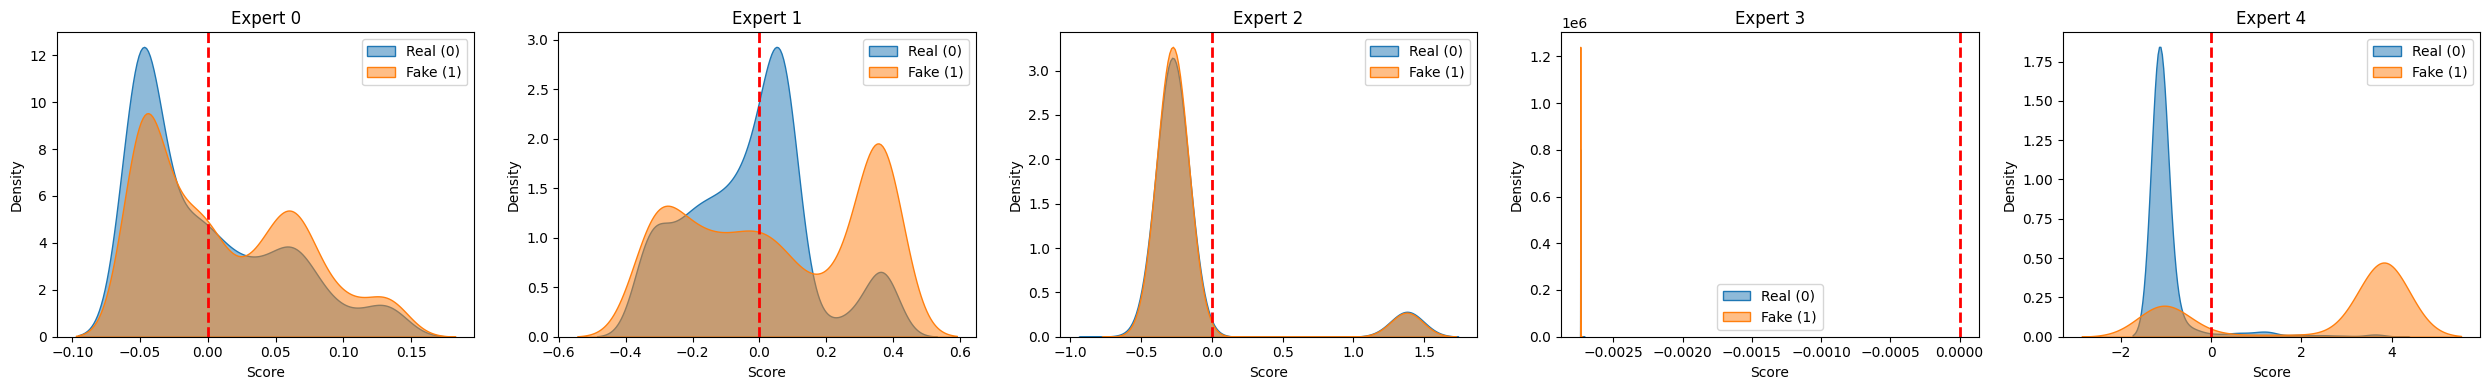


#------------ PER EXPERT (Scaled Logits) ------------#



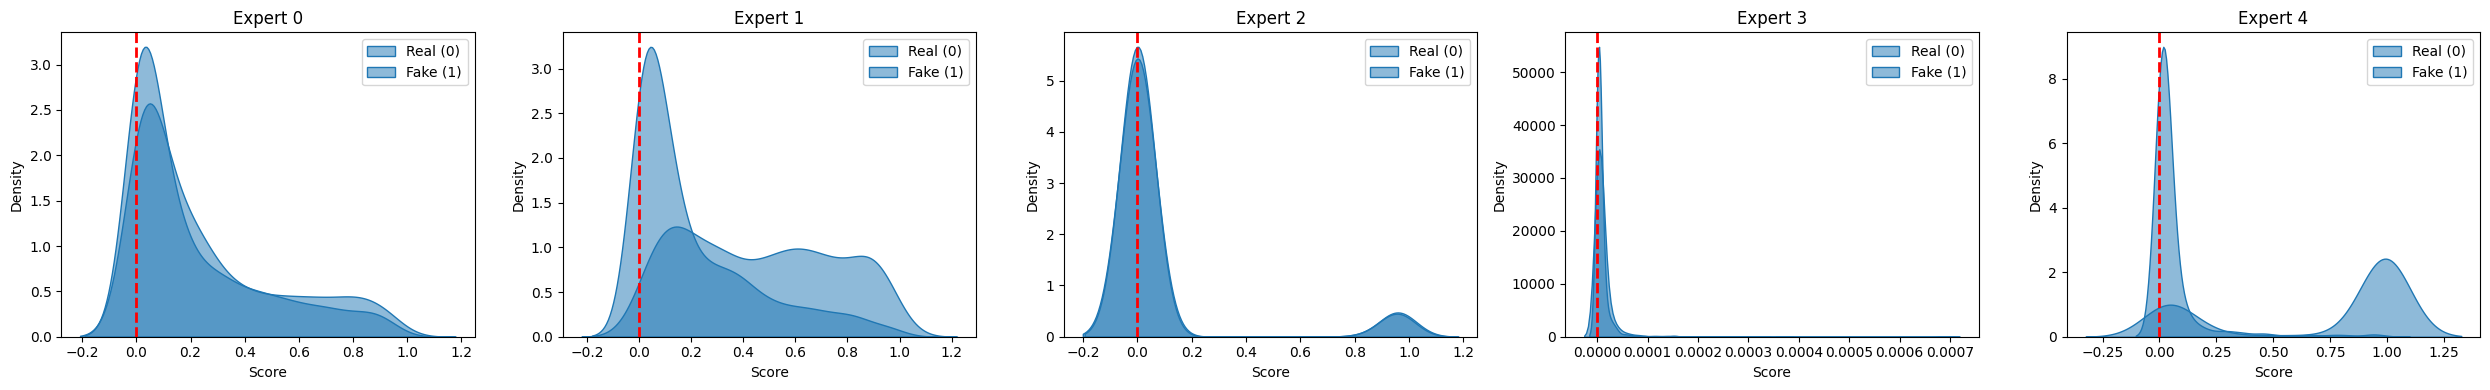


#------------ PER EXPERT (Raw Logits) ------------#



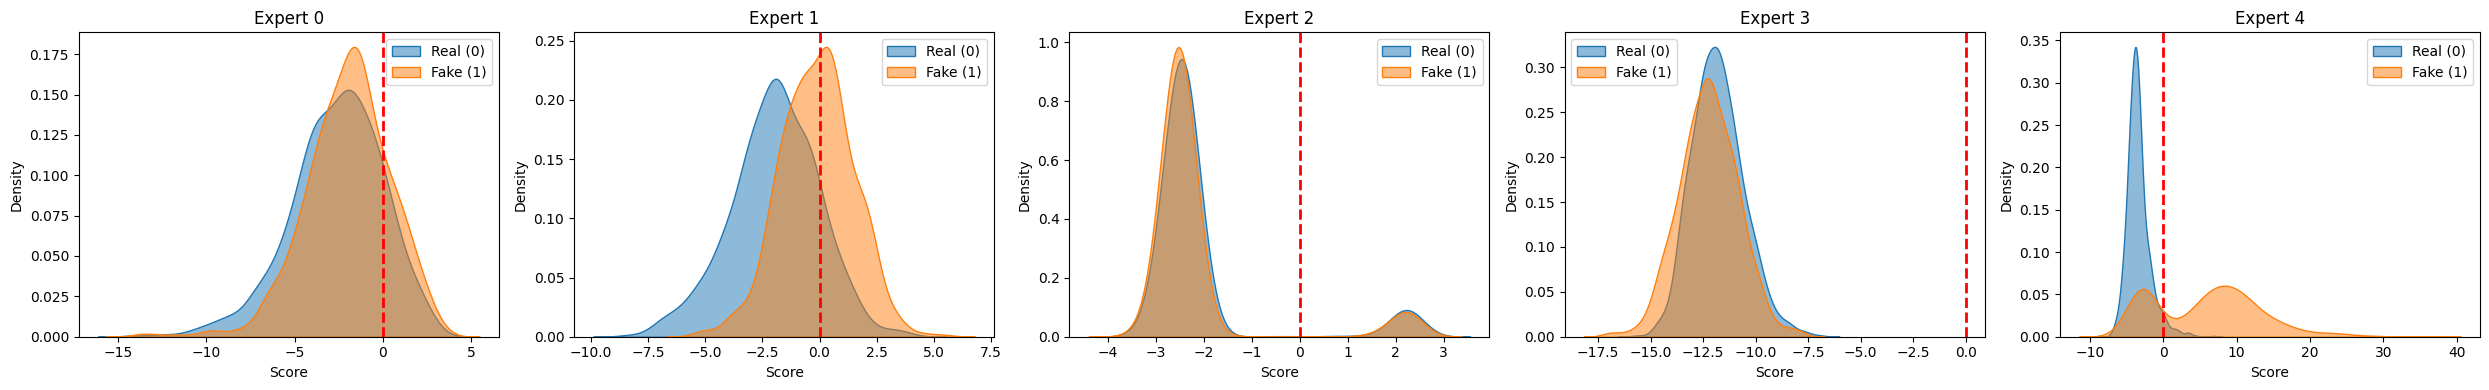


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 64.30%, EER: 40.17%
Loaded 1940 samples
Real mean score: -1.1054
Fake mean score: -0.9481



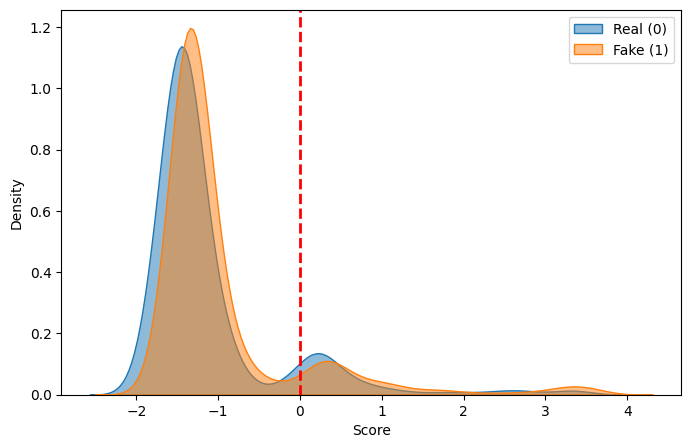


#------------ PER EXPERT (LogLR scores) ------------#



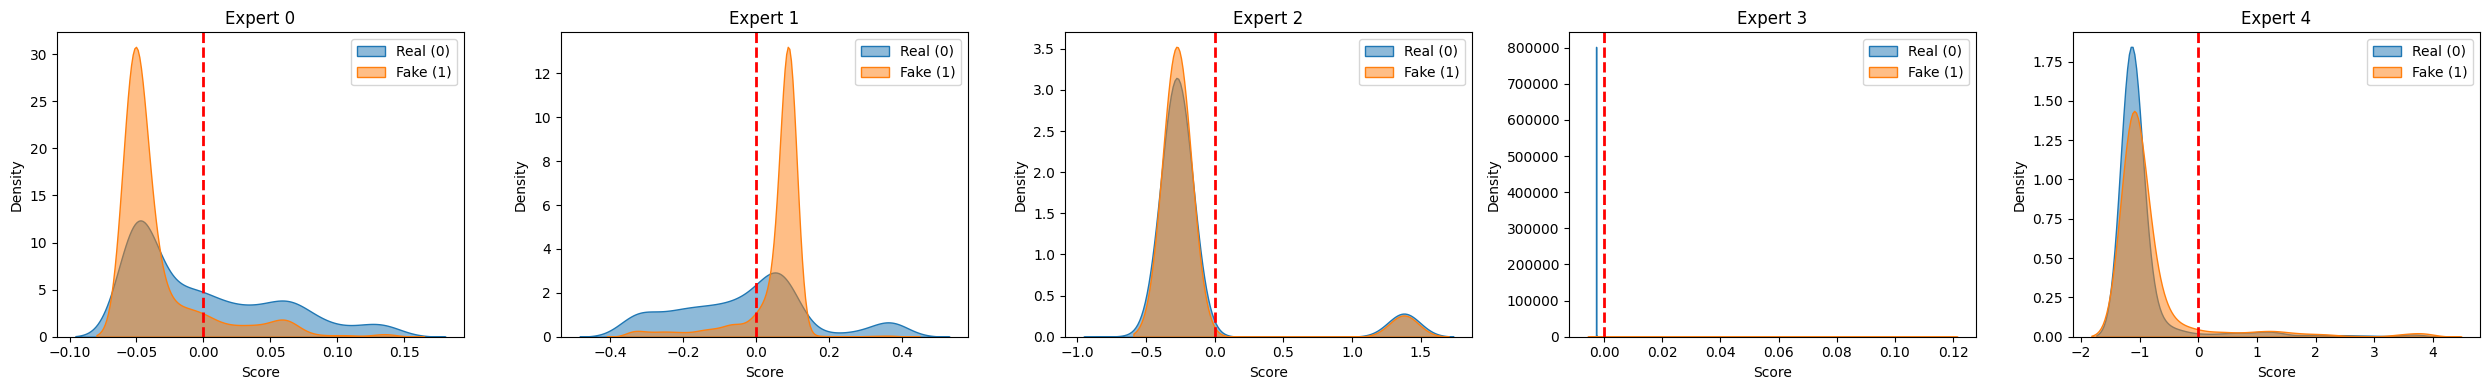


#------------ PER EXPERT (Scaled Logits) ------------#



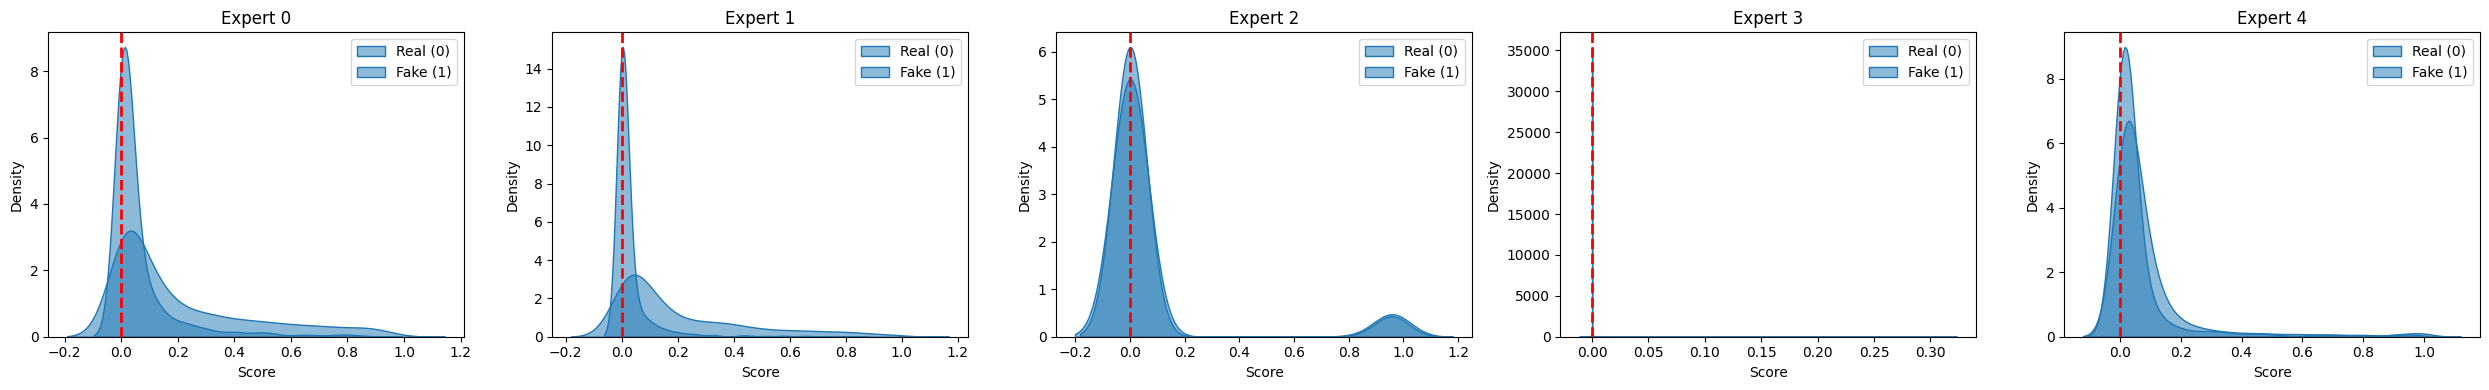


#------------ PER EXPERT (Raw Logits) ------------#



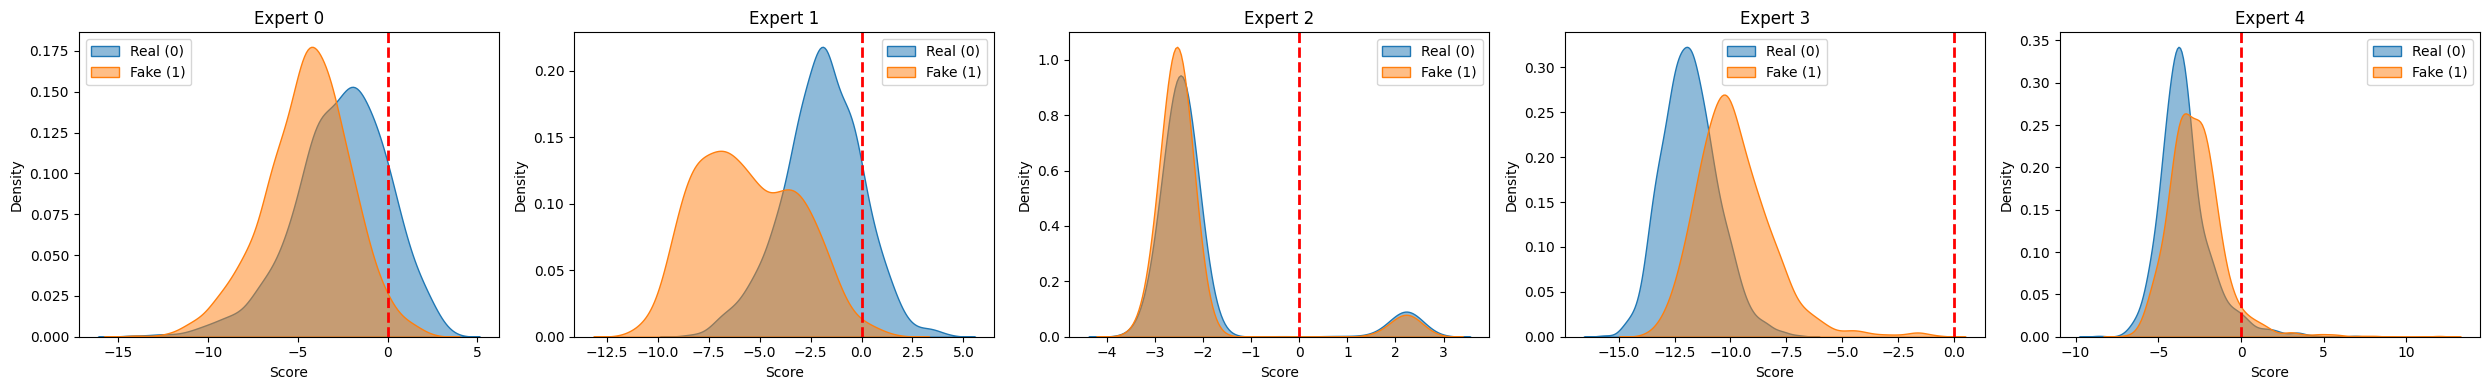


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 96.35%, EER: 11.90%
Loaded 1933 samples
Real mean score: -1.1055
Fake mean score: 3.5308



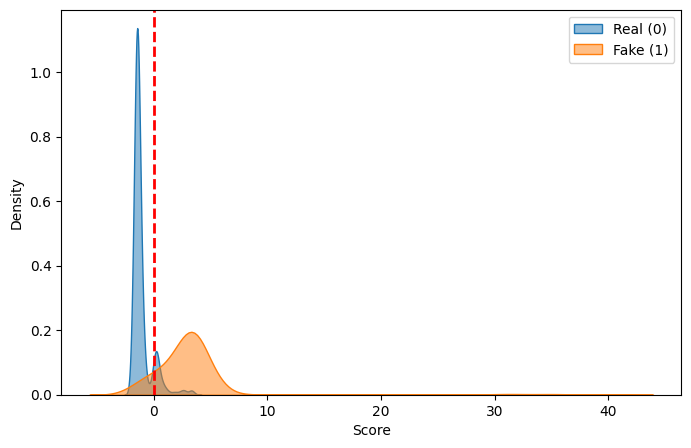


#------------ PER EXPERT (LogLR scores) ------------#



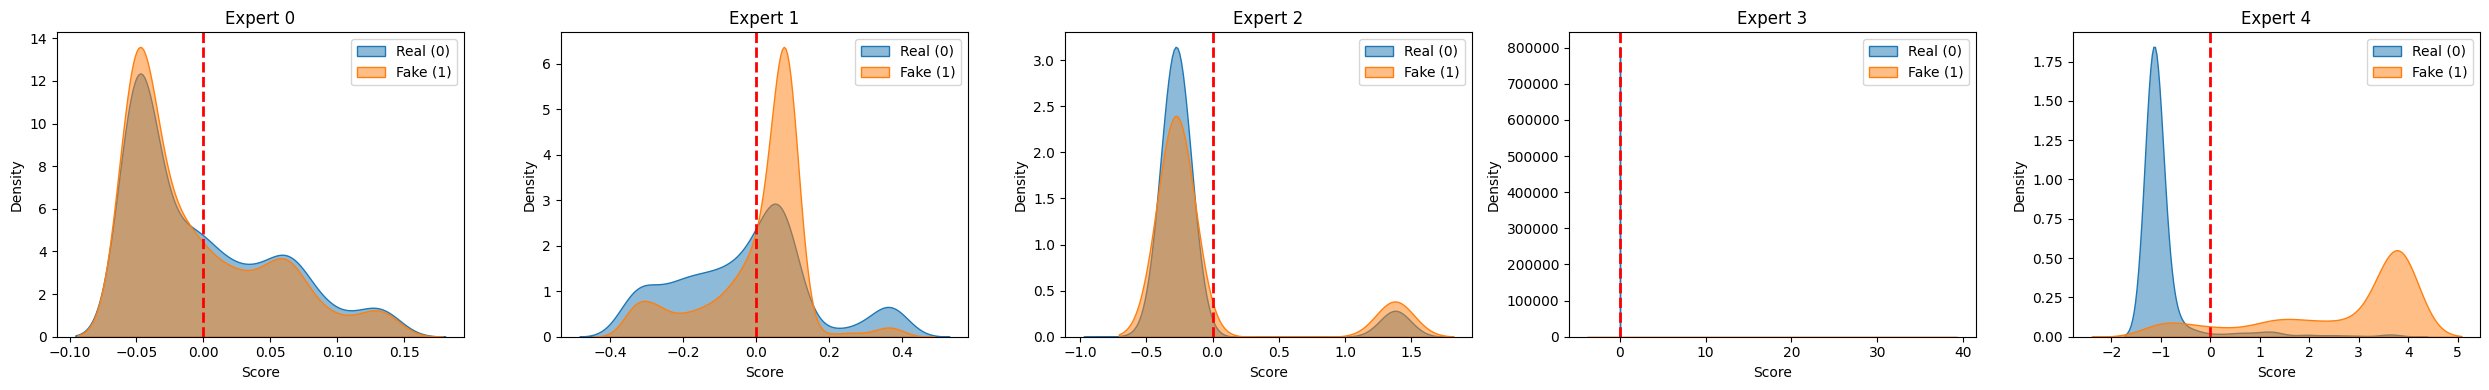


#------------ PER EXPERT (Scaled Logits) ------------#



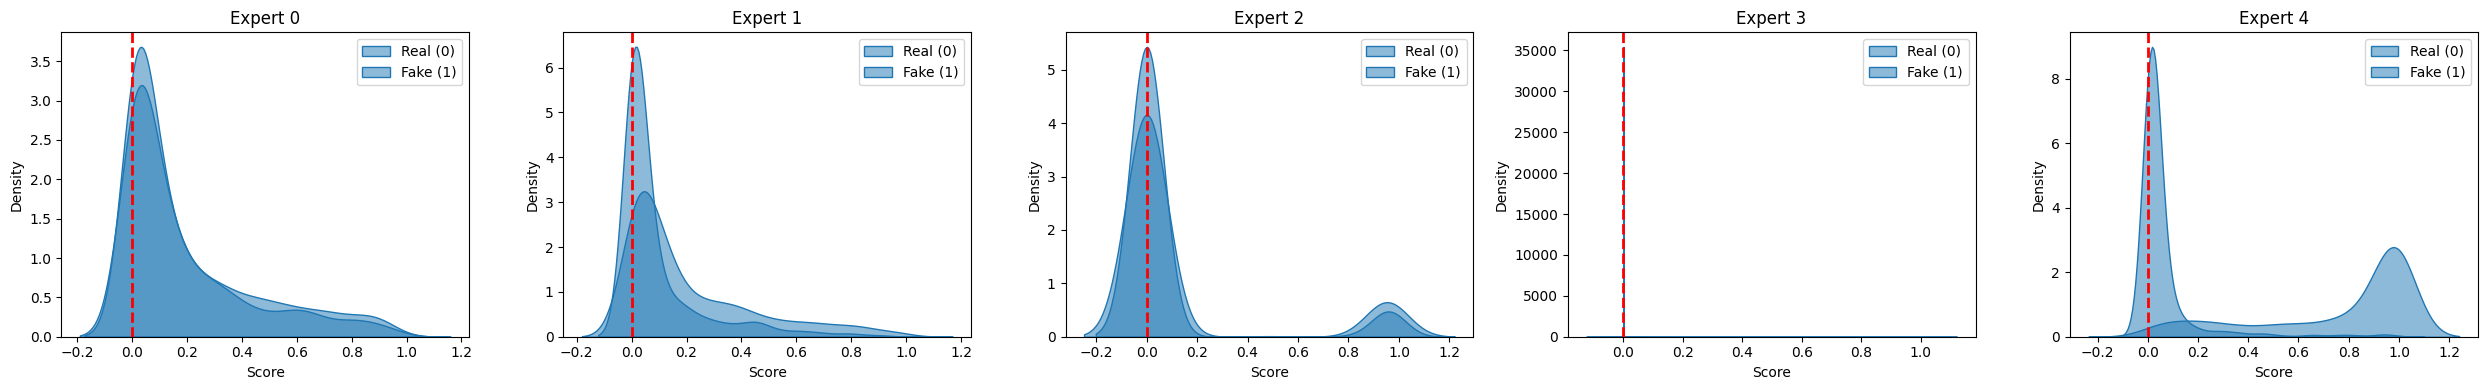


#------------ PER EXPERT (Raw Logits) ------------#



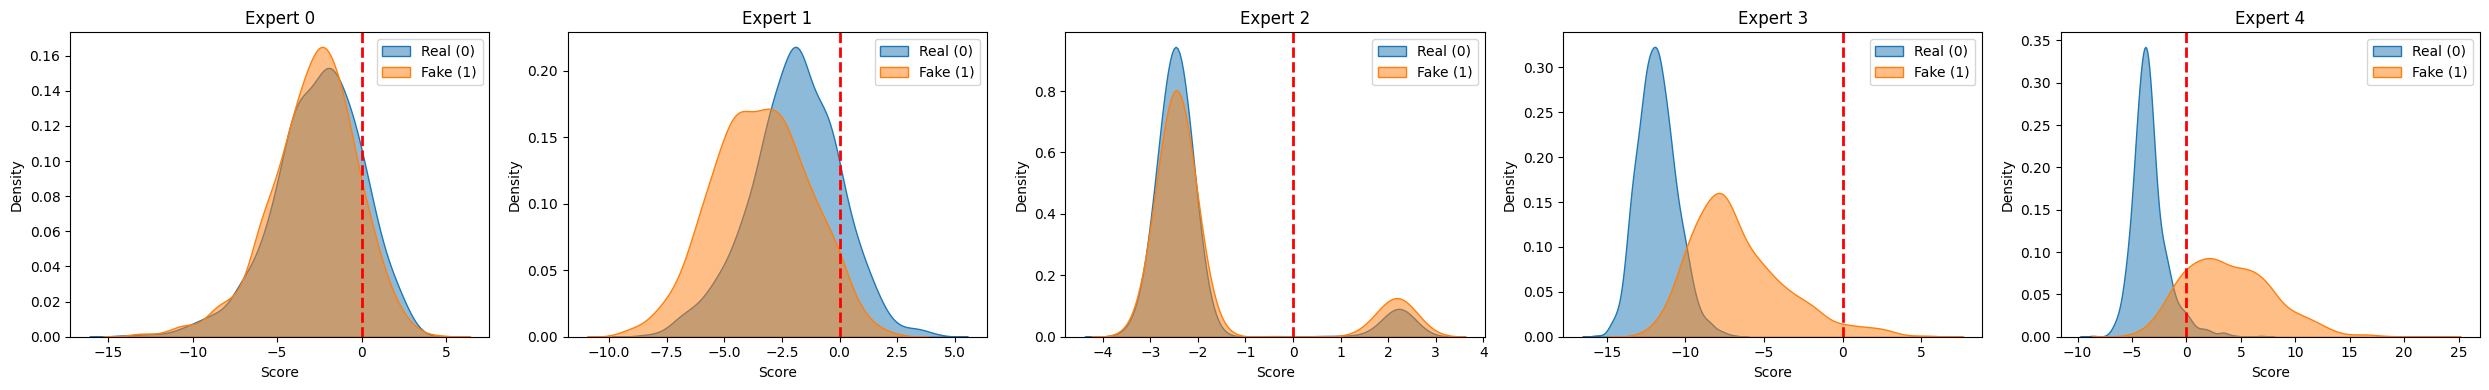


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 97.26%, EER: 9.12%
Loaded 1939 samples
Real mean score: -1.1054
Fake mean score: 4.7371



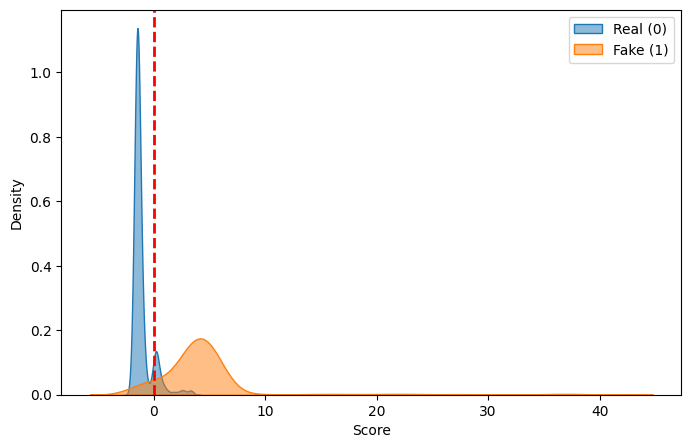


#------------ PER EXPERT (LogLR scores) ------------#



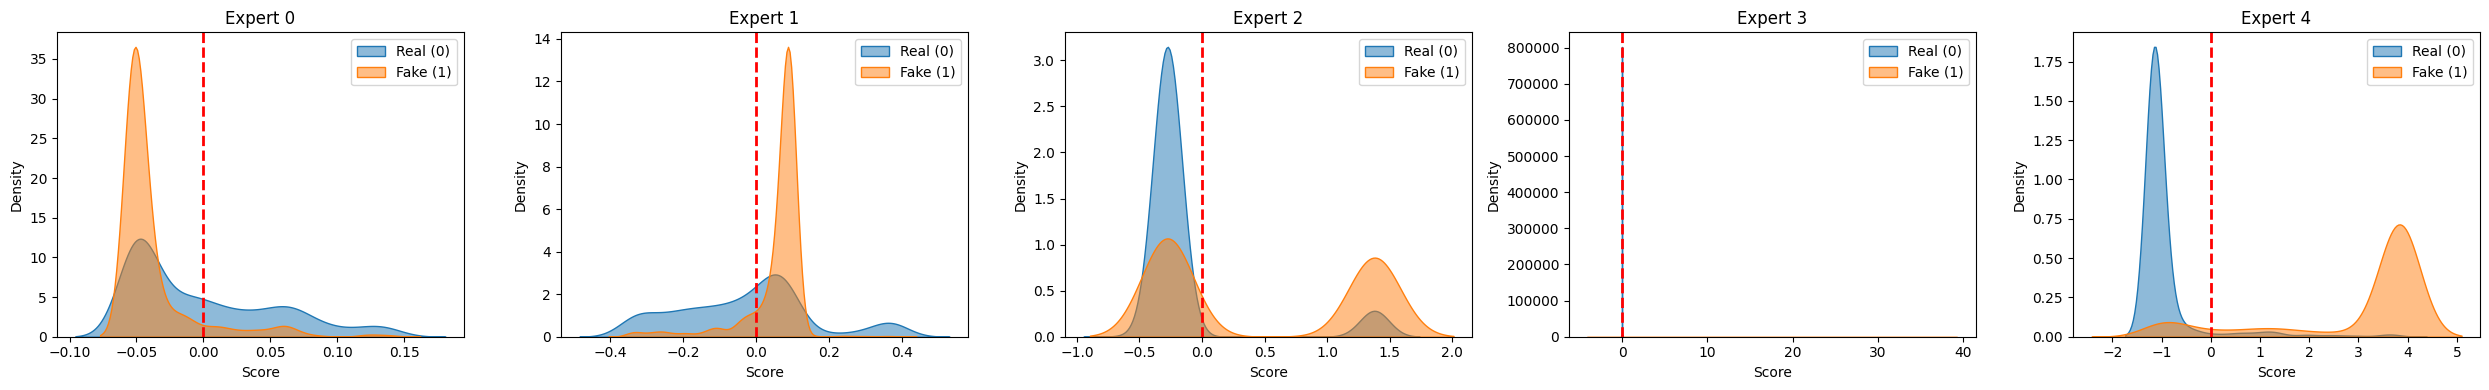


#------------ PER EXPERT (Scaled Logits) ------------#



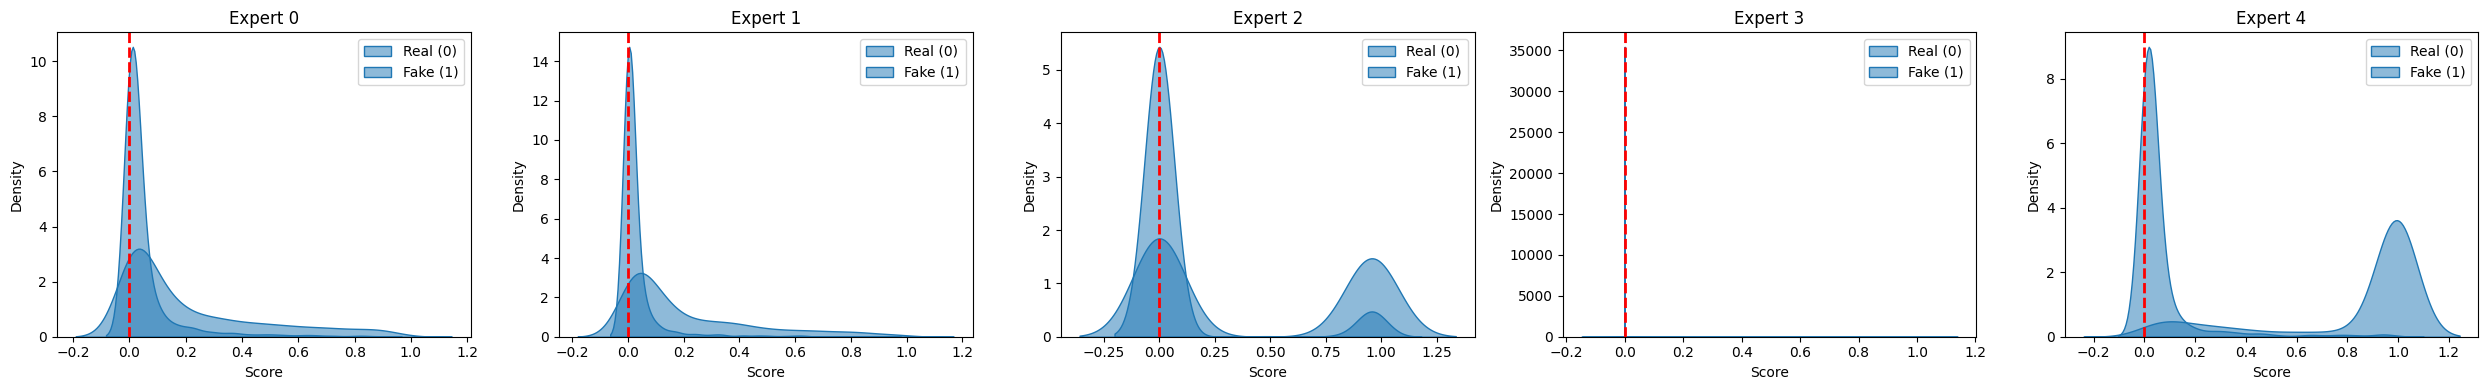


#------------ PER EXPERT (Raw Logits) ------------#



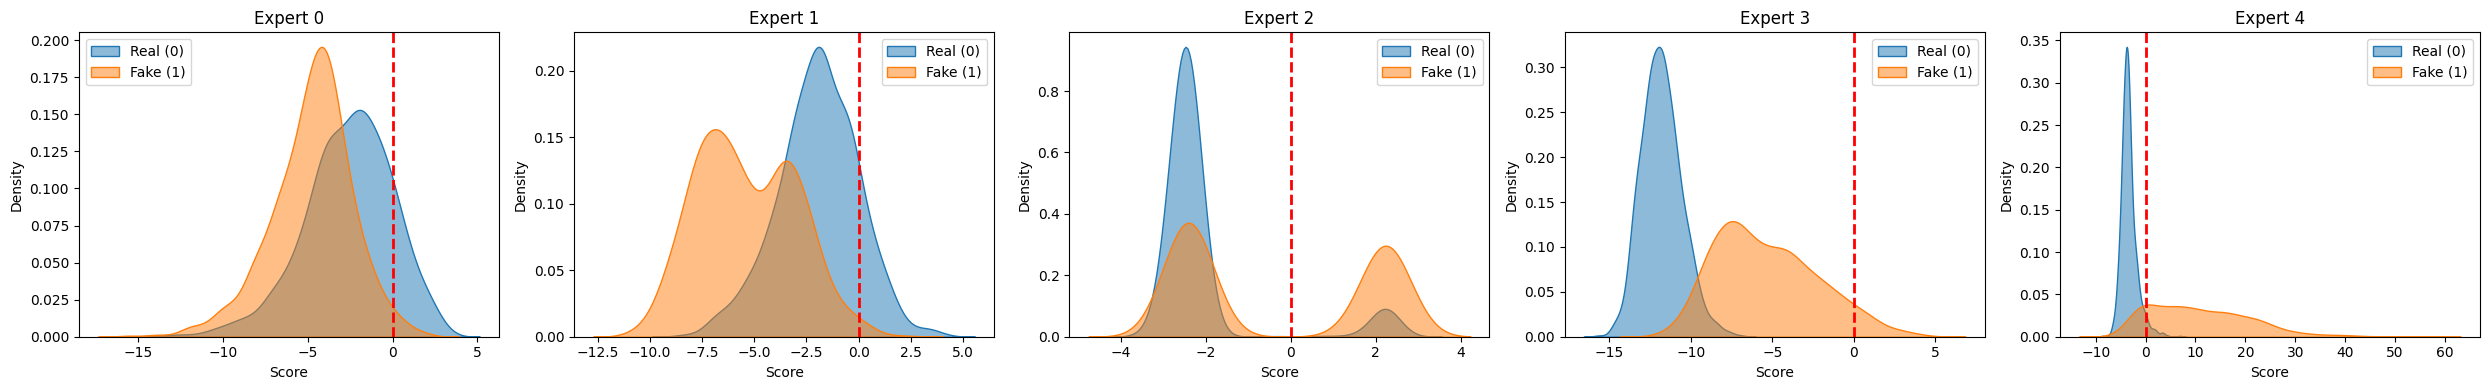


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 54.47%, EER: 46.23%
Loaded 1898 samples
Real mean score: -1.1054
Fake mean score: -1.0499



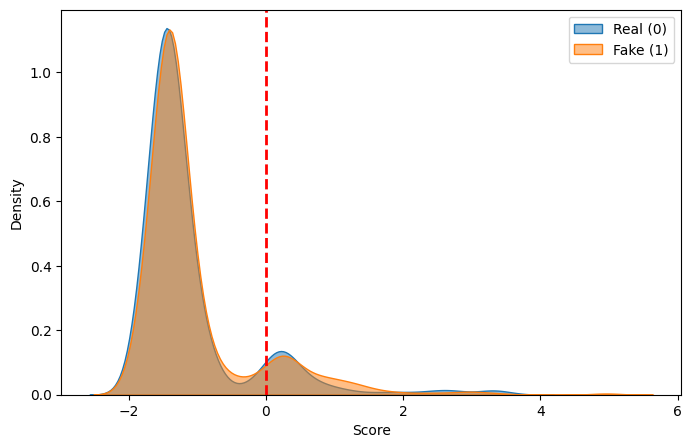


#------------ PER EXPERT (LogLR scores) ------------#



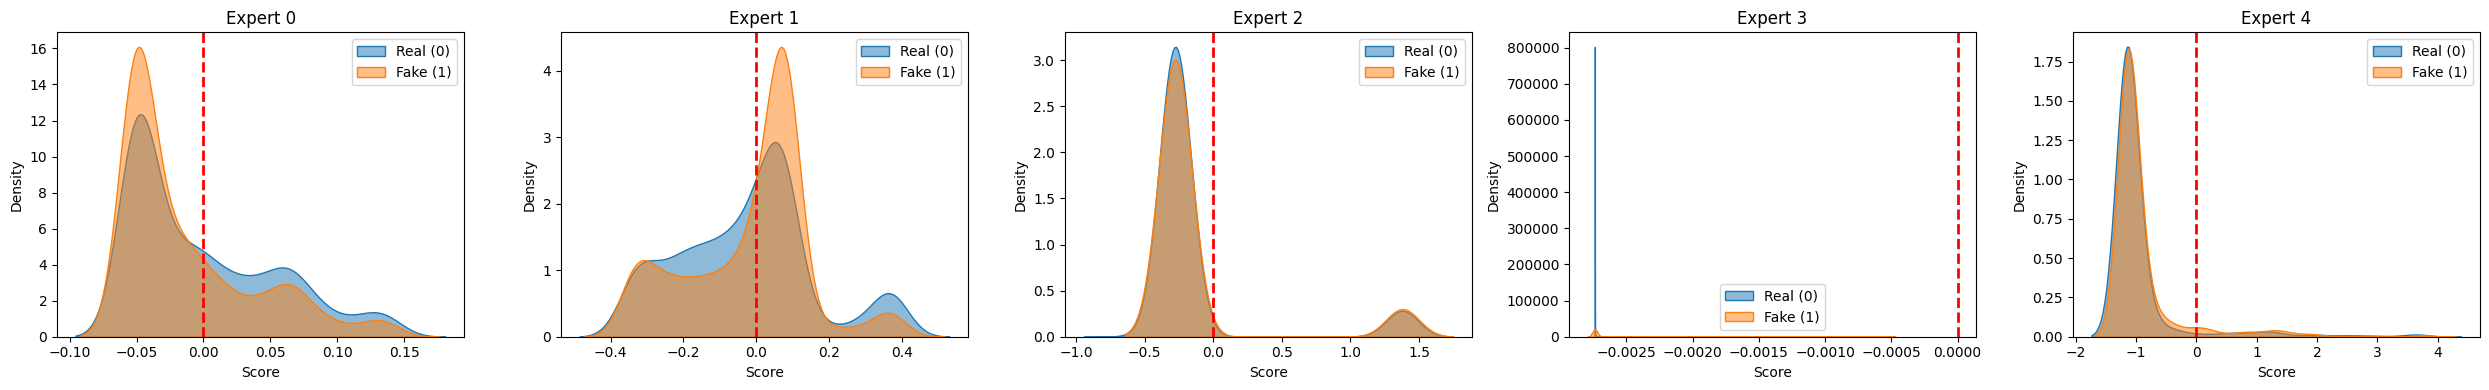


#------------ PER EXPERT (Scaled Logits) ------------#



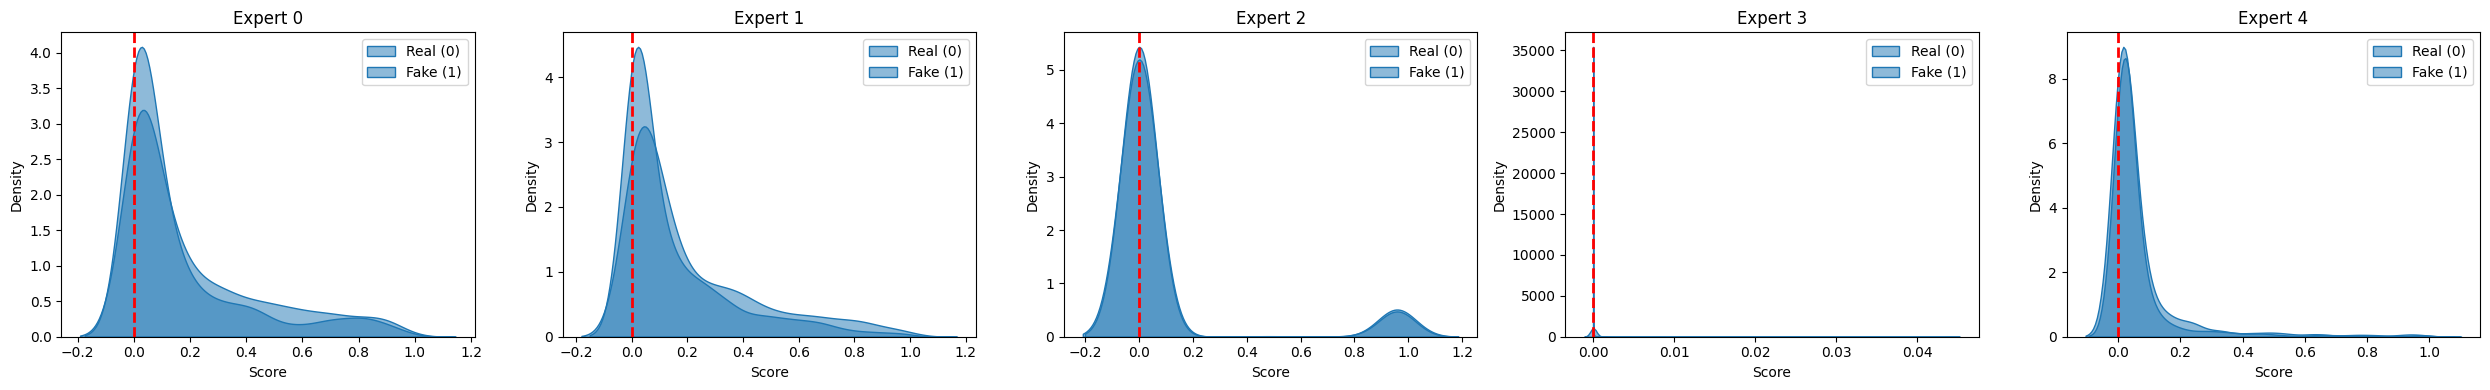


#------------ PER EXPERT (Raw Logits) ------------#



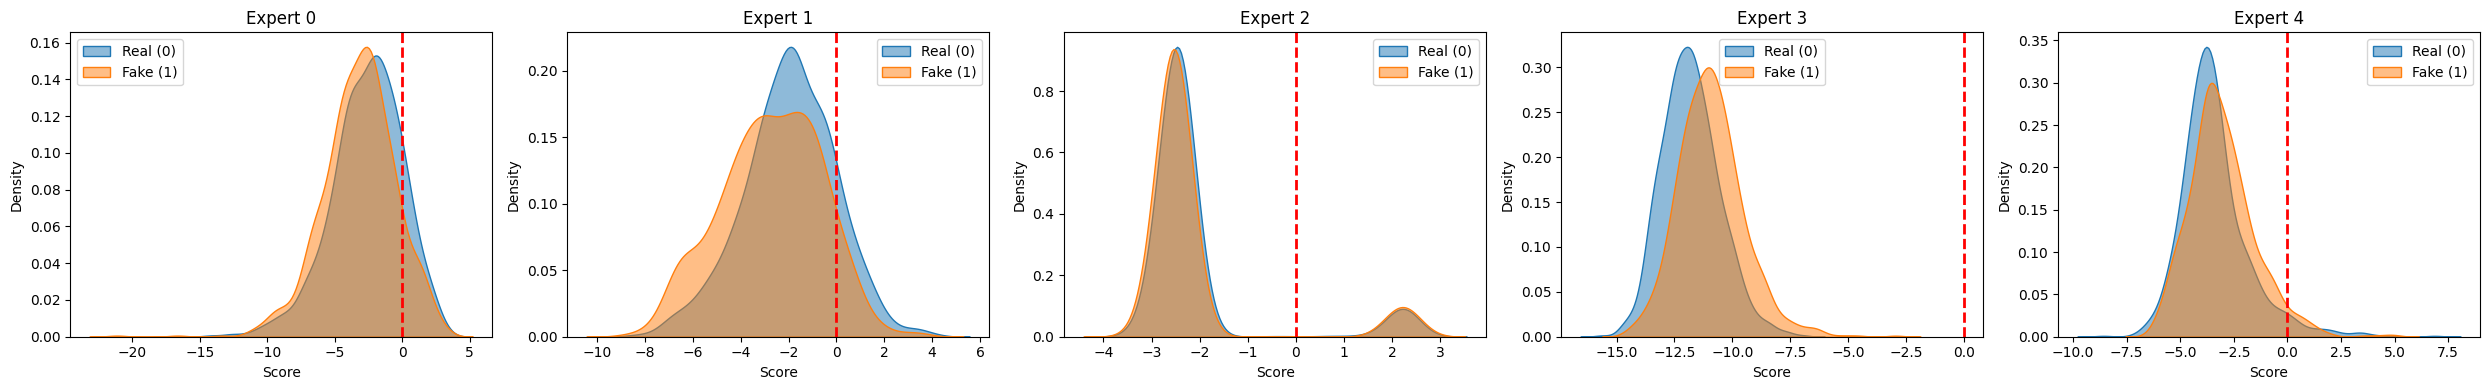


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 84.25%, EER: 26.22%
Loaded 1902 samples
Real mean score: -1.1055
Fake mean score: 1.6933



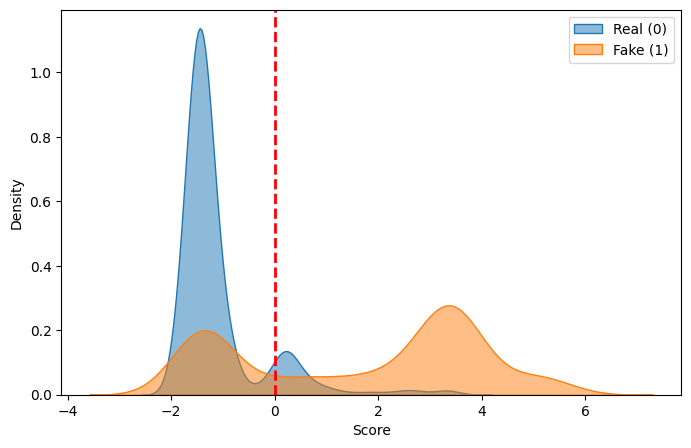


#------------ PER EXPERT (LogLR scores) ------------#



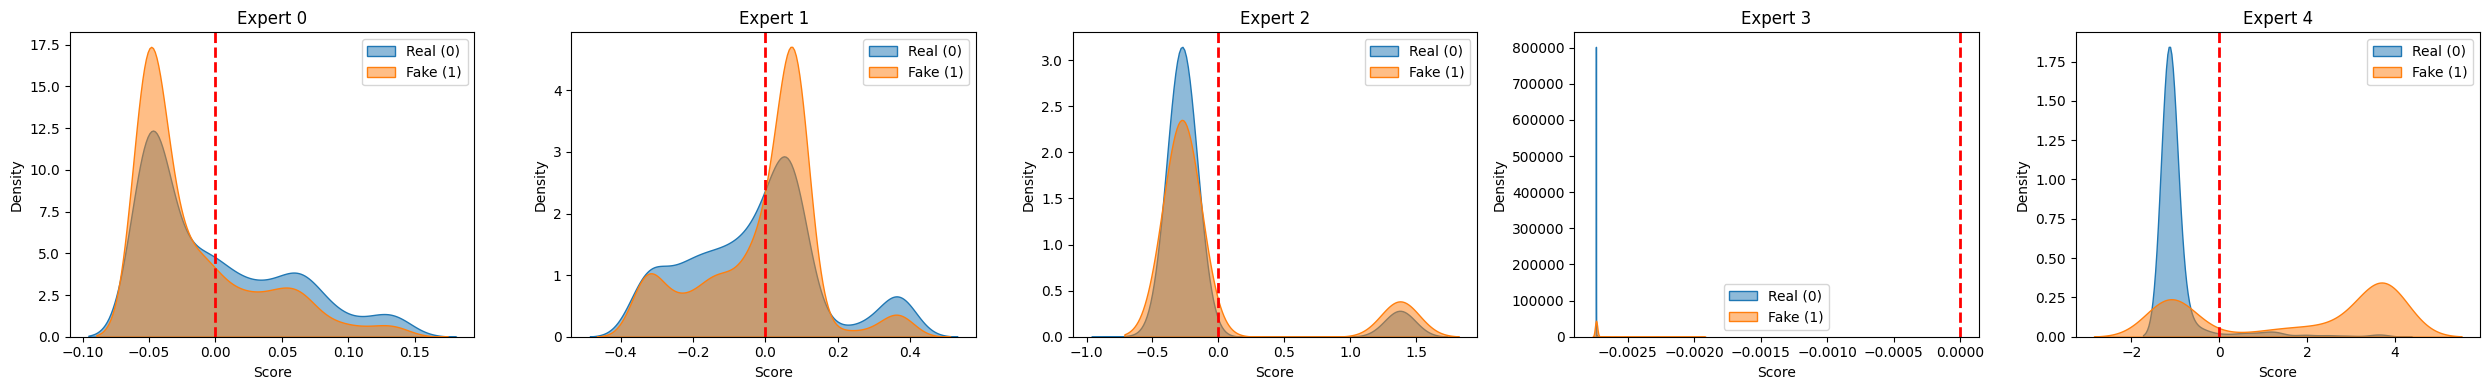


#------------ PER EXPERT (Scaled Logits) ------------#



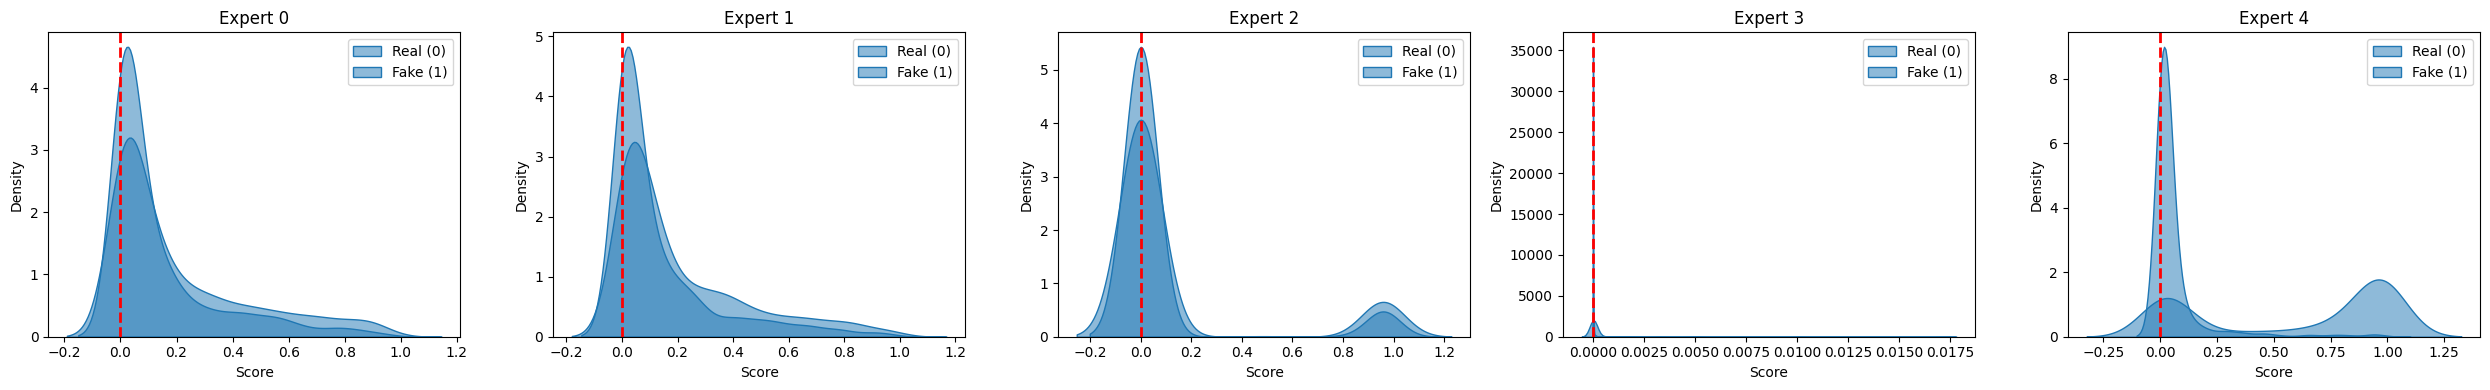


#------------ PER EXPERT (Raw Logits) ------------#



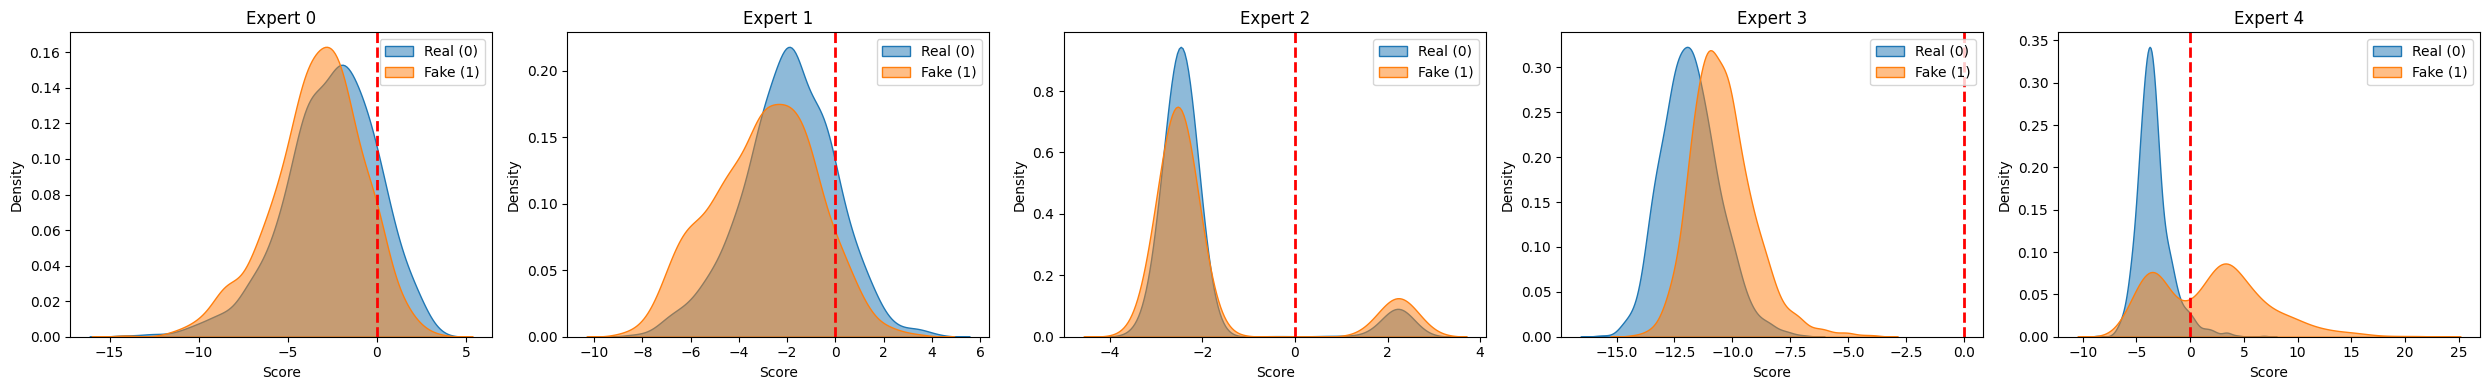


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 88.48%, EER: 20.11%
Loaded 1876 samples
Real mean score: -1.1054
Fake mean score: 2.3688



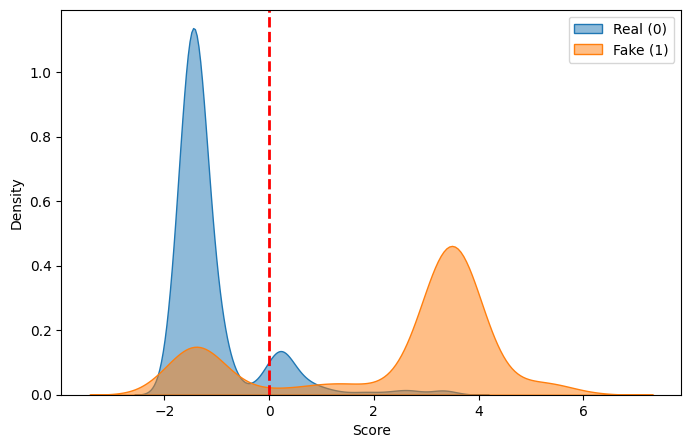


#------------ PER EXPERT (LogLR scores) ------------#



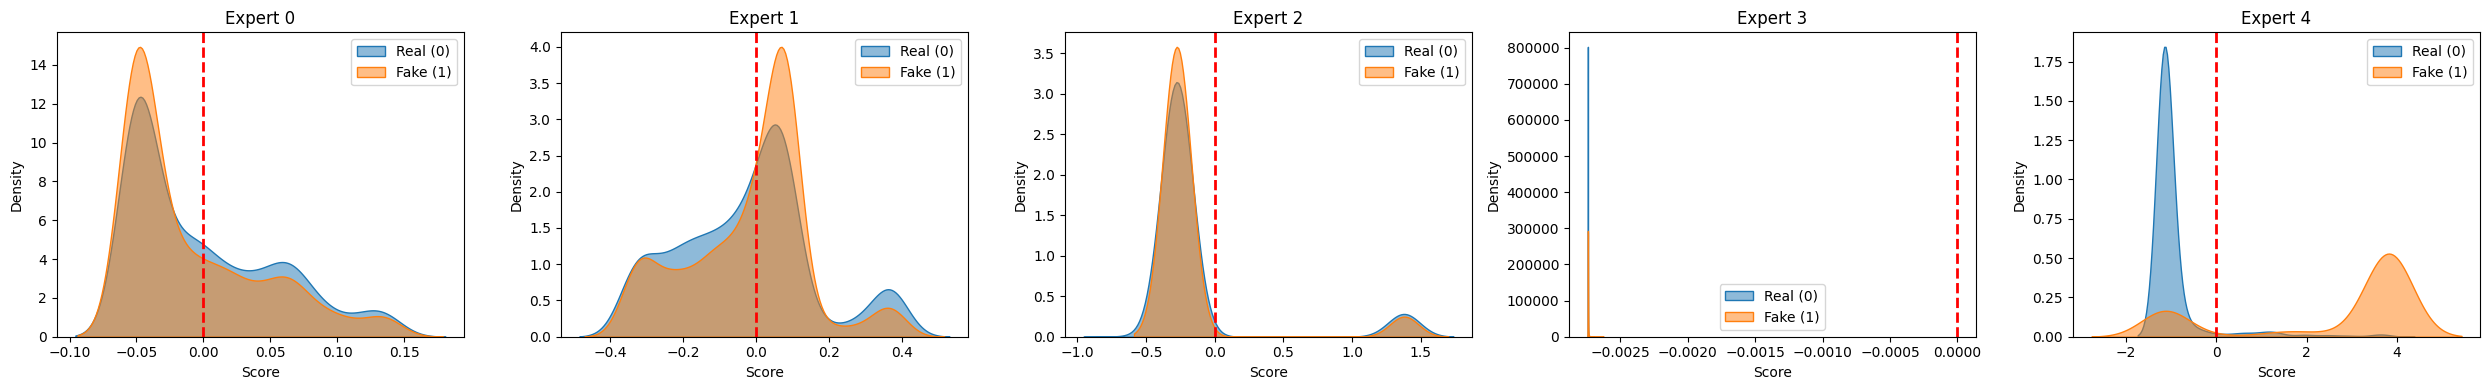


#------------ PER EXPERT (Scaled Logits) ------------#



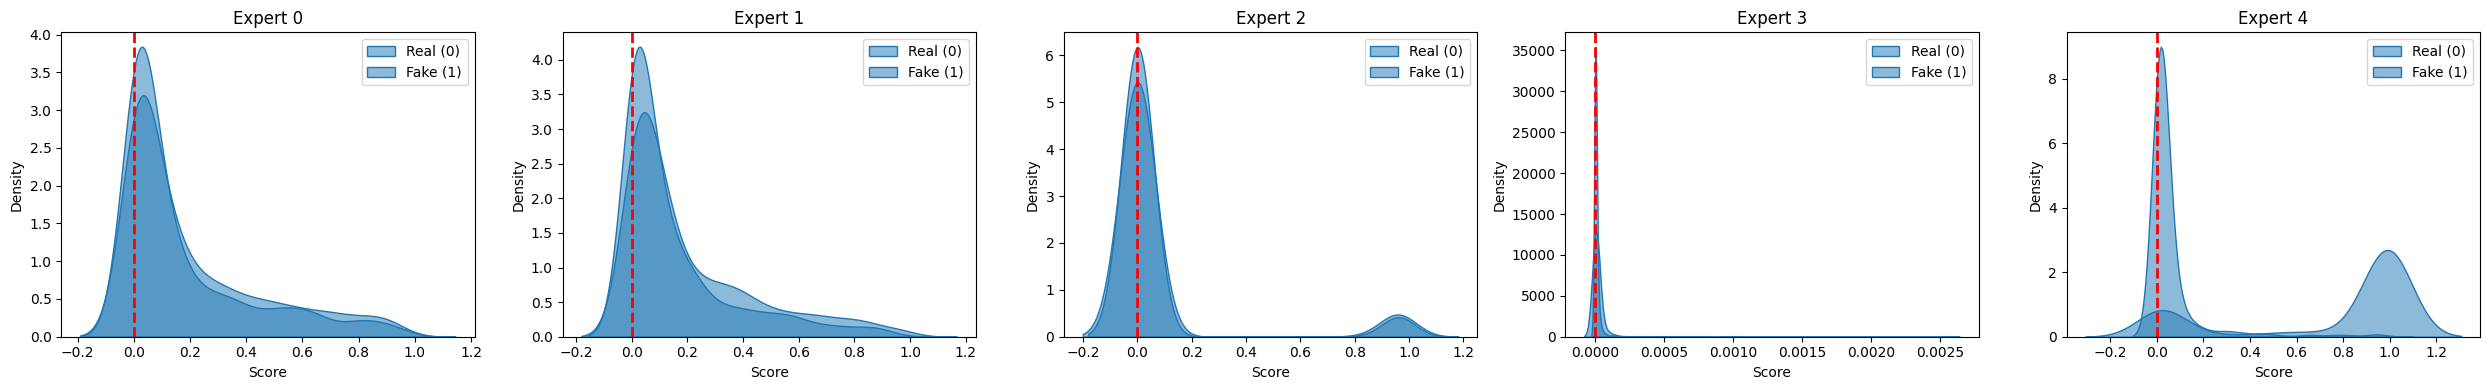


#------------ PER EXPERT (Raw Logits) ------------#



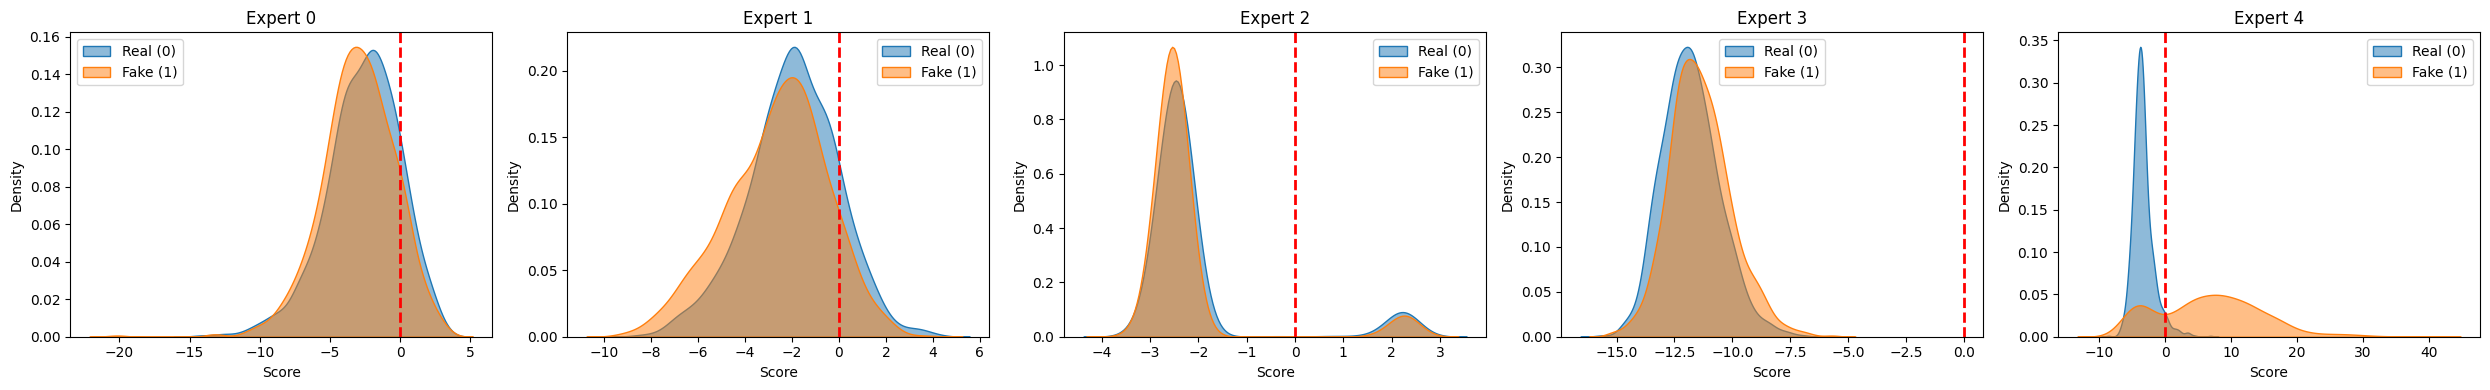

In [6]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            plot_distributions(scores, labels, ax=ax, metrics=False)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()

### Diagnosis

Coefficients (same for all attacks)
exp |    a     |    b
-------------------------
  0 |   0.967 |  -0.001
  1 |   1.099 |  -0.087
  2 |   2.219 |  -1.751
  3 |   1.050 |   0.019
  4 |   0.949 |  -0.558

################################################# Compare Phase and Energy Expert #################################################

MIN-PHASE EXPERT (NOT OK) (idx=3)
----------------------------------------
Raw logits
  std: 1.5000
  min/max: -15.6249 / -2.3211

Scaled logits
  std: 0.002163
  min/max: 0.000001 / 0.081859

Scaling parameters
  a: 1.0497
  b: 0.0192

ENERGY EXPERT (OK) (idx=4)
----------------------------------------
Raw logits
  std: 2.0456
  min/max: -8.5793 / 10.2555

Scaled logits
  std: 0.206423
  min/max: 0.000166 / 0.999897

Scaling parameters
  a: 0.9494
  b: -0.5578



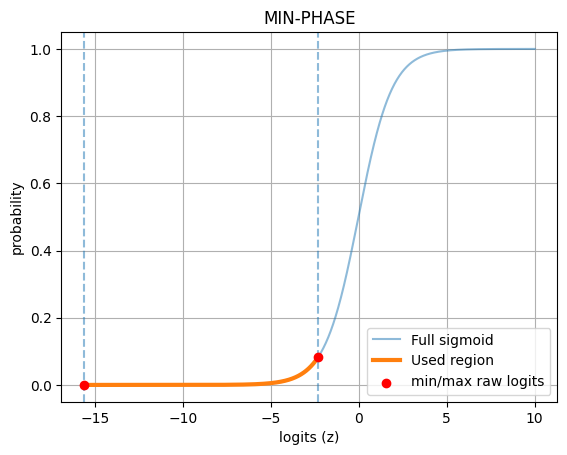

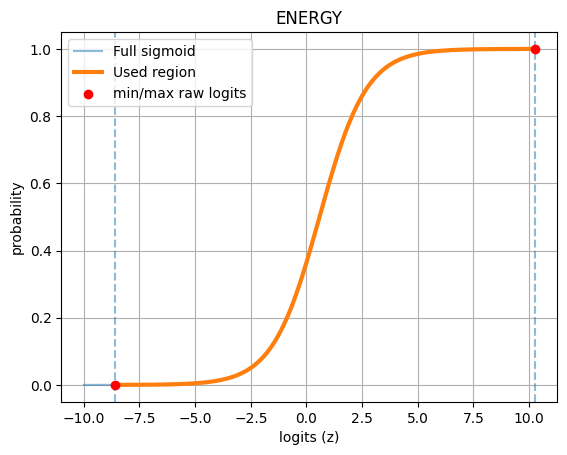

In [65]:
all_a = []
all_b = []

for g in generator_list:
    path = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/{g}"
    a = np.load(os.path.join(path, "all_a.npy"))
    b = np.load(os.path.join(path, "all_b.npy"))
    all_a.append(a)
    all_b.append(b)

print("Coefficients (same for all attacks)")
print("exp |    a     |    b")
print("-------------------------")

for i, (a, b) in enumerate(zip(all_a[0], all_b[0])):
    print(f"{i:3d} | {a:7.3f} | {b:7.3f}")

print("\n################################################# Compare Phase and Energy Expert #################################################\n")

print_expert_stats("MIN-PHASE EXPERT (NOT OK)", 3, raw, scaled, all_a, all_b)
print_expert_stats("ENERGY EXPERT (OK)", 4, raw, scaled, all_a, all_b)

plot_platt(all_a[0][3], all_b[0][3], raw[3], title="MIN-PHASE")
plot_platt(all_a[0][4], all_b[0][4], raw[4], title="ENERGY")

## [IGNORE] Remove scaling, fit KD with raw logits

## [IGNORE] Retrain phase expert with label smoothing

## Scale raw logits using Calibration Set instead of Validation Set


#--------- OVERALL ENSEMBLE ---------#

AUC: 84.53%, EER: 24.07%
Loaded 19171 samples
Real mean score: -1.4804
Fake mean score: 1.8393



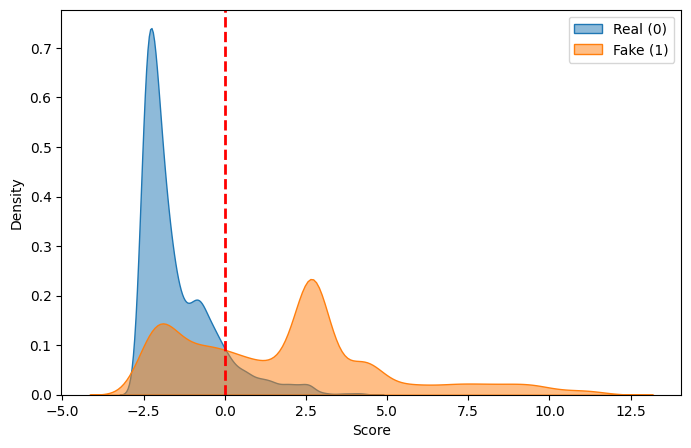


#------------ PER EXPERT ------------#



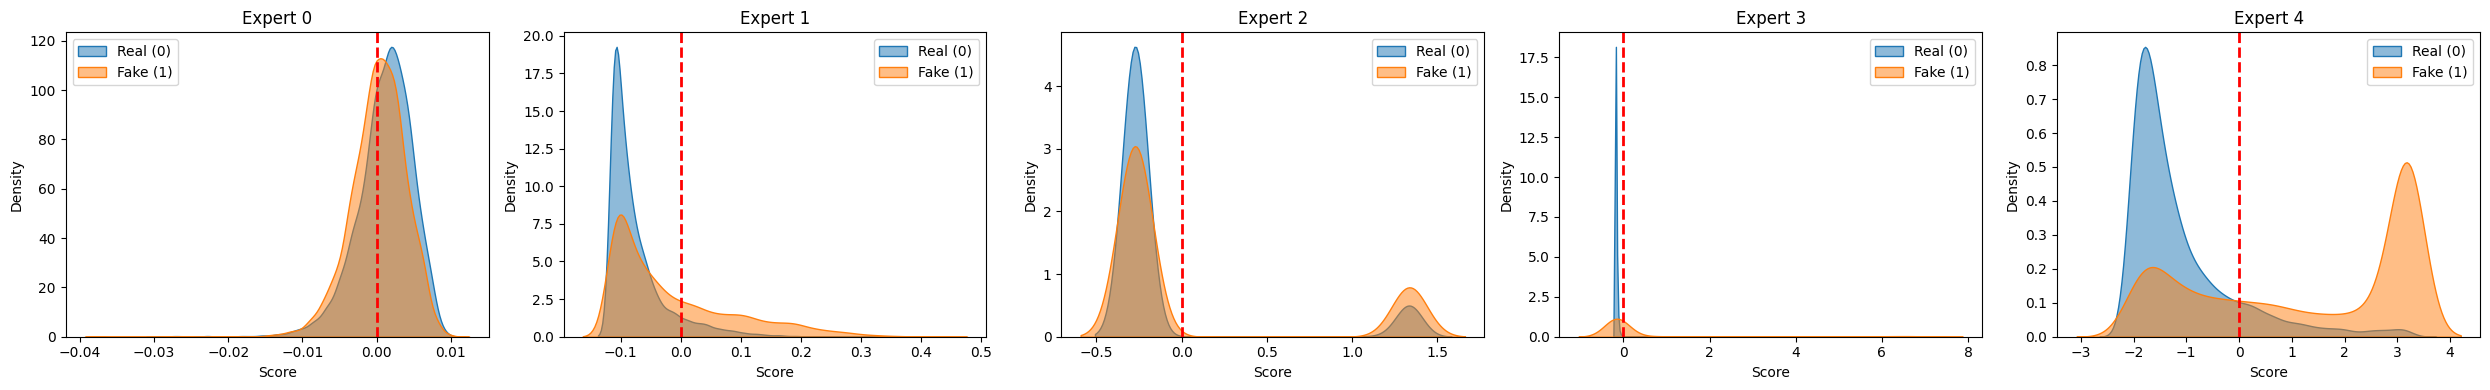

In [78]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/SCALE_CALIB/ALL"
labels = np.load(os.path.join(rootpath, "labels.npy"))

print("\n#--------- OVERALL ENSEMBLE ---------#\n")
scores = np.load(os.path.join(rootpath, "scores.npy"))
plot_distributions(scores, labels)
plt.show()

print("\n#------------ PER EXPERT ------------#\n")
all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
n_exp = all_logLR.shape[0]
fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

for i in range(n_exp):
    ax = axes[i] if n_exp > 1 else axes
    scores = all_logLR[i]

    plot_distributions(scores, labels, ax=ax, metrics=False)
    ax.set_title(f"Expert {i}")

plt.tight_layout()
plt.show()


### Per attack


########################################################################################################################
#--------------------------------------------------------- A01 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 87.58%, EER: 20.19%
Loaded 1898 samples
Real mean score: -1.5205
Fake mean score: 0.5891



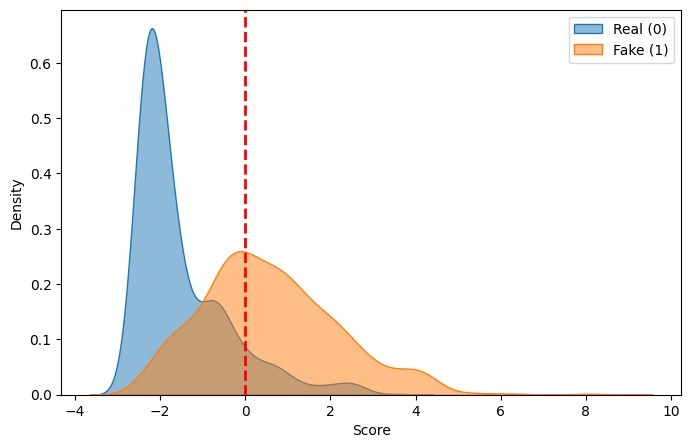


#------------ PER EXPERT (LogLR scores) ------------#



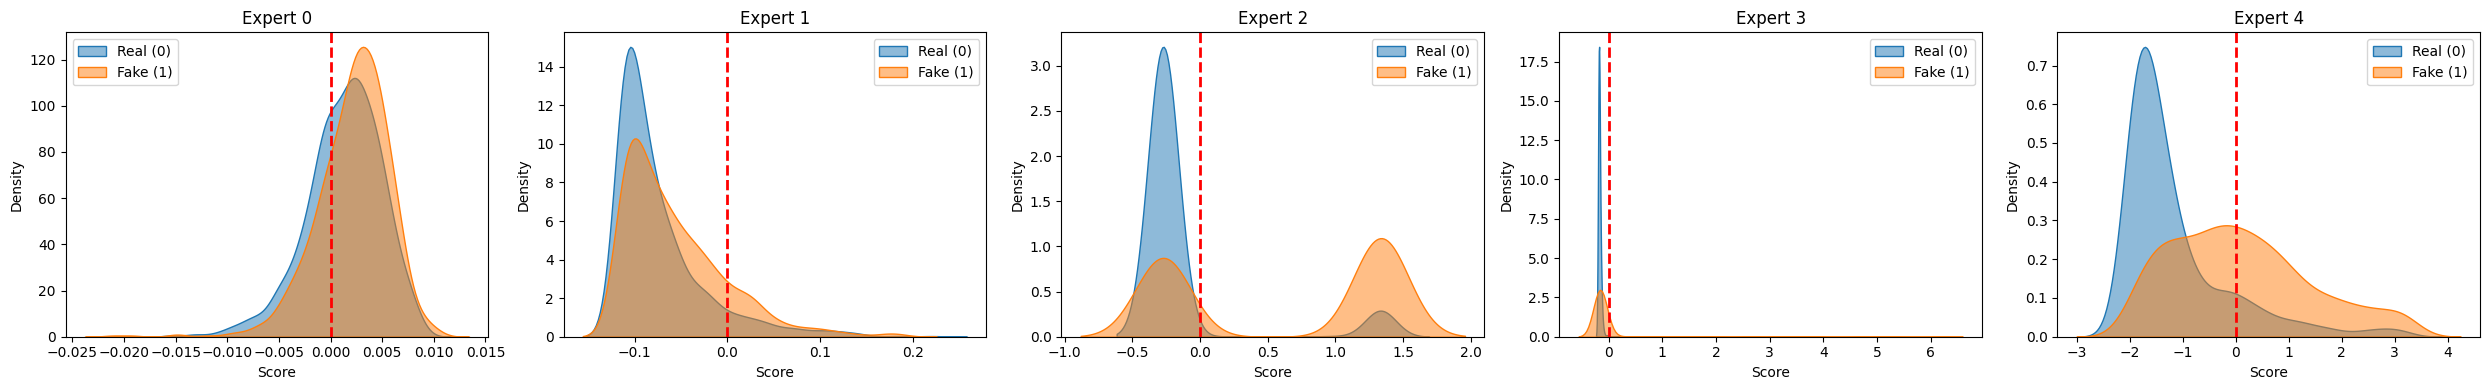


#------------ PER EXPERT (Scaled Logits) ------------#



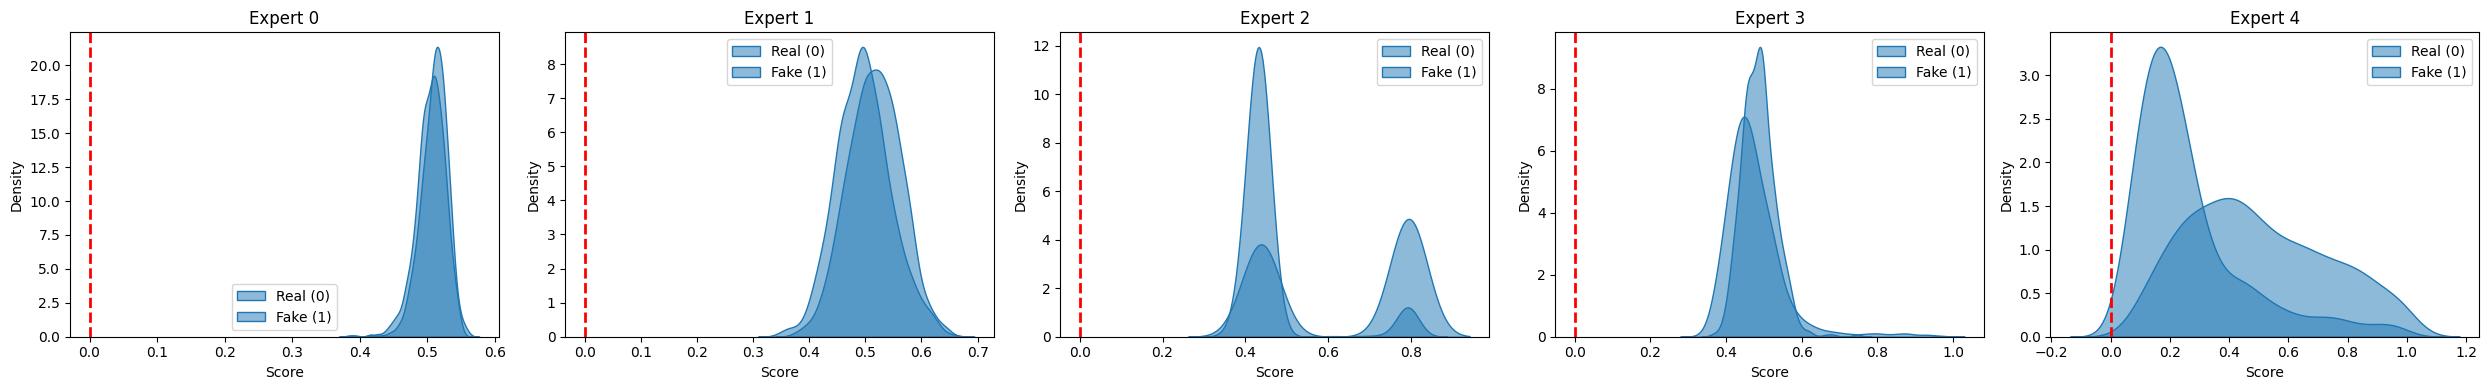


#------------ PER EXPERT (Raw Logits) ------------#



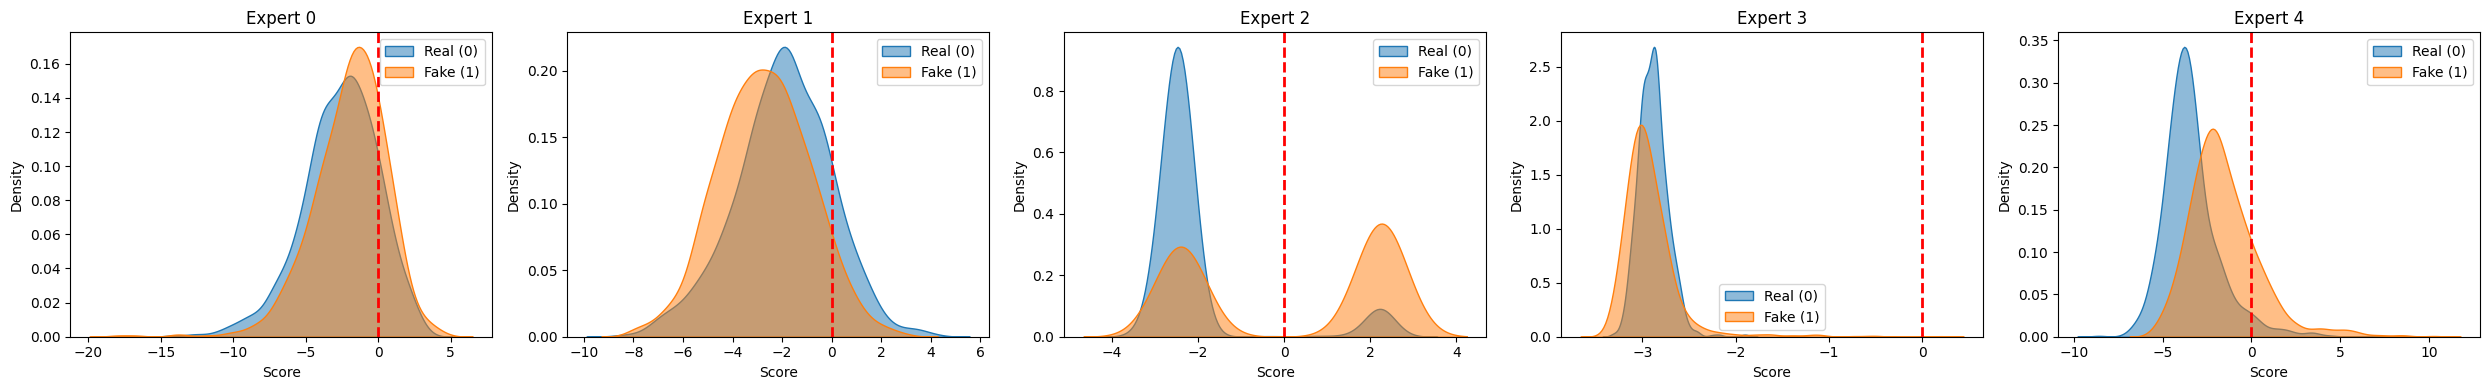


########################################################################################################################
#--------------------------------------------------------- A02 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 77.16%, EER: 30.25%
Loaded 1926 samples
Real mean score: -1.5205
Fake mean score: 0.8398



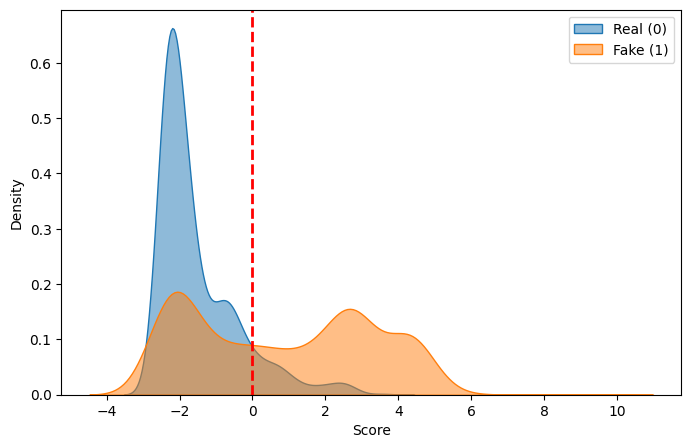


#------------ PER EXPERT (LogLR scores) ------------#



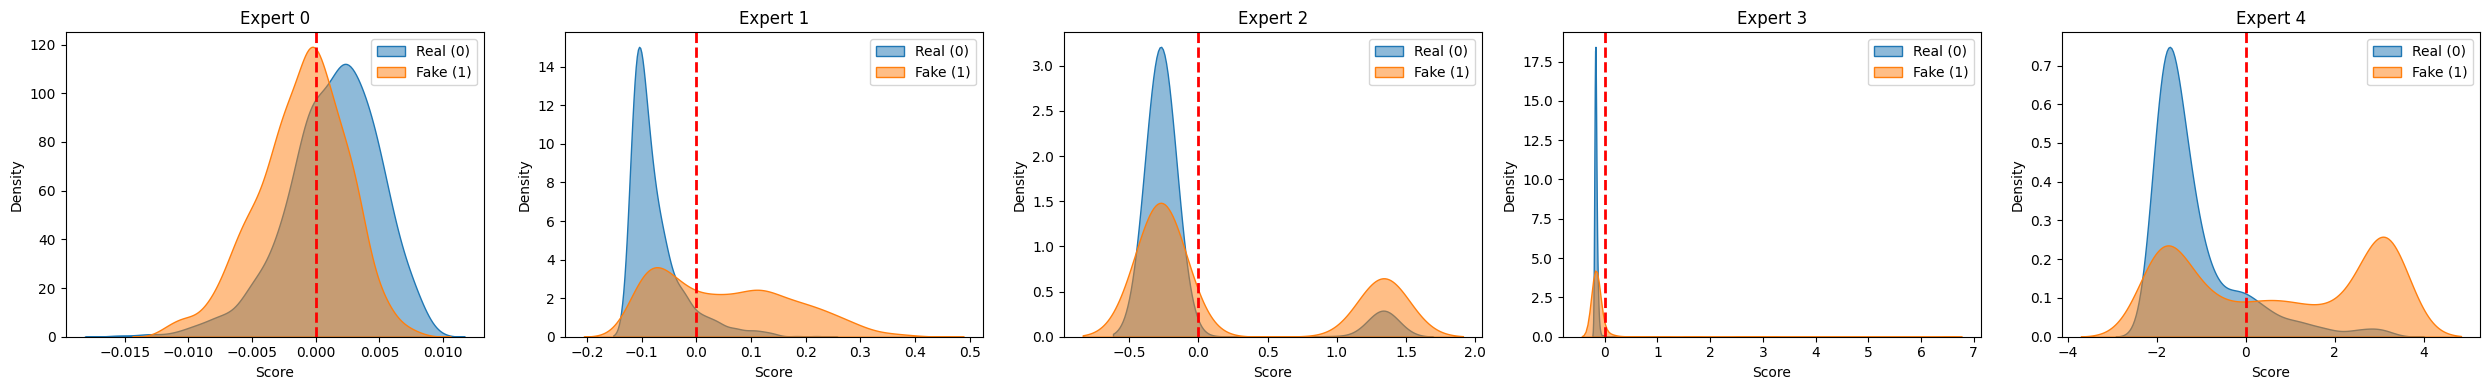


#------------ PER EXPERT (Scaled Logits) ------------#



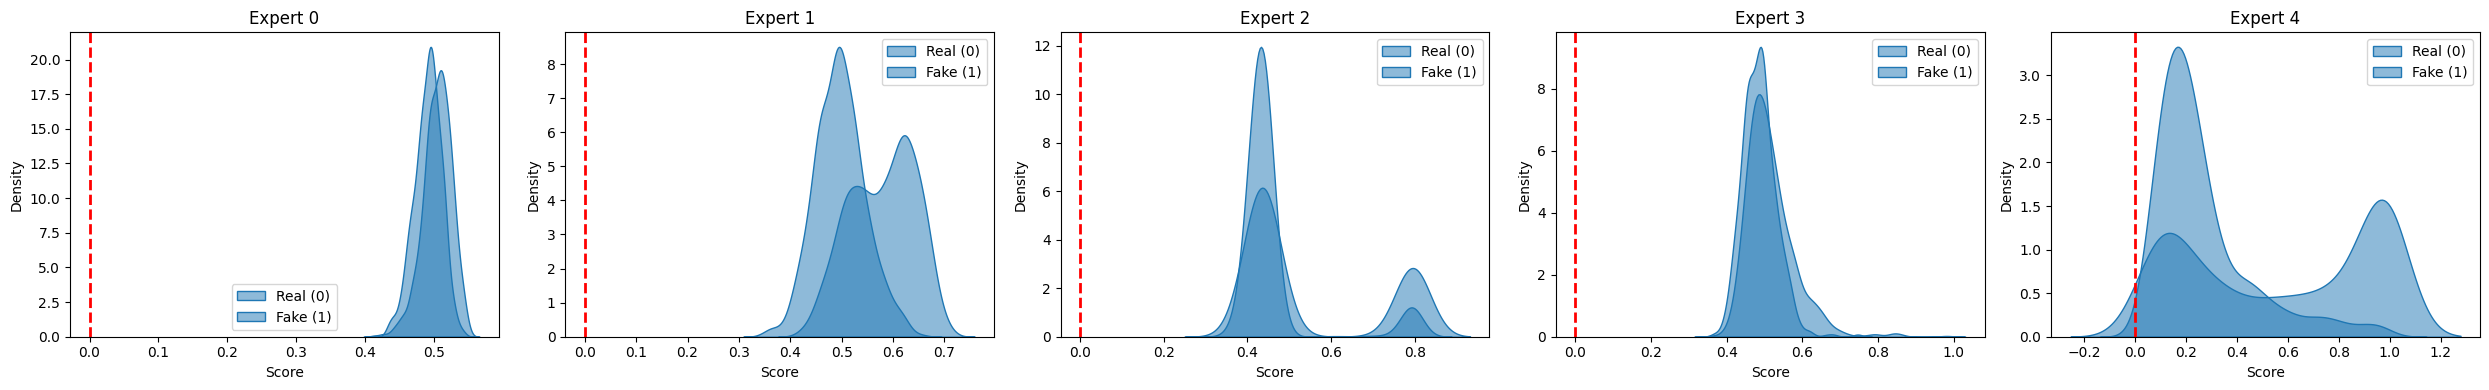


#------------ PER EXPERT (Raw Logits) ------------#



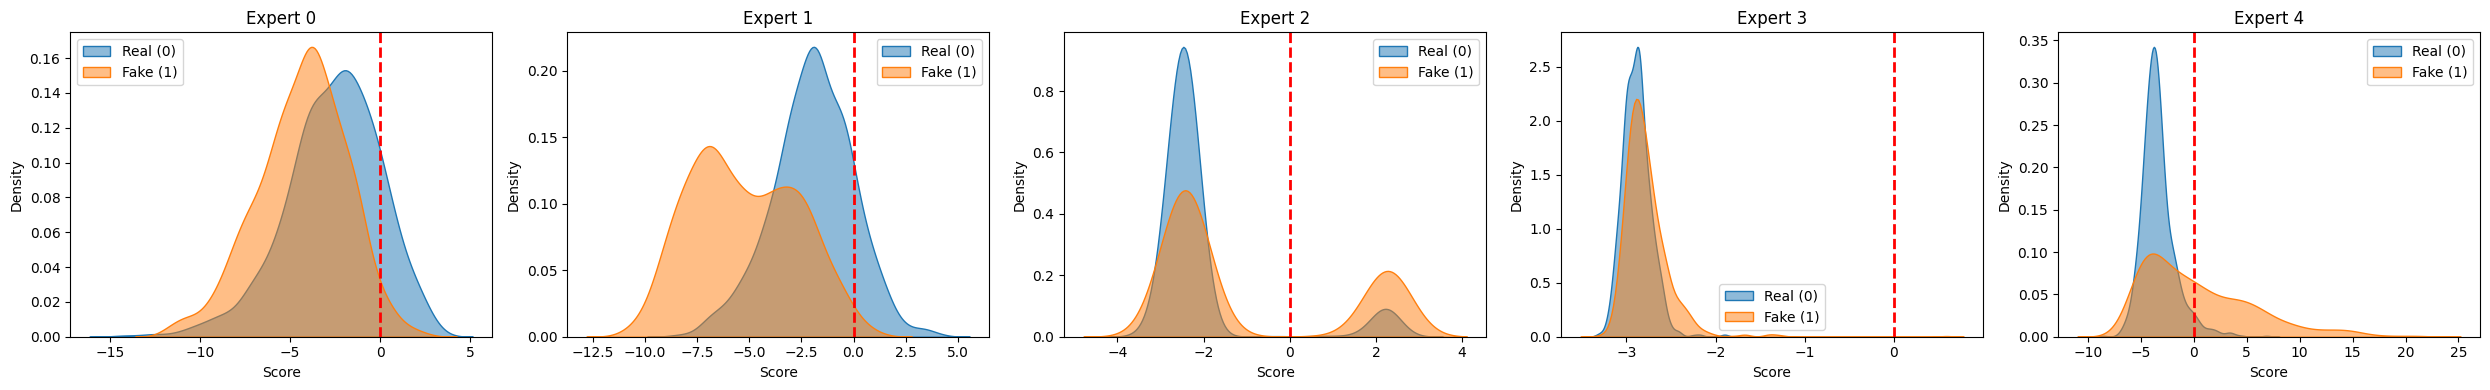


########################################################################################################################
#--------------------------------------------------------- A03 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 97.72%, EER: 7.55%
Loaded 1931 samples
Real mean score: -1.5205
Fake mean score: 3.2329



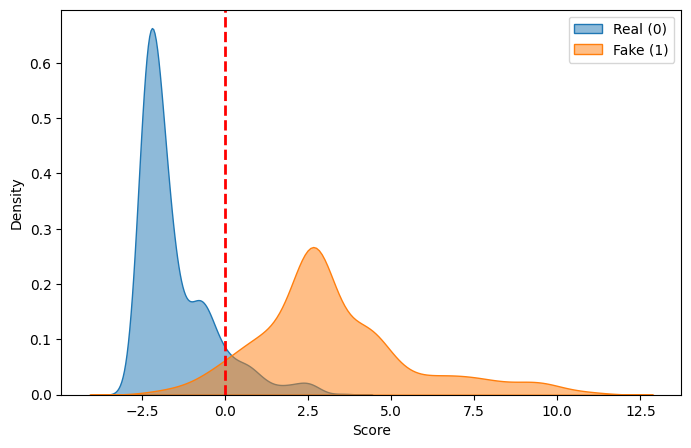


#------------ PER EXPERT (LogLR scores) ------------#



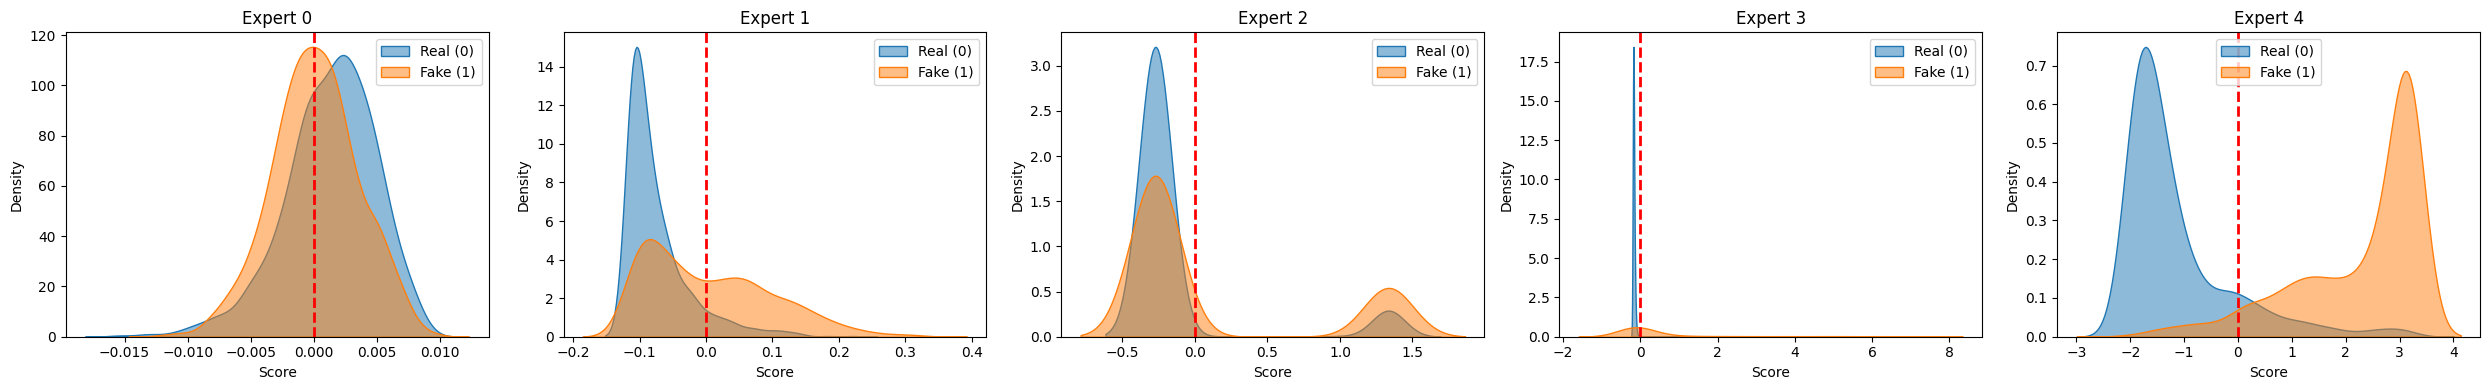


#------------ PER EXPERT (Scaled Logits) ------------#



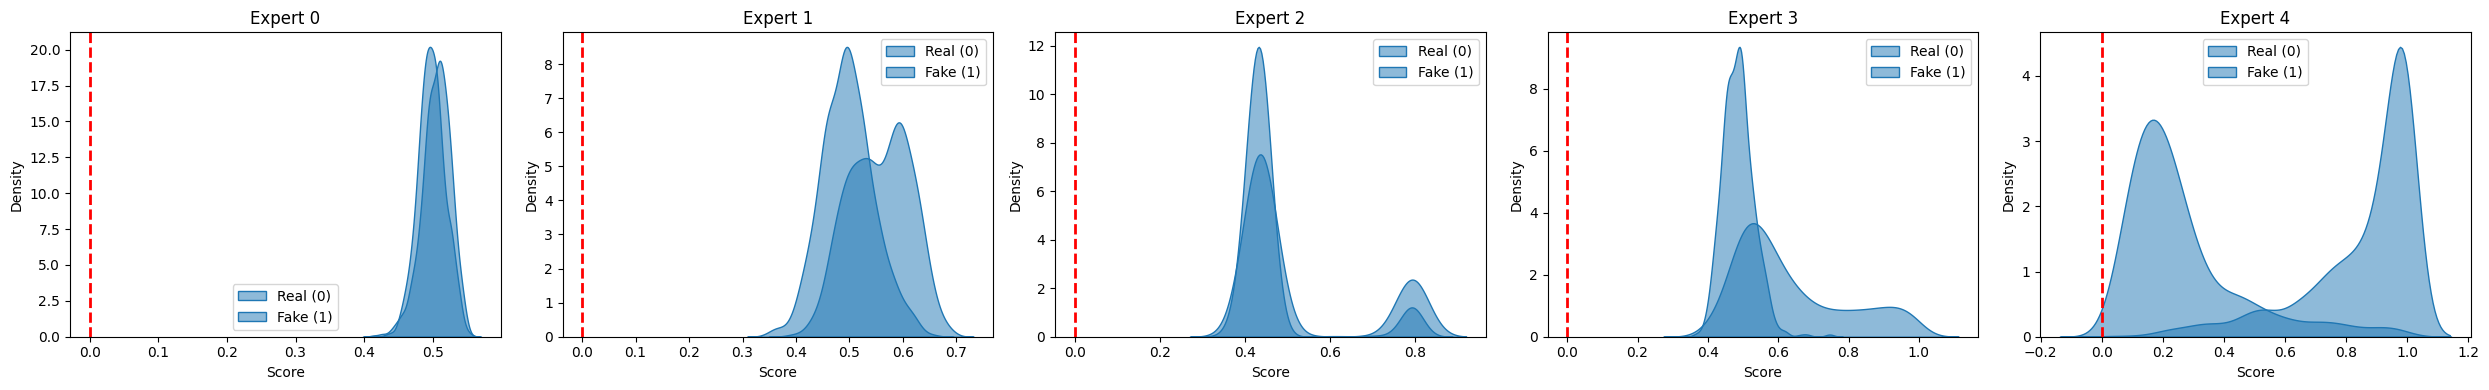


#------------ PER EXPERT (Raw Logits) ------------#



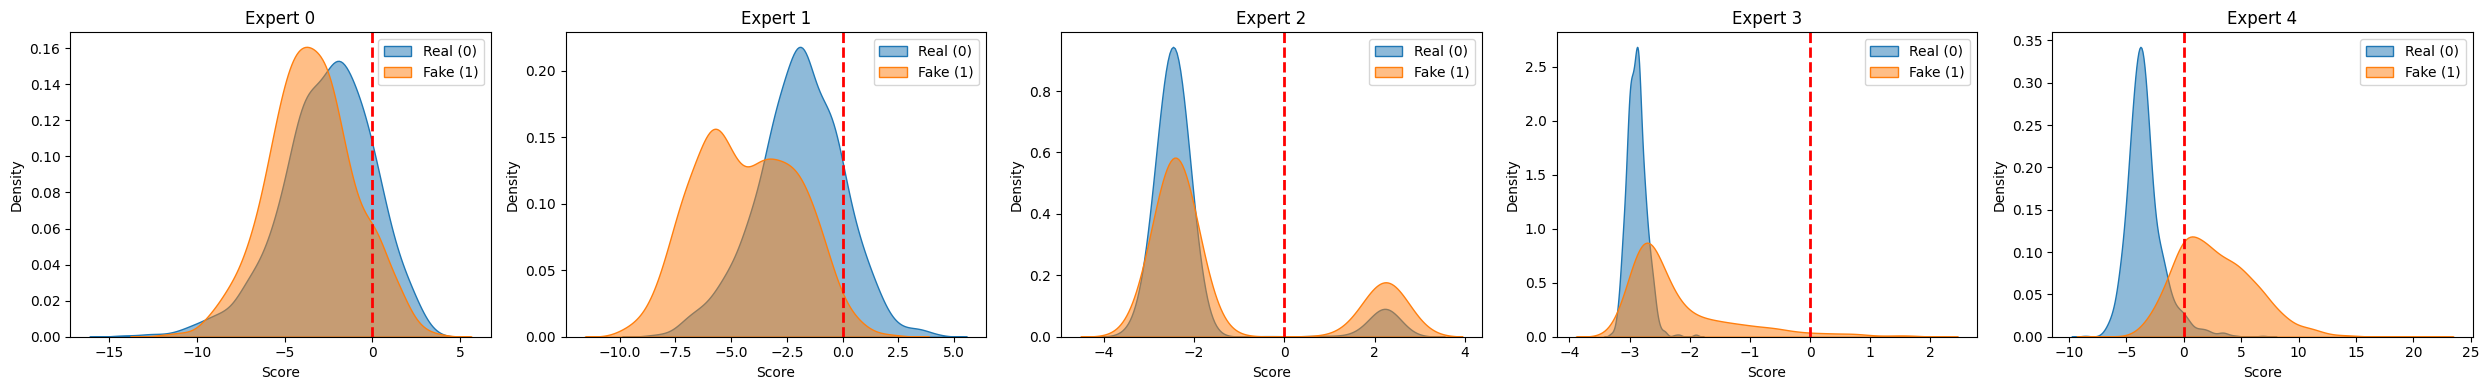


########################################################################################################################
#--------------------------------------------------------- A04 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 88.80%, EER: 20.87%
Loaded 1880 samples
Real mean score: -1.5205
Fake mean score: 1.5762



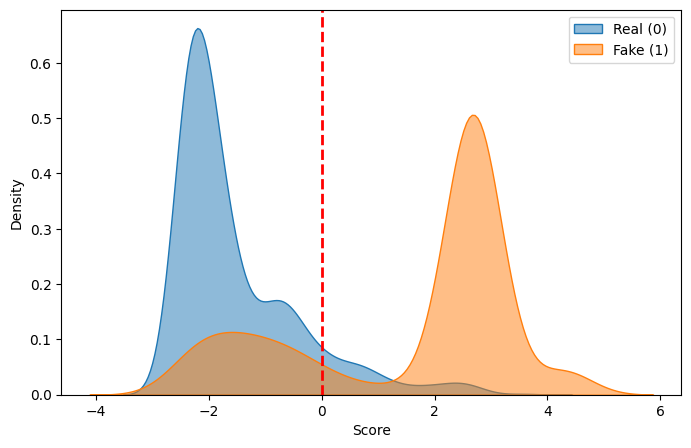


#------------ PER EXPERT (LogLR scores) ------------#



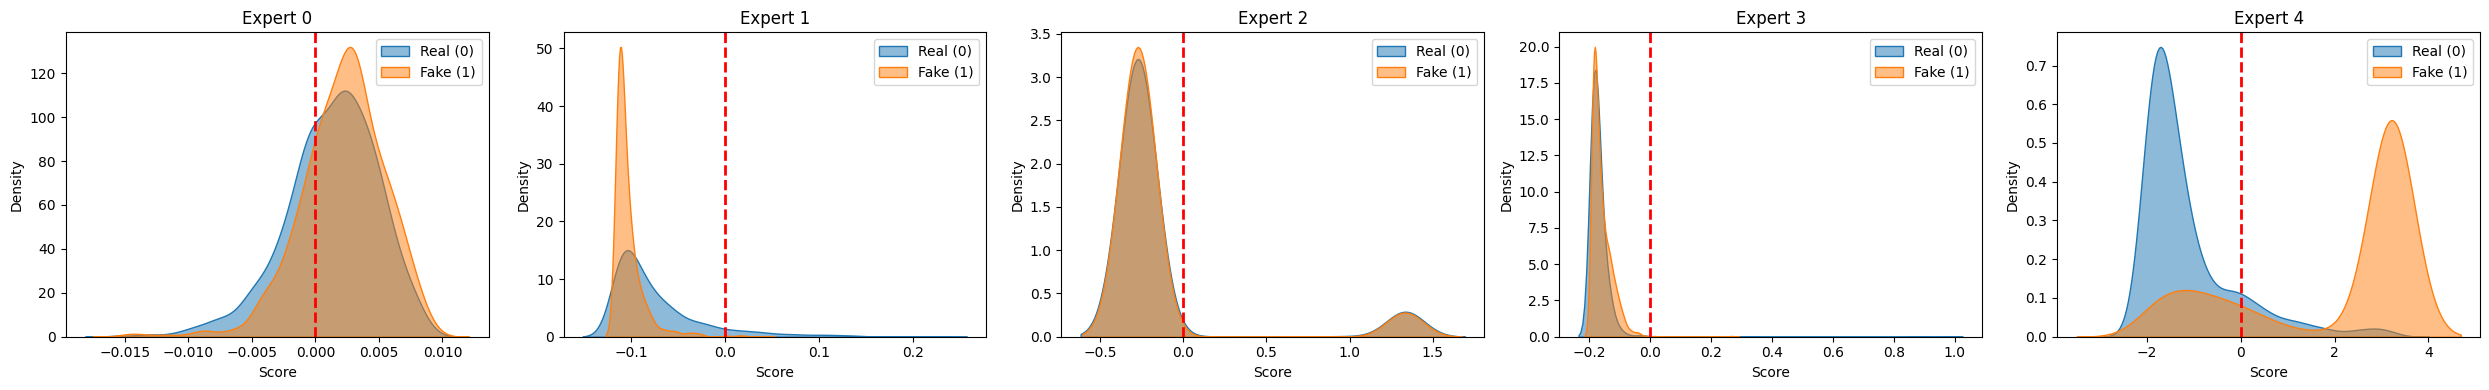


#------------ PER EXPERT (Scaled Logits) ------------#



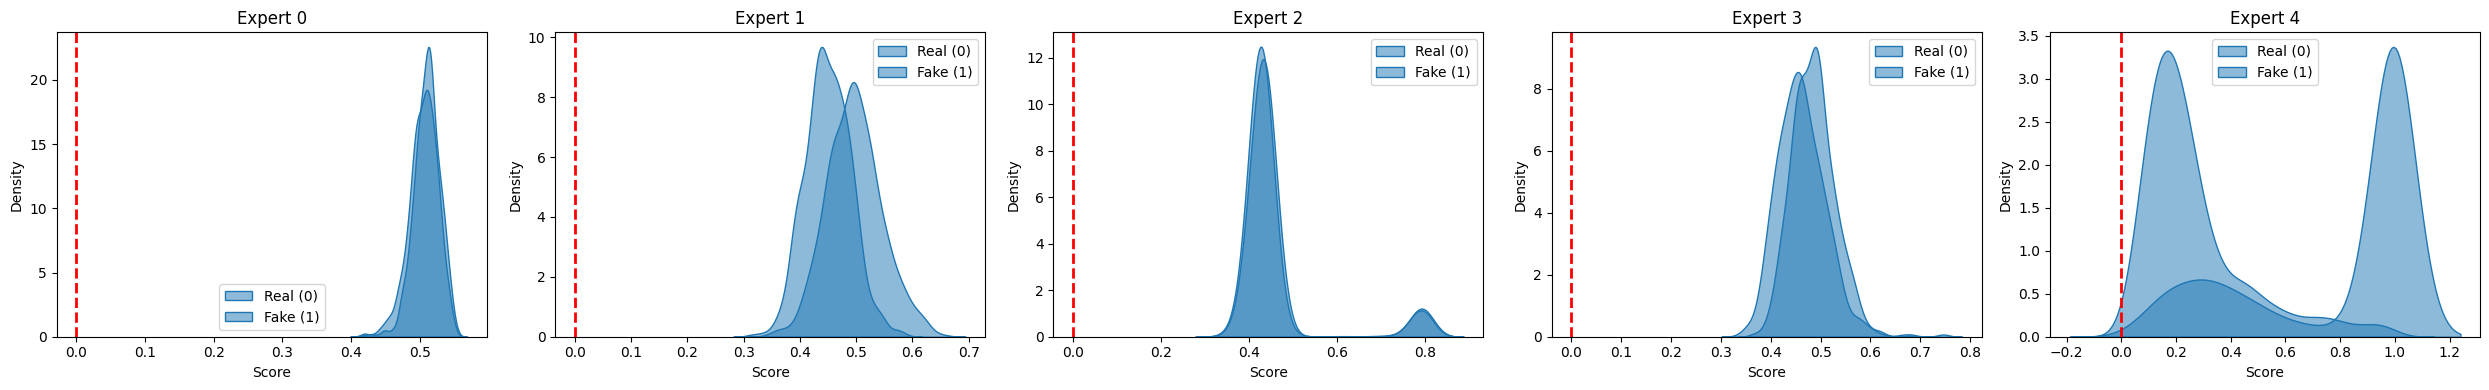


#------------ PER EXPERT (Raw Logits) ------------#



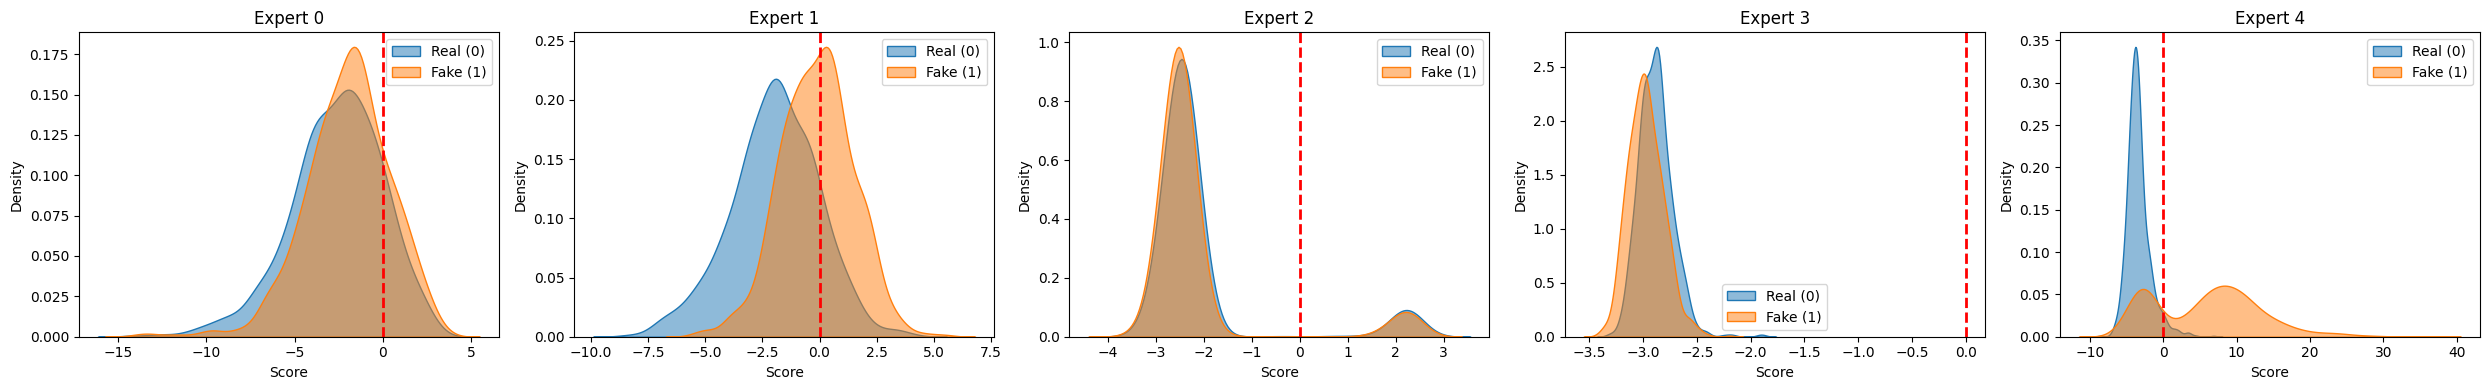


########################################################################################################################
#--------------------------------------------------------- A07 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 69.97%, EER: 35.24%
Loaded 1940 samples
Real mean score: -1.5205
Fake mean score: -0.7807



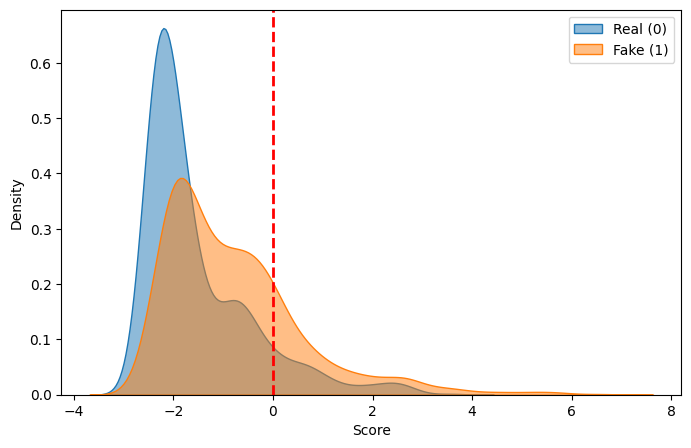


#------------ PER EXPERT (LogLR scores) ------------#



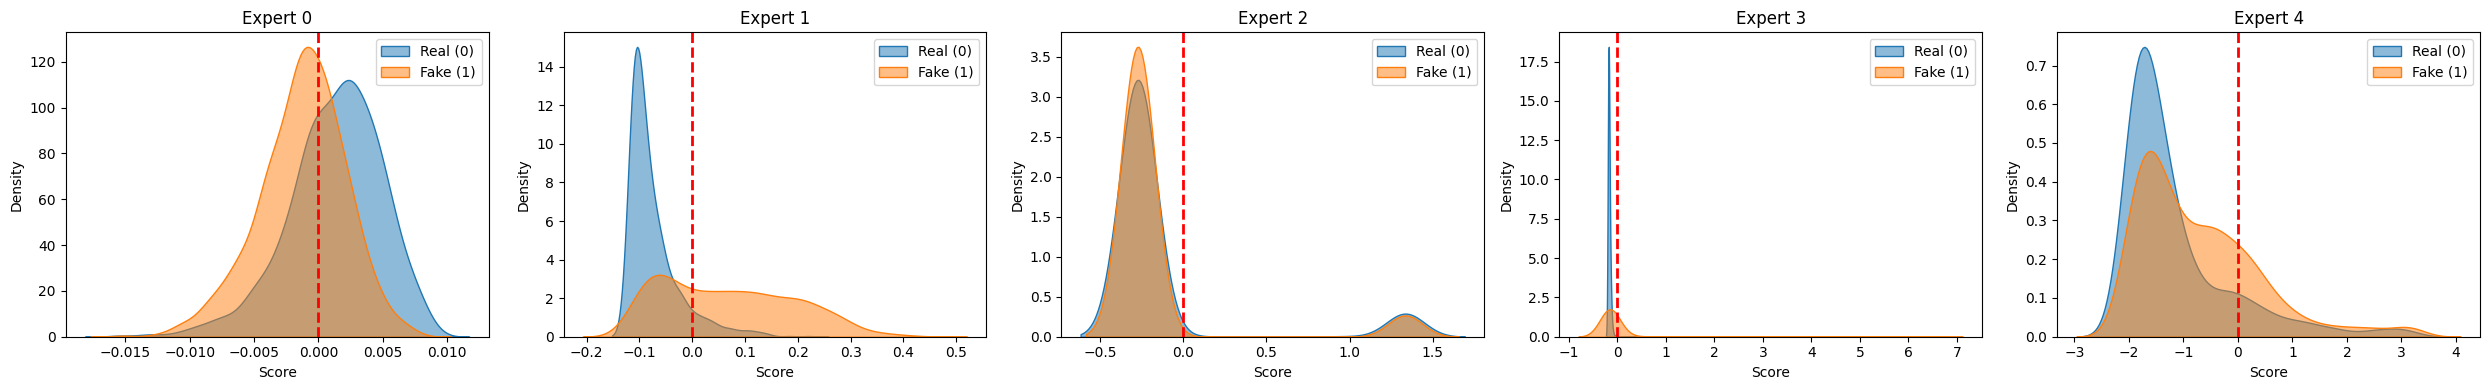


#------------ PER EXPERT (Scaled Logits) ------------#



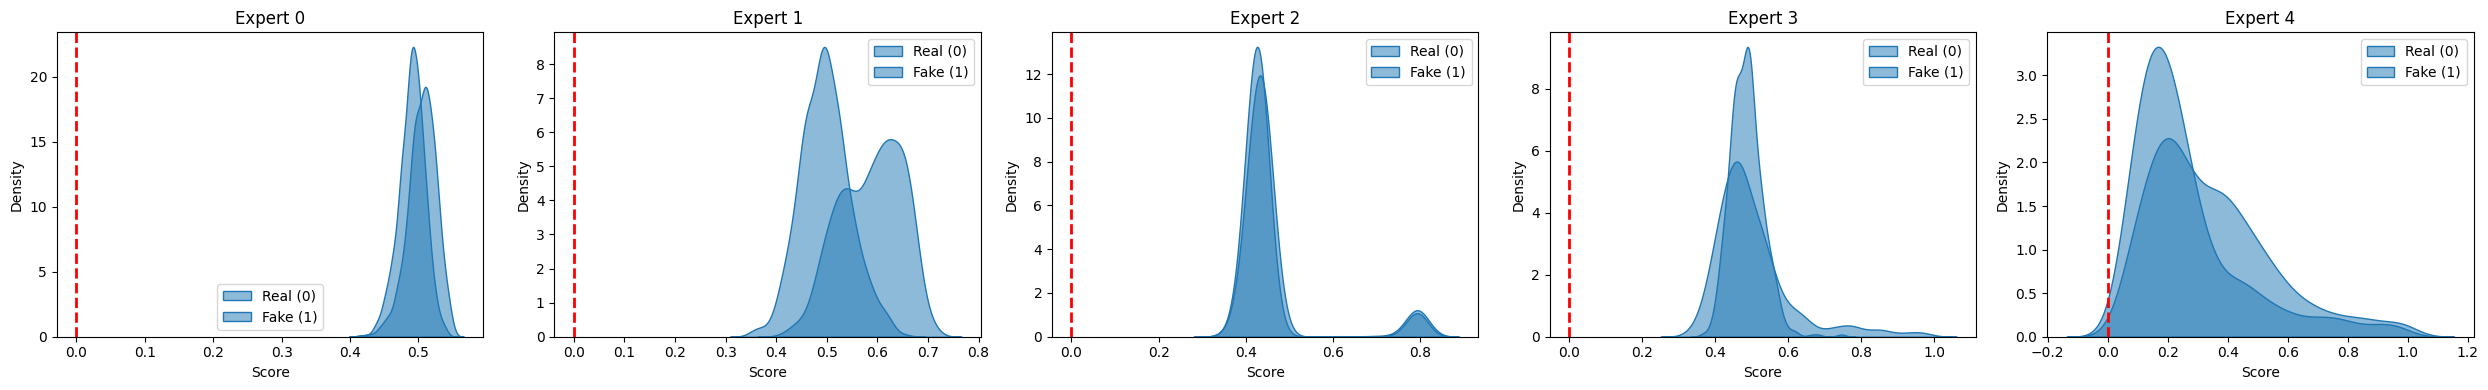


#------------ PER EXPERT (Raw Logits) ------------#



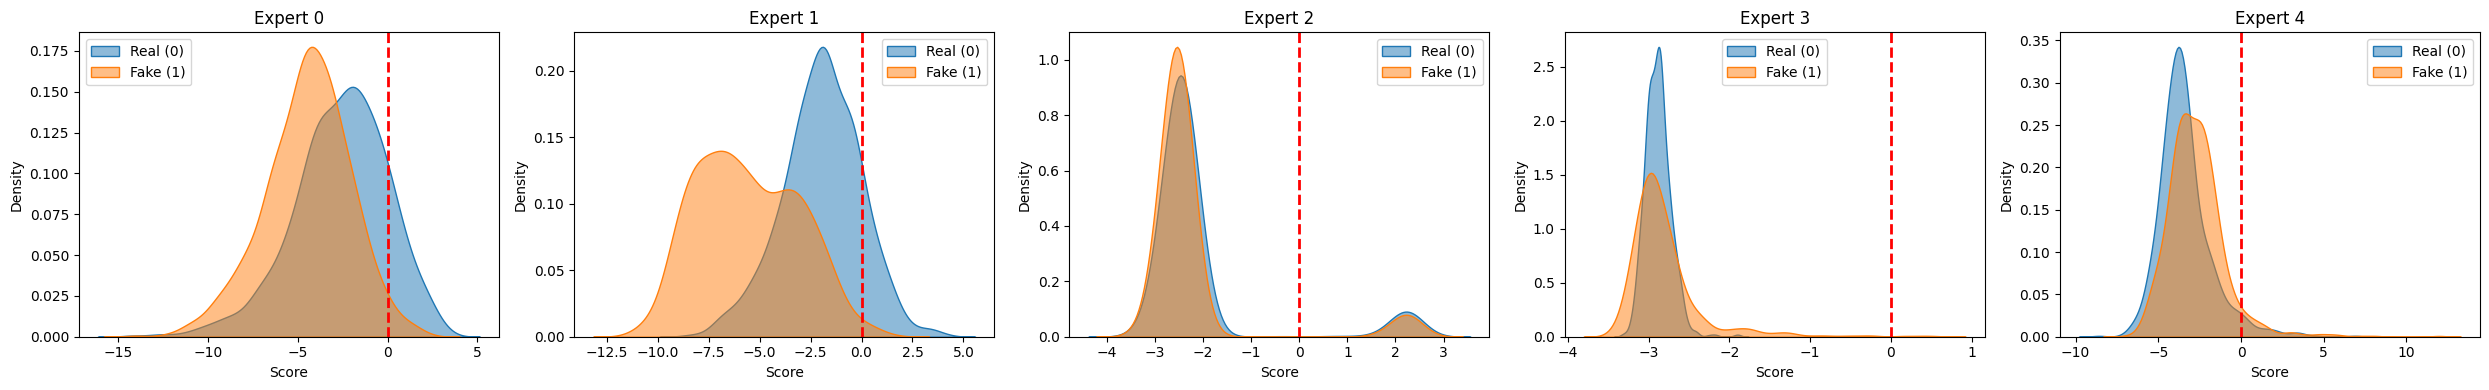


########################################################################################################################
#--------------------------------------------------------- A08 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 98.57%, EER: 6.06%
Loaded 1933 samples
Real mean score: -1.5205
Fake mean score: 4.5070



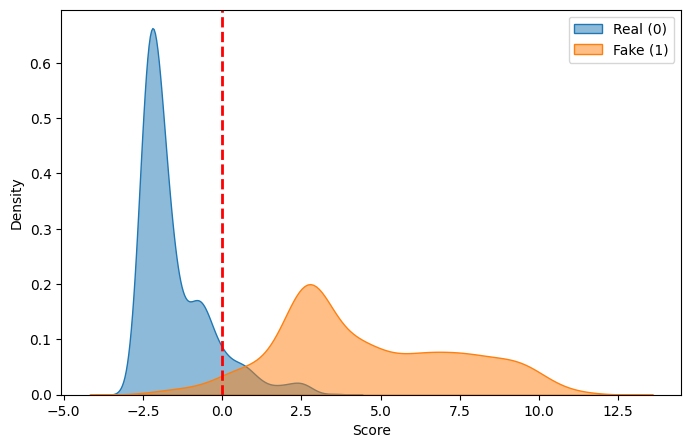


#------------ PER EXPERT (LogLR scores) ------------#



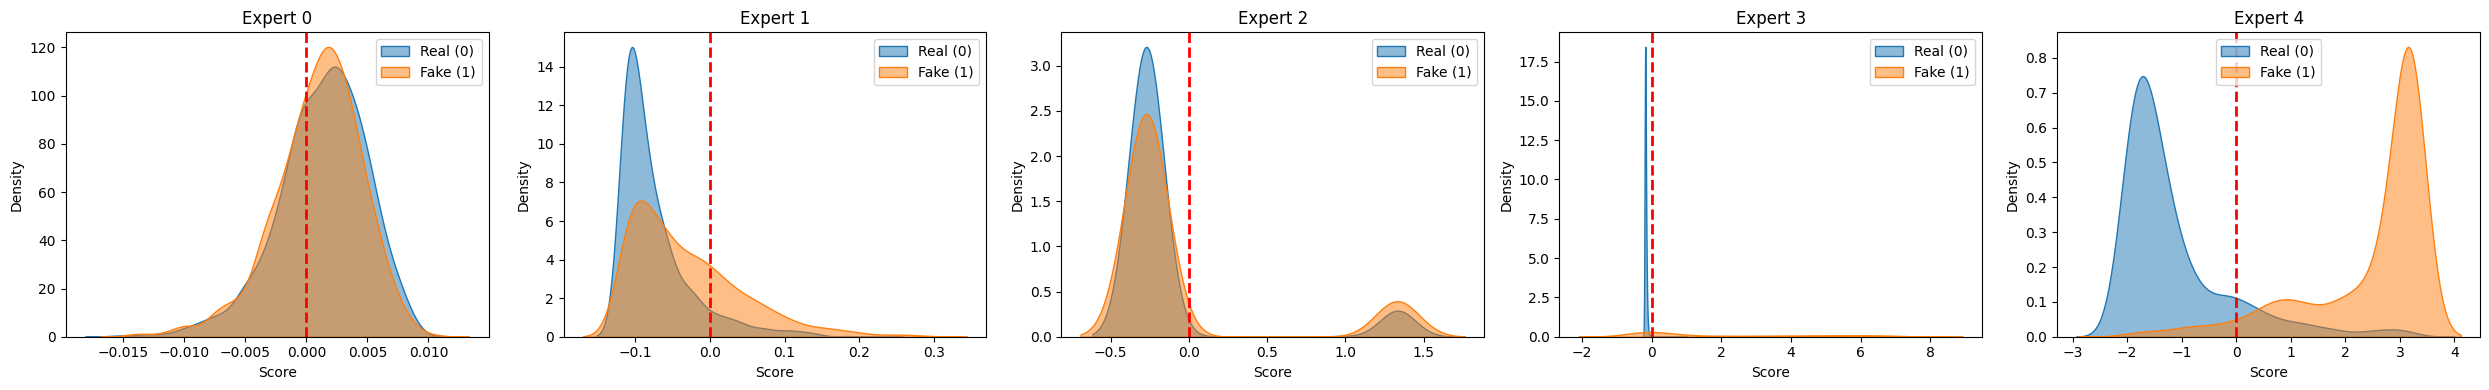


#------------ PER EXPERT (Scaled Logits) ------------#



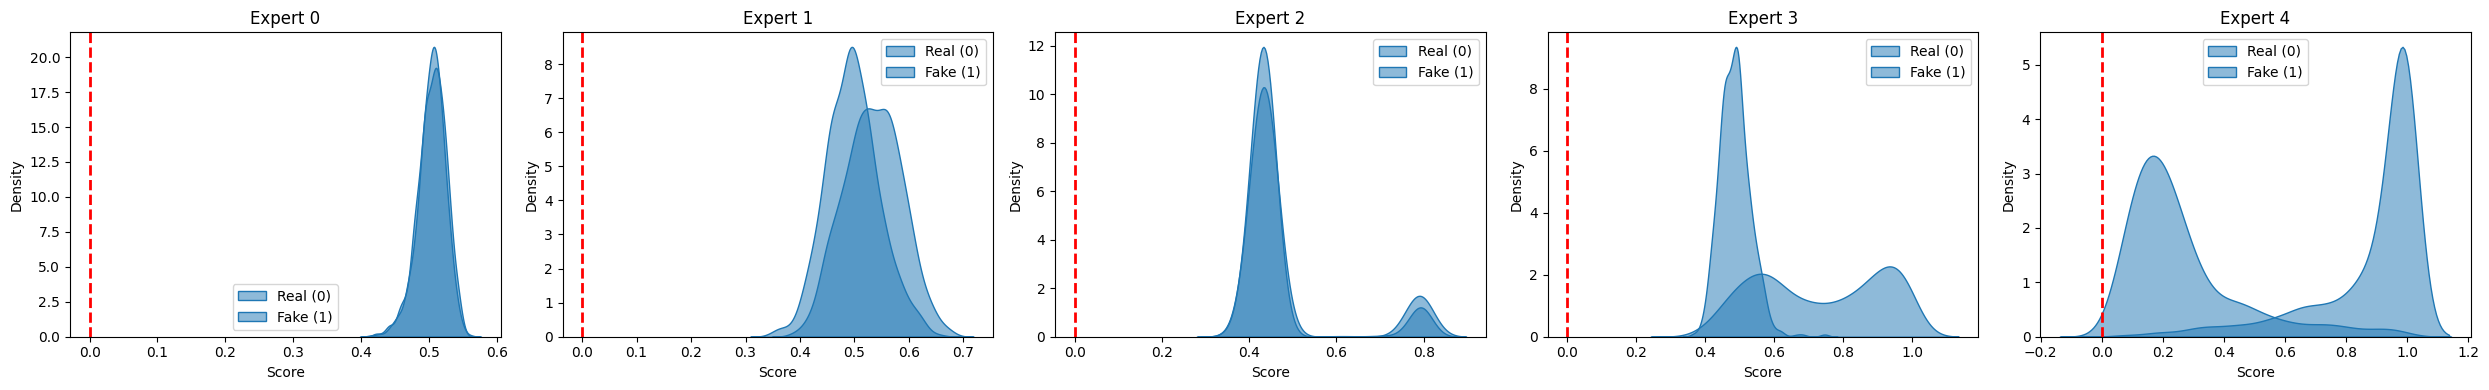


#------------ PER EXPERT (Raw Logits) ------------#



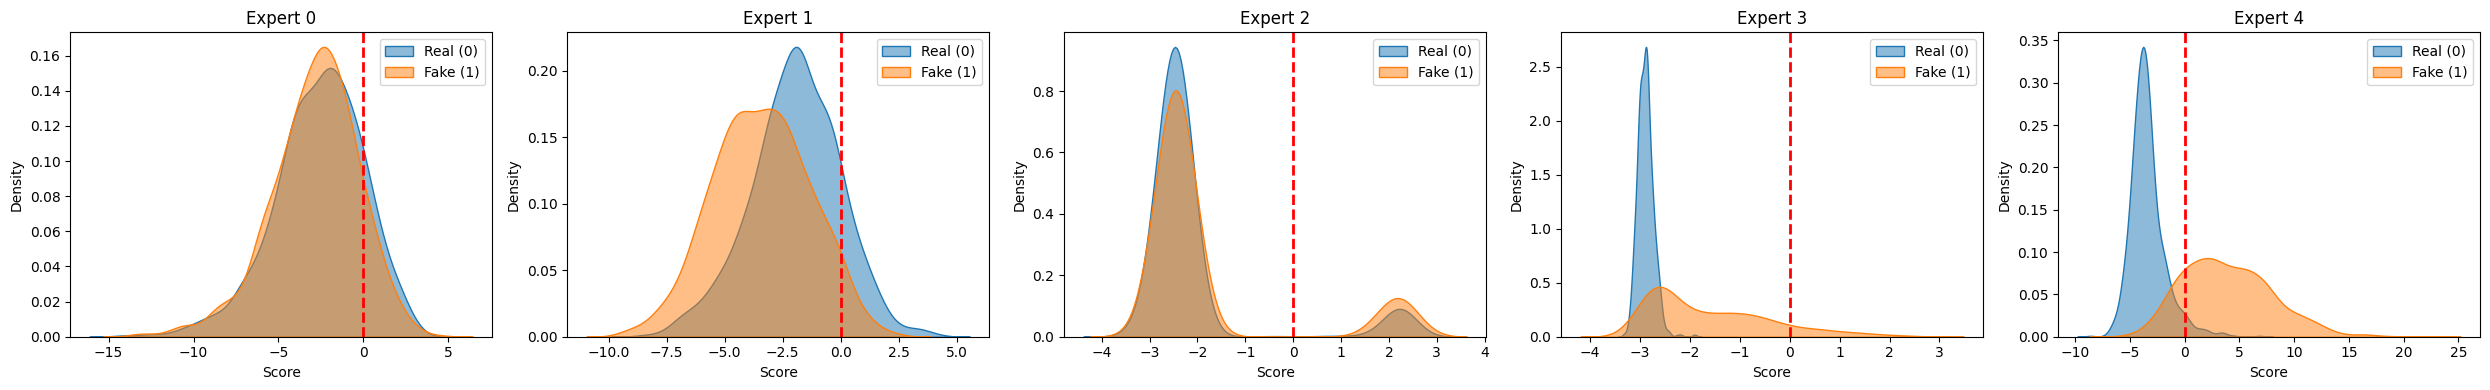


########################################################################################################################
#--------------------------------------------------------- A09 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 99.07%, EER: 3.83%
Loaded 1939 samples
Real mean score: -1.5205
Fake mean score: 6.1167



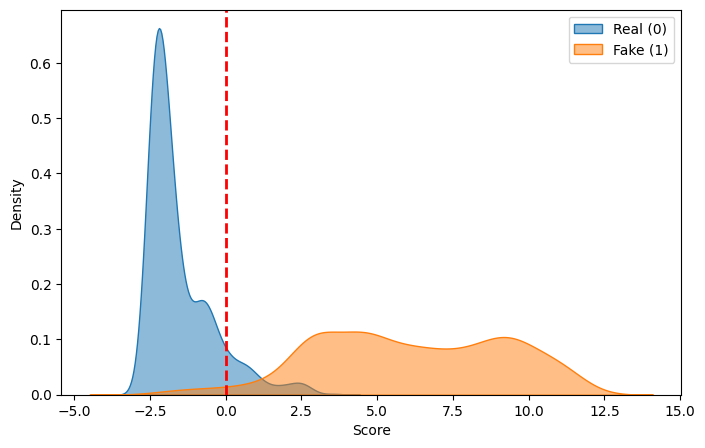


#------------ PER EXPERT (LogLR scores) ------------#



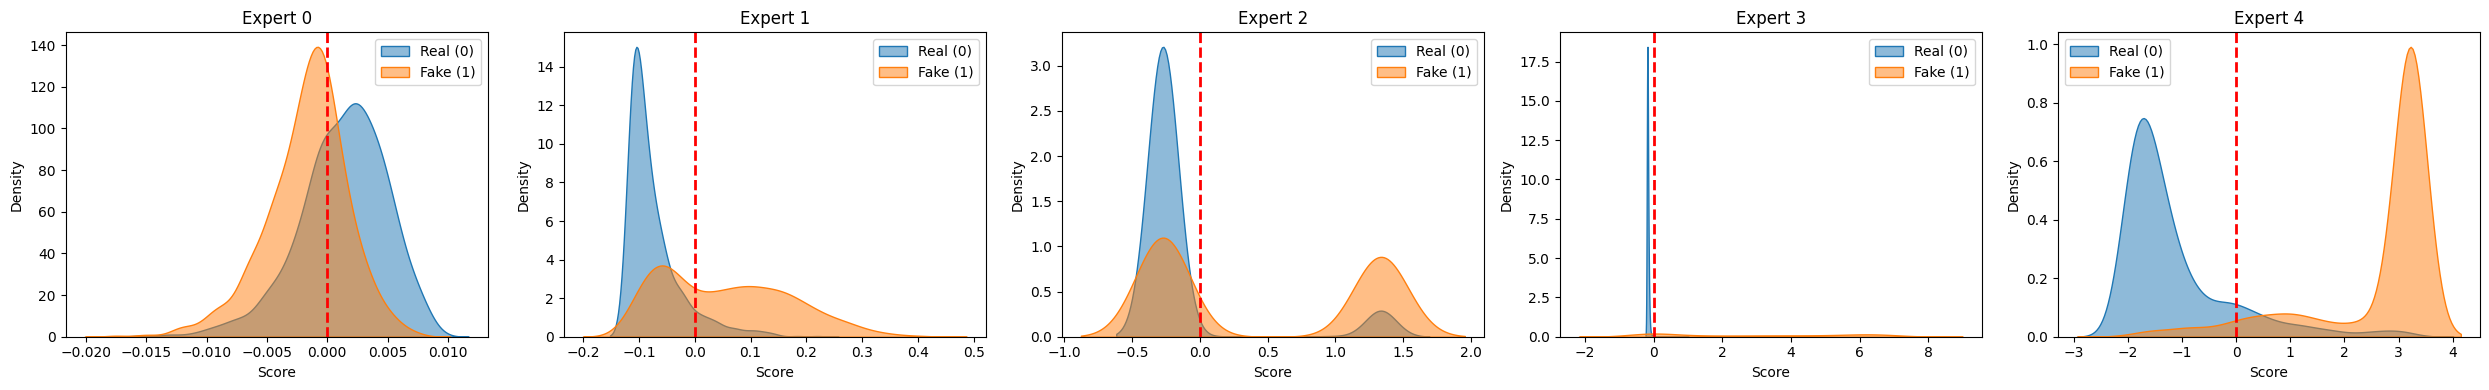


#------------ PER EXPERT (Scaled Logits) ------------#



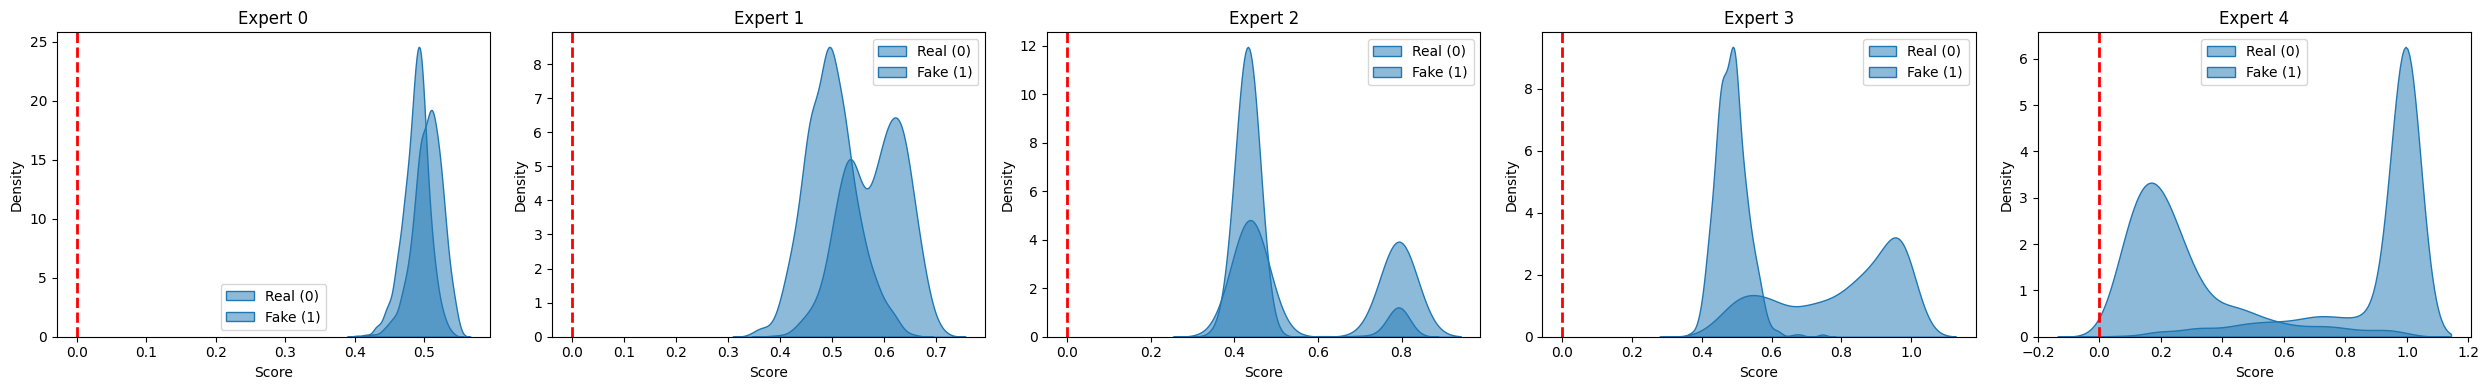


#------------ PER EXPERT (Raw Logits) ------------#



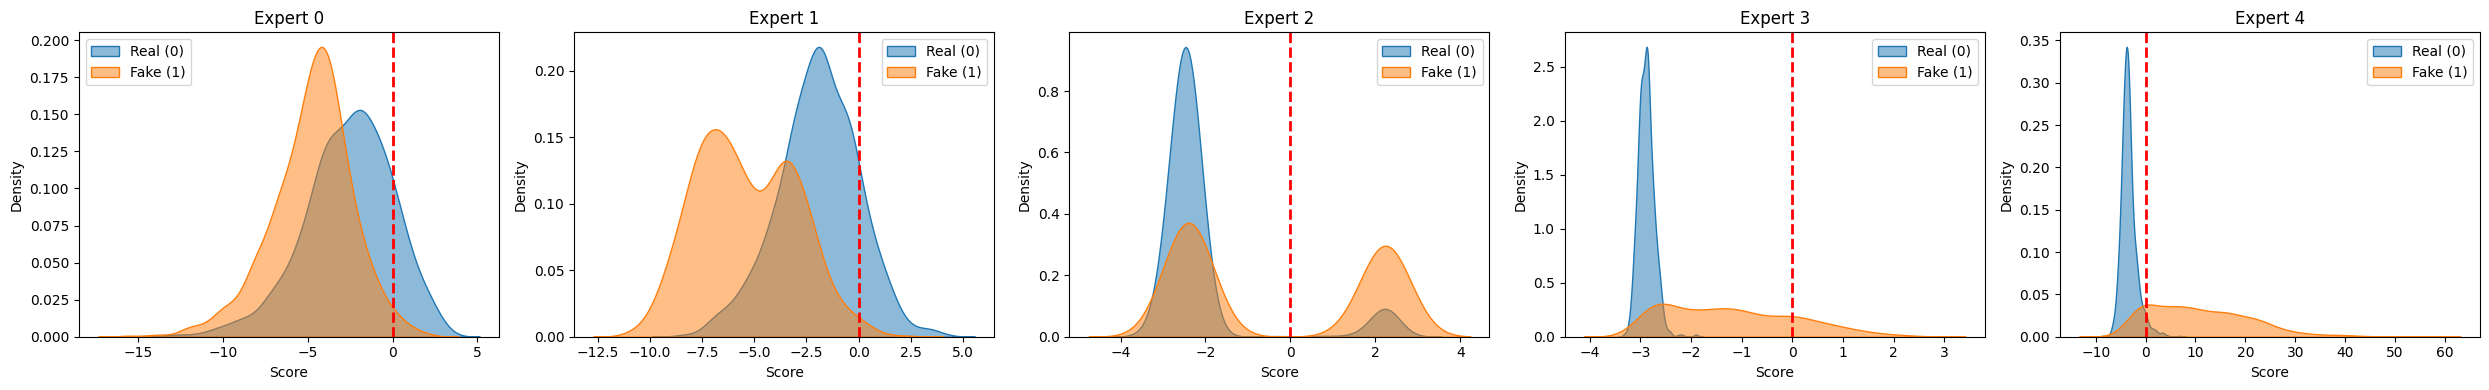


########################################################################################################################
#--------------------------------------------------------- A10 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 59.09%, EER: 43.46%
Loaded 1898 samples
Real mean score: -1.5205
Fake mean score: -1.2134



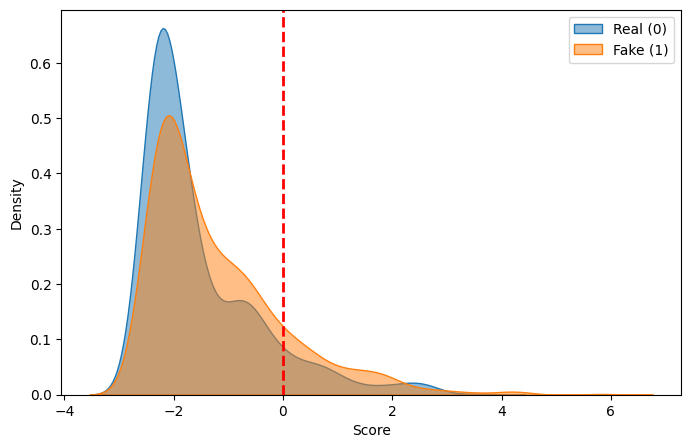


#------------ PER EXPERT (LogLR scores) ------------#



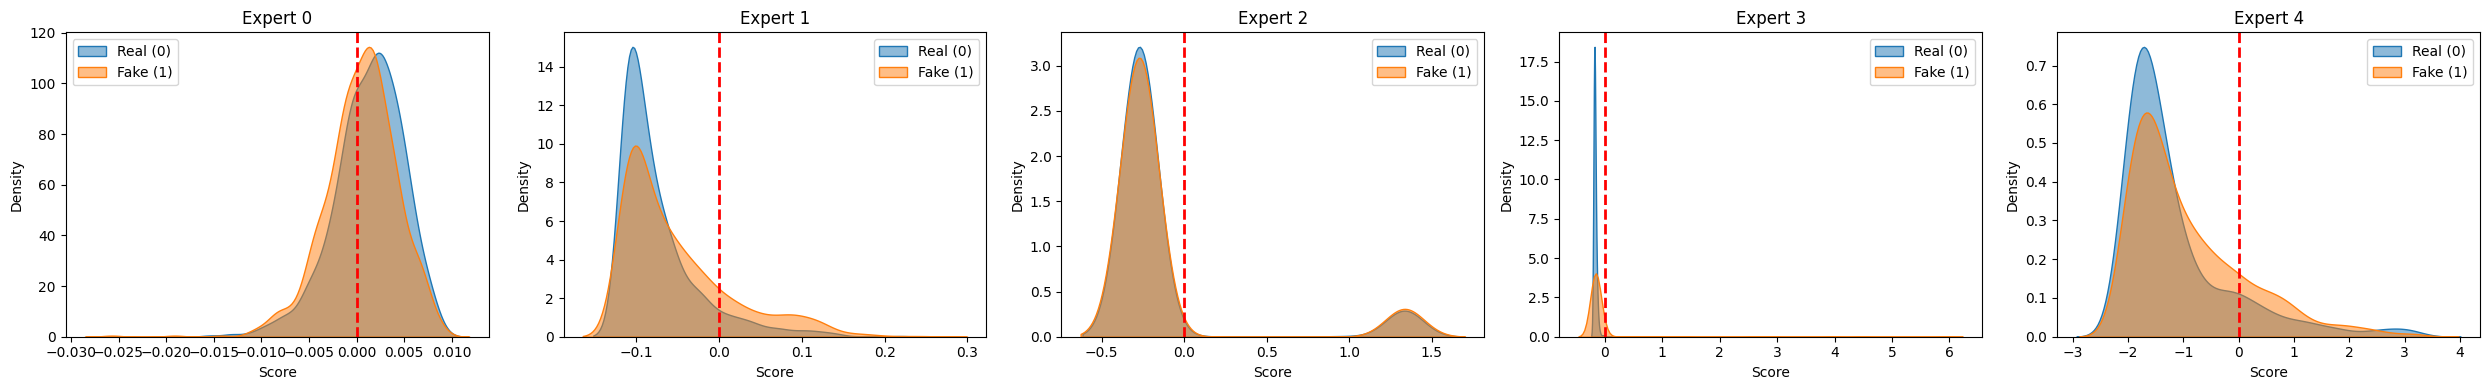


#------------ PER EXPERT (Scaled Logits) ------------#



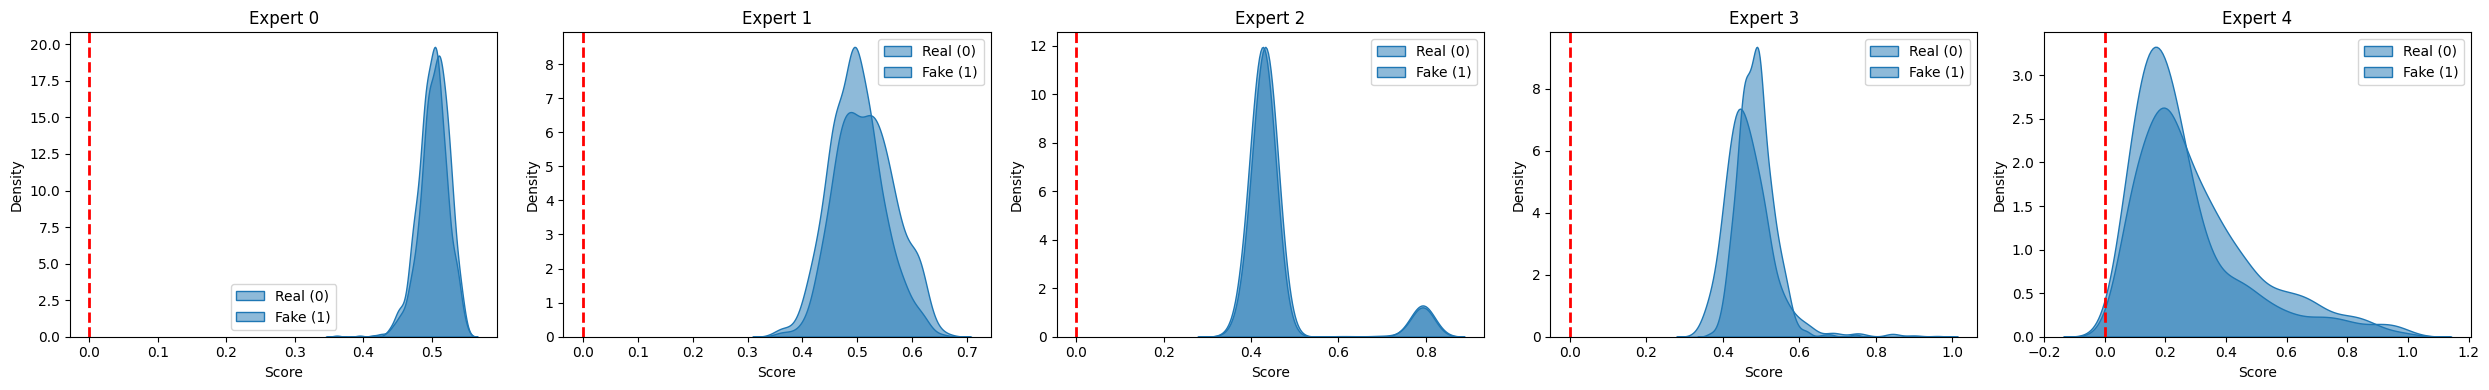


#------------ PER EXPERT (Raw Logits) ------------#



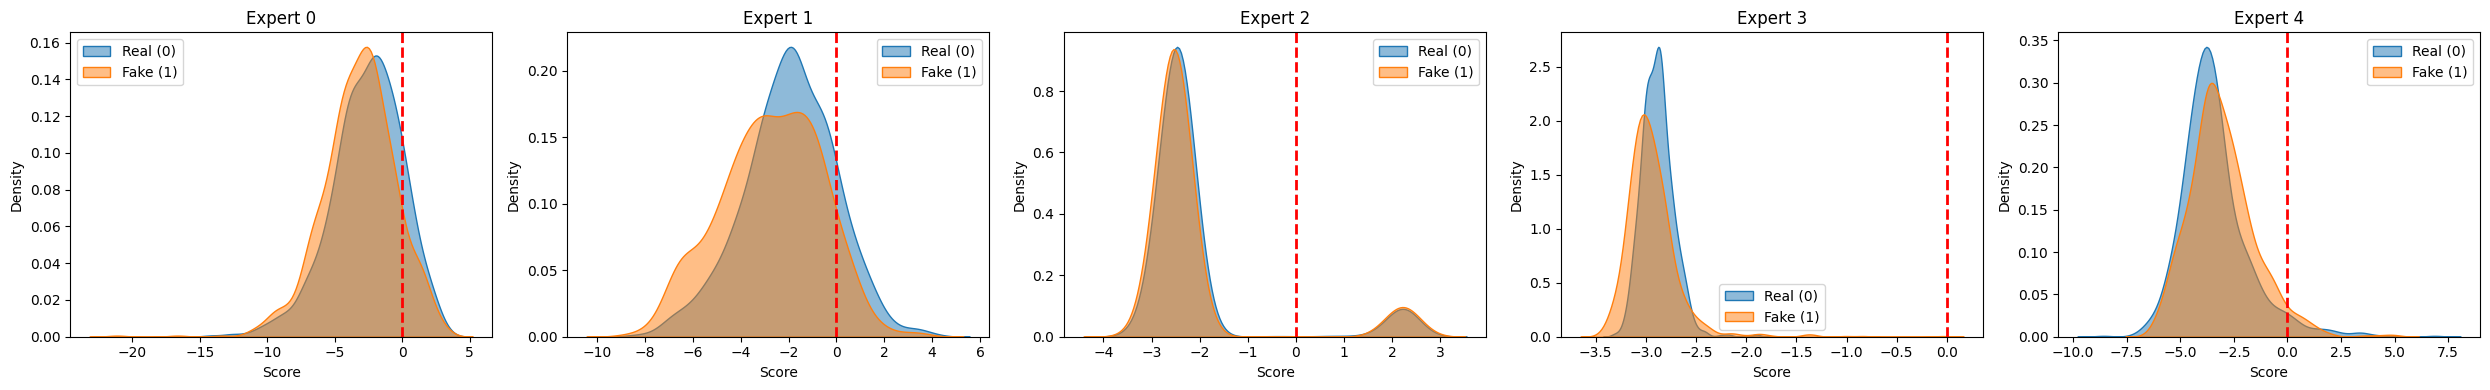


########################################################################################################################
#--------------------------------------------------------- A11 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 83.90%, EER: 25.29%
Loaded 1902 samples
Real mean score: -1.5205
Fake mean score: 1.2858



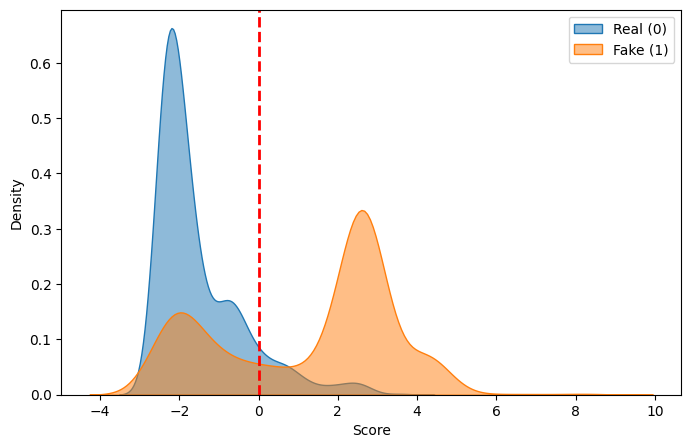


#------------ PER EXPERT (LogLR scores) ------------#



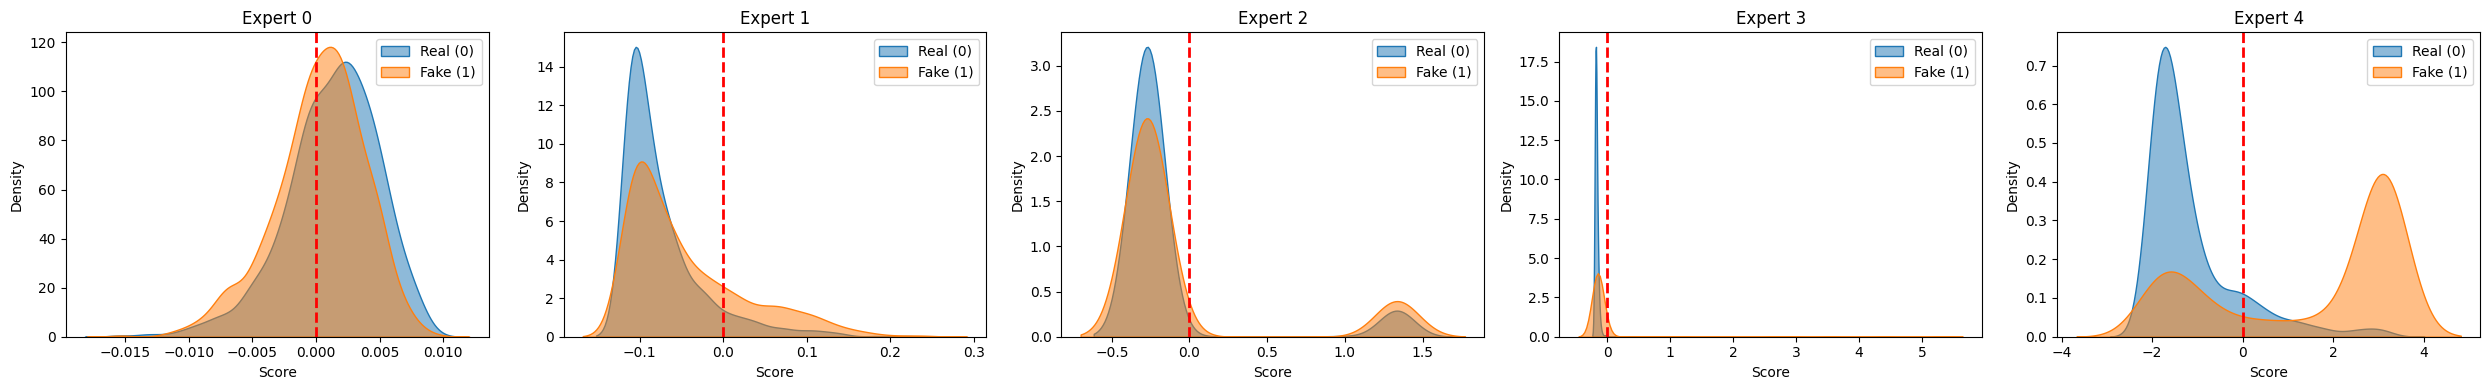


#------------ PER EXPERT (Scaled Logits) ------------#



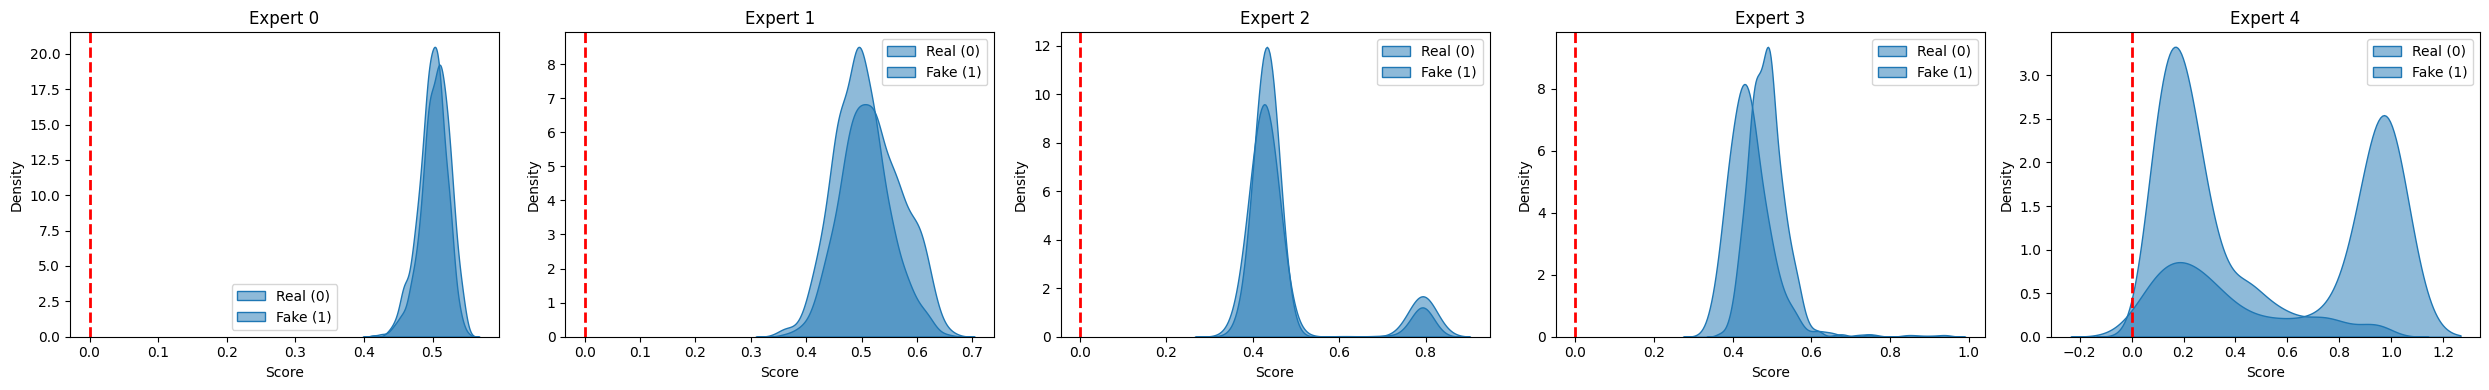


#------------ PER EXPERT (Raw Logits) ------------#



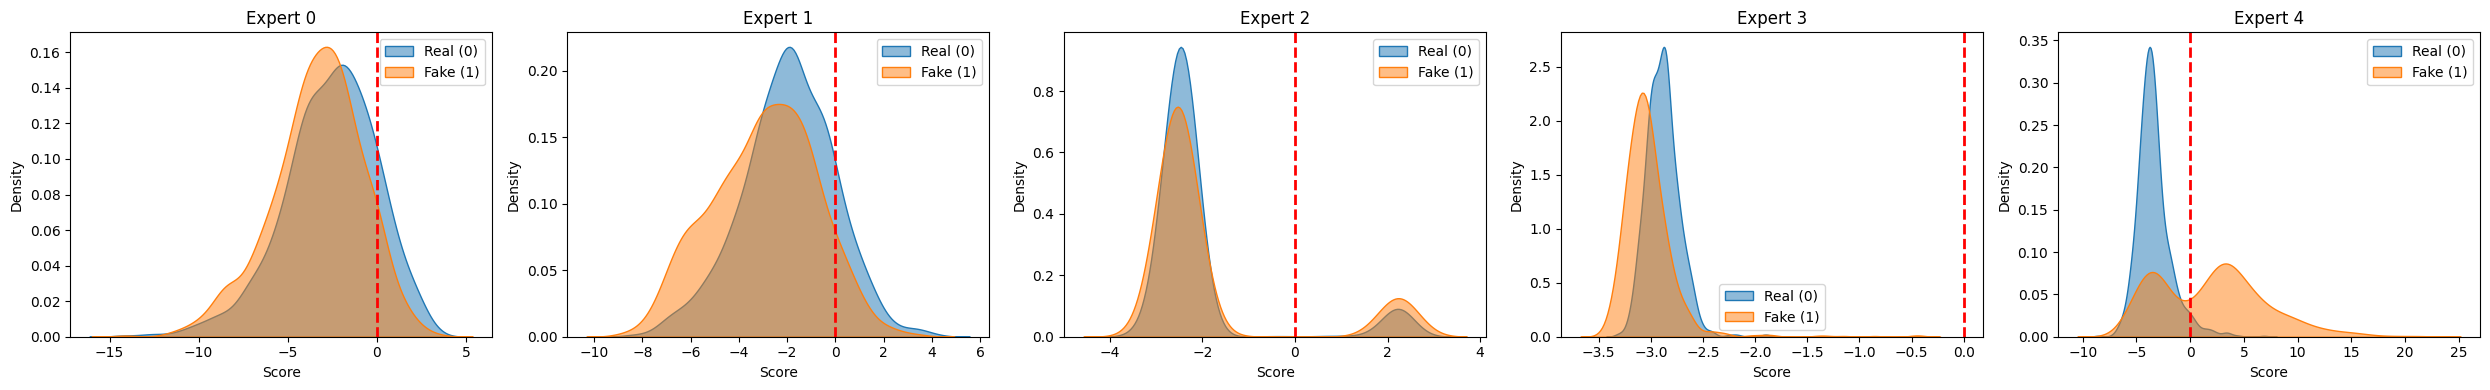


########################################################################################################################
#--------------------------------------------------------- A12 ---------------------------------------------------------#
########################################################################################################################


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

AUC: 86.91%, EER: 19.79%
Loaded 1876 samples
Real mean score: -1.5205
Fake mean score: 1.7292



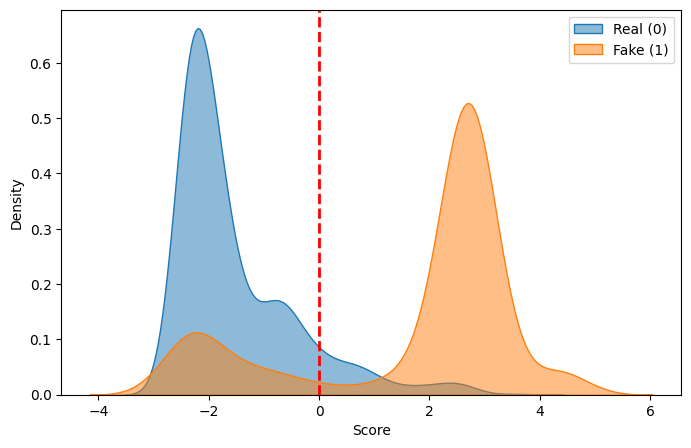


#------------ PER EXPERT (LogLR scores) ------------#



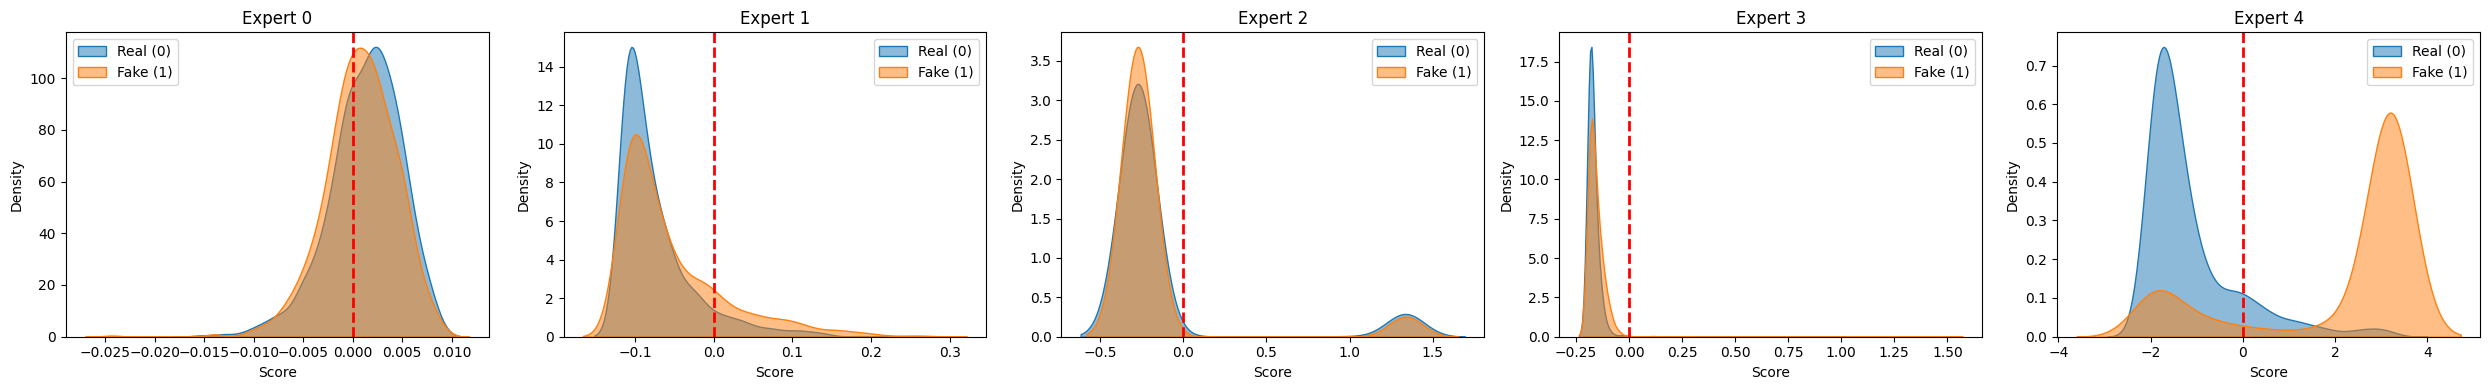


#------------ PER EXPERT (Scaled Logits) ------------#



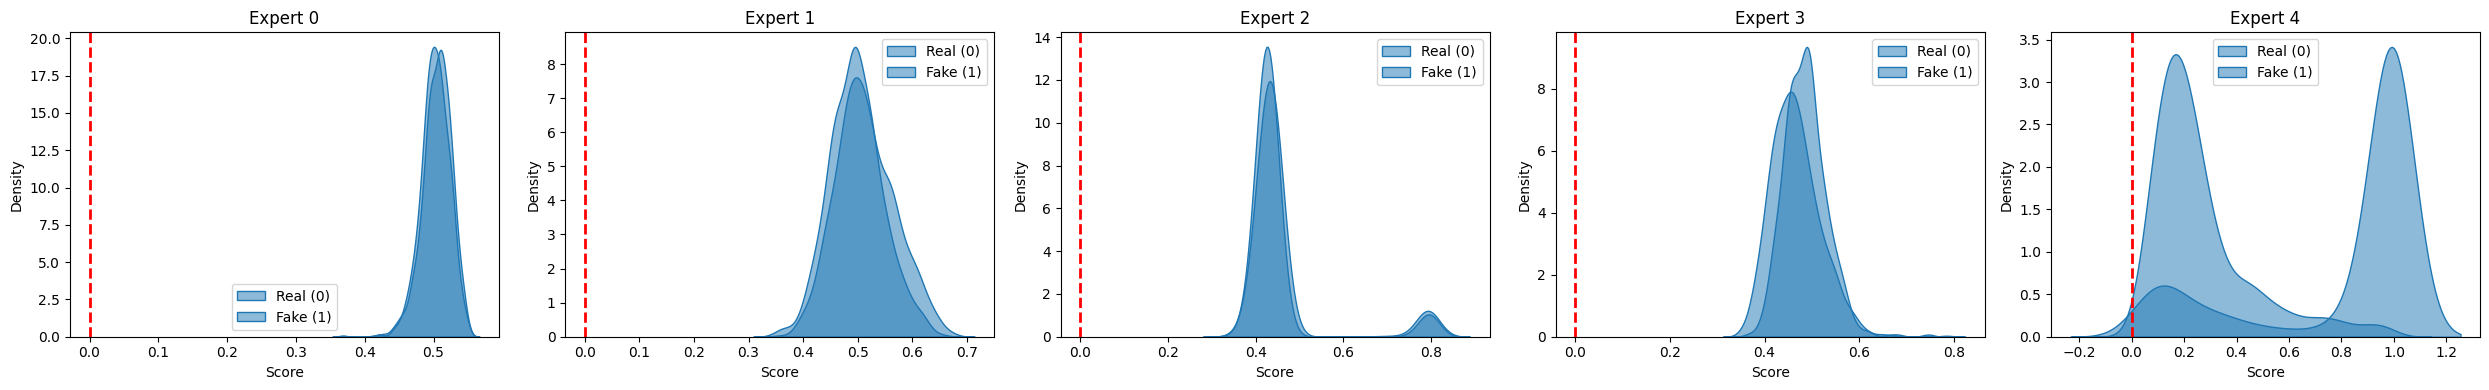


#------------ PER EXPERT (Raw Logits) ------------#



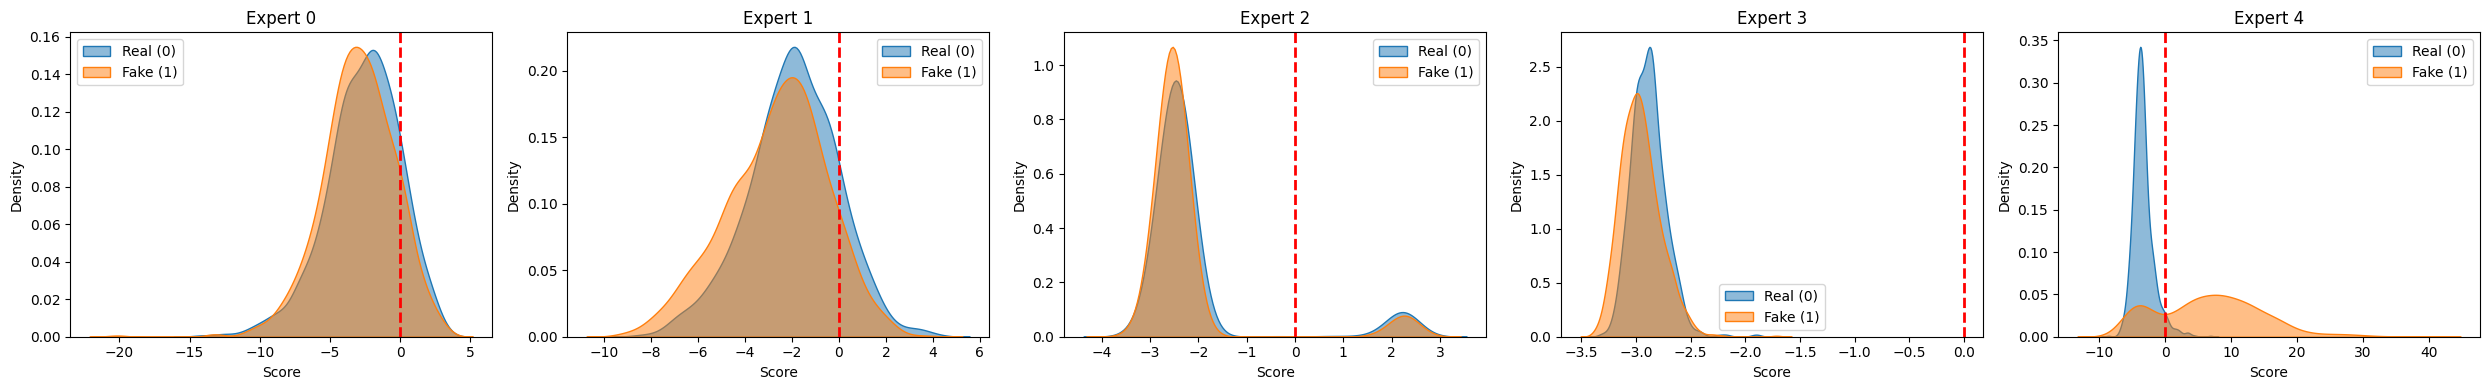

In [79]:
for g in generator_list:
    print(f"\n{'#'*120}")
    print(f"#{'-'*57} {g} {'-'*57}#")
    print(f"{'#'*120}\n")
                    
    rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/SCALE_CALIB/{g}"

    # -------- ENSEMBLE --------
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    scores = np.load(os.path.join(rootpath, "scores.npy"))
    labels = np.load(os.path.join(rootpath, "labels.npy"))
    plot_distributions(scores, labels)
    plt.show()

    # -------- PER EXPERT --------
    for title, filename in score_types:
        print(f"\n#------------ PER EXPERT ({title}) ------------#\n")

        all_scores = np.load(os.path.join(rootpath, filename))
        n_exp = all_scores.shape[0]

        fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

        for i in range(n_exp):
            ax = axes[i] if n_exp > 1 else axes
            scores = all_scores[i]

            plot_distributions(scores, labels, ax=ax, metrics=False)
            # plot_raw_scatter(scores, labels, ax=ax, metrics=False)

            ax.set_title(f"Expert {i}")

        plt.tight_layout()
        plt.show()

## Experts trained on 5, calibrated on 19 


#--------- OVERALL ENSEMBLE ---------#

AUC: 63.93%, EER: 43.57%
Loaded 19171 samples
Real mean score: -0.3600
Fake mean score: 0.3926



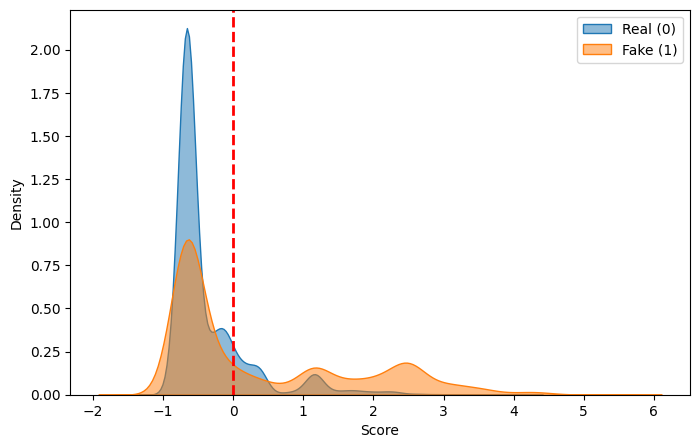


#------------ PER EXPERT ------------#



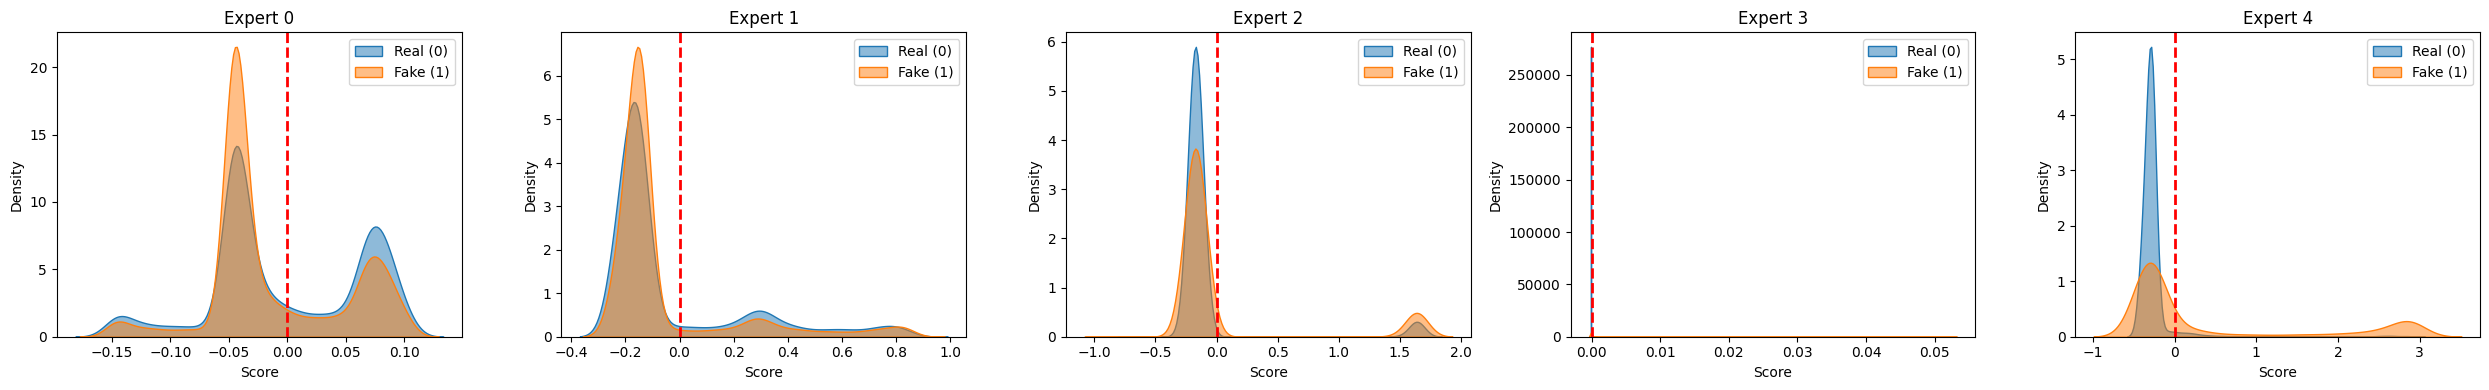

In [50]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv5/ALL"
labels = np.load(os.path.join(rootpath, "labels.npy"))

print("\n#--------- OVERALL ENSEMBLE ---------#\n")
scores = np.load(os.path.join(rootpath, "scores.npy"))
plot_distributions(scores, labels)
plt.show()

print("\n#------------ PER EXPERT ------------#\n")
all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
n_exp = all_logLR.shape[0]
fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

for i in range(n_exp):
    ax = axes[i] if n_exp > 1 else axes
    scores = all_logLR[i]

    plot_distributions(scores, labels, ax=ax, metrics=False)
    ax.set_title(f"Expert {i}")

plt.tight_layout()
plt.show()


# Test set: ASVspoof 5

## Experts trained on 19, calibrated on 5


#--------- OVERALL ENSEMBLE ---------#

AUC: 56.20%, EER: 45.20%
Loaded 25006 samples
Real mean score: -0.0492
Fake mean score: 0.0566



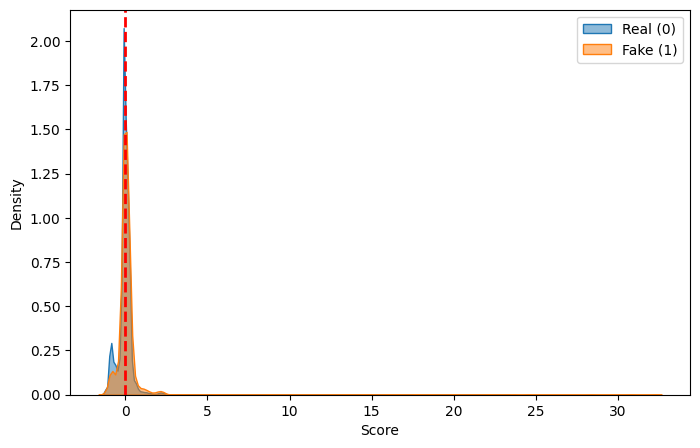


#------------ PER EXPERT ------------#



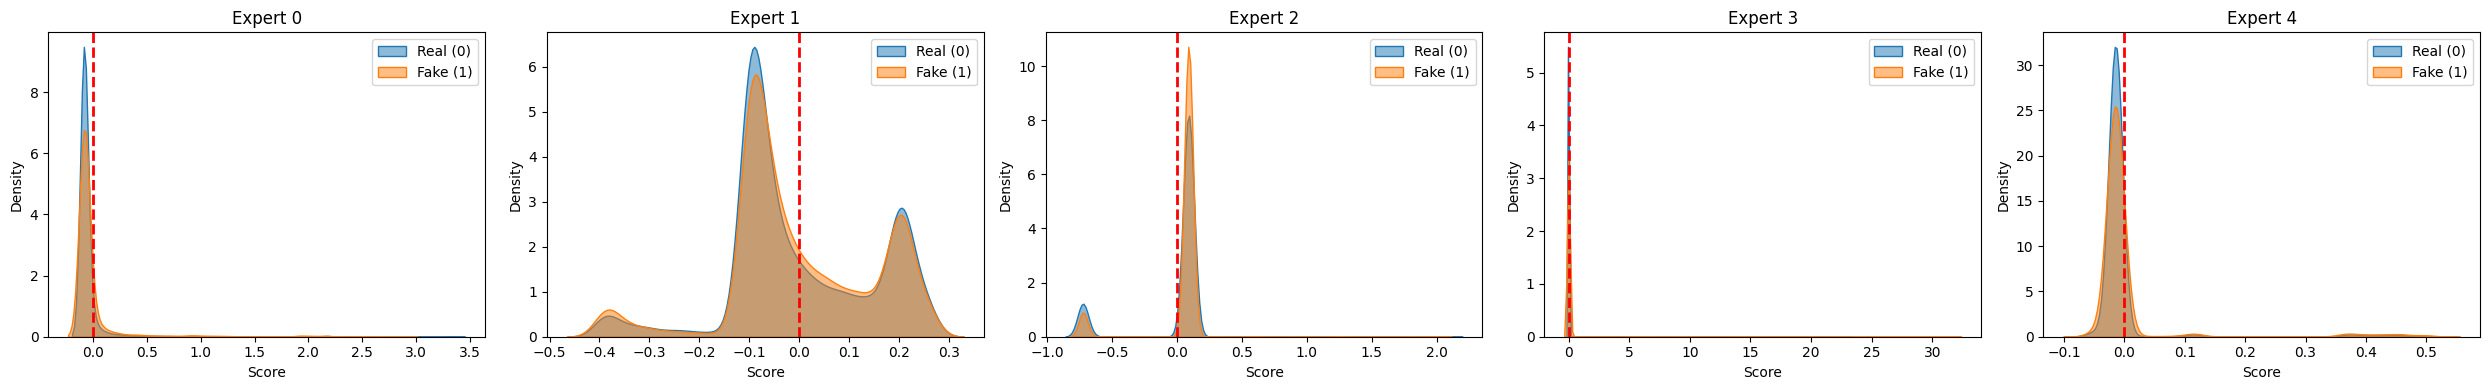

In [52]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv19"
labels = np.load(os.path.join(rootpath, "labels.npy"))

print("\n#--------- OVERALL ENSEMBLE ---------#\n")
scores = np.load(os.path.join(rootpath, "scores.npy"))
plot_distributions(scores, labels)
plt.show()

print("\n#------------ PER EXPERT ------------#\n")
all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
n_exp = all_logLR.shape[0]
fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

for i in range(n_exp):
    ax = axes[i] if n_exp > 1 else axes
    scores = all_logLR[i]
    plot_distributions(scores, labels, ax=ax, metrics=False)
    ax.set_title(f"Expert {i}")

plt.tight_layout()
plt.show()


## Experts trained on 5, calibrated on 5 


#--------- OVERALL ENSEMBLE ---------#

AUC: 59.77%, EER: 43.22%
Loaded 25006 samples
Real mean score: -0.1212
Fake mean score: 0.1742



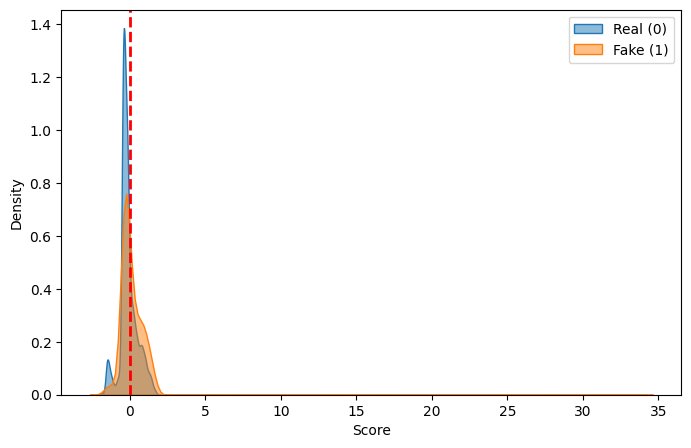


#------------ PER EXPERT ------------#



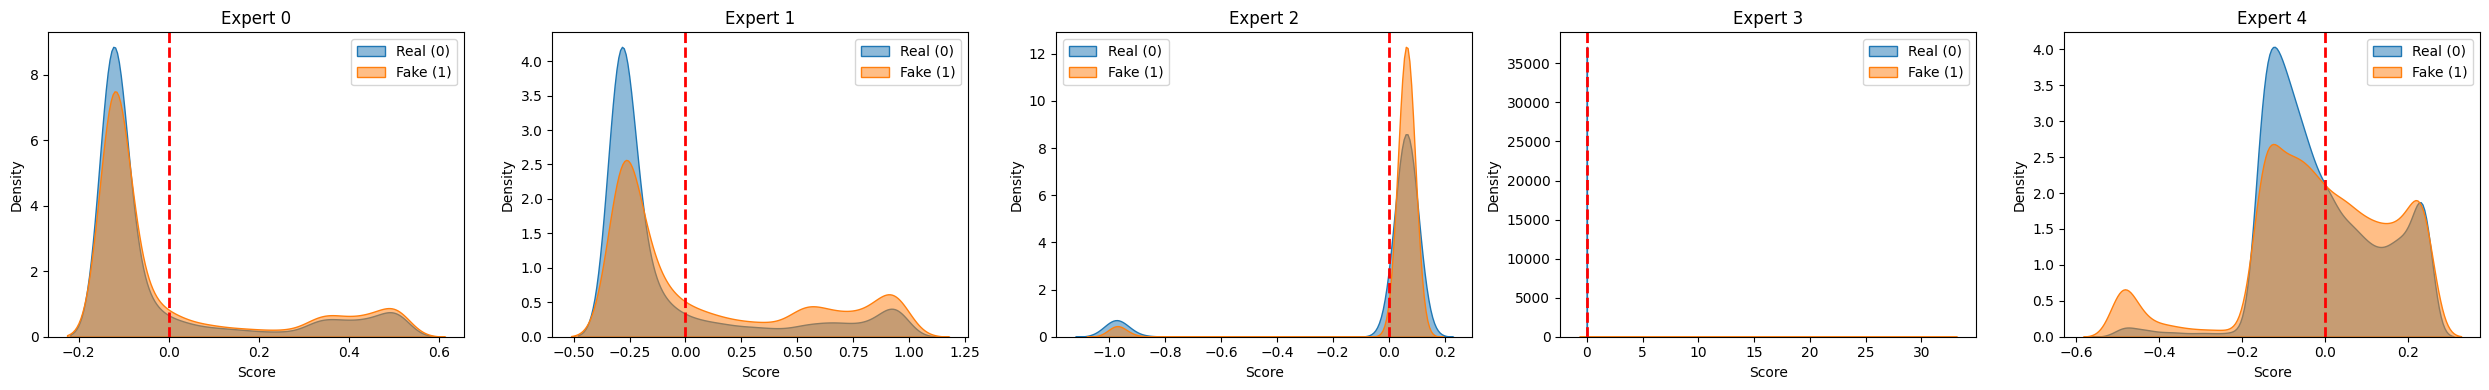

In [54]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_asv5/ALL"
labels = np.load(os.path.join(rootpath, "labels.npy"))

print("\n#--------- OVERALL ENSEMBLE ---------#\n")
scores = np.load(os.path.join(rootpath, "scores.npy"))
plot_distributions(scores, labels)
plt.show()

print("\n#------------ PER EXPERT ------------#\n")
all_logLR = np.load(os.path.join(rootpath, "scores_per_expert.npy"))
n_exp = all_logLR.shape[0]
fig, axes = plt.subplots(1, n_exp, figsize=(5*n_exp, 4))

for i in range(n_exp):
    ax = axes[i] if n_exp > 1 else axes
    scores = all_logLR[i]

    plot_distributions(scores, labels, ax=ax, metrics=False)
    ax.set_title(f"Expert {i}")

plt.tight_layout()
plt.show()
